# 2_Smart-Kage NOR analysis

This notebook takes the processed NOR data from one or more cohorts, combines them, and produces
the exploration plots, discrimination index (DI) plots and statistics comparing genotypes.

**Before you start:** run `1_SmartKage_NOR_postprocessing.ipynb` once for every cohort you want to include.
That creates a `NOR_processed` folder inside each cohort folder, which this notebook reads.


## How to use:

1. **Section 1, master settings:** set `BASE_DIR` (where the cohort folders are), `MASTER_NAME` (a name for
   this combined dataset) and `COHORTS_TO_COMBINE` (the cohort folder names). Set `DEFAULT_AGE` if the
   folder names don't contain an age.
2. **Section 2, cohort configuration:** set `AGE_ORDER`, `GENO_ORDER` and `GENO_COLORS`. The genotype names
   must match the `Description` column of `kage_descriptions.csv` exactly. Any genotype not listed here is
   left out of every plot.
3. Run the notebook from top to bottom (sections 1 to 6). The sections after 6 are older analyses
   (see below) and can be skipped.

All outputs go to `BASE_DIR/NOR_MASTER_<MASTER_NAME>/`. Rerunning a cell overwrites its old figure and tables.



## Main outputs (in `NOR_MASTER_<MASTER_NAME>/`)
- `NOR_MASTER_*.csv`: combined data from all cohorts (exploration per minute, wheel changes, first approach,
  exploration per mouse, and novel/familiar DI per mouse (sample and test))
- `analysis_summaries/`: group averages over time and DI at 20 min – 8 h per mouse
- `statistics/NOR_statistics.csv`: every statistical test (run next to the figures in 3.2, 4.3, 4.5 and 5),
  collected in section 6
- `all_figure_pdfs/`: figures as PDFs; figures that differ only in time window (e.g. 20 min, 2 h, 24 h)
  are pages of one PDF

## What each section does

**1. Build master tables.** Combines the `NOR_processed` files of all cohorts into `NOR_MASTER_*.csv` files.
Kage numbers repeat across cohorts, so every row gets a `Cohort`, an `Age` and a unique `MouseSessionID`
(cohort + kage).

**2. Configuration and loading.** Genotype/age order and colours, plot style, loading the master tables,
and tidying phase names. Every figure is saved as a PDF in `all_figure_pdfs/`;
figures that differ only in time window are pages of one PDF (set in `FIGURE_GROUPS`).

**3. Exploration.** One mouse per kage; values are seconds spent exploring either object.
- 3.1 Wheel change times: checks the wheel changes happened at similar times for every kage.
- 3.2 Total exploration in each phase, per genotype, with a genotype comparison for each phase (stars).
- 3.3 Average exploration over time (per minute) for the first 4 h, 8 h and 24 h of each phase.
- 3.3.1 Exploration around each wheel change: 2 h before to 2 h or 24 h after.
- 3.4 Cumulative exploration (running total) over 2 h, 10 h and 24 h.

**4. Discrimination index (DI).** DI = (novel − familiar) / (novel + familiar). It runs from −1 (only the
familiar object) to +1 (only the novel object); 0 means no preference. A side-bias DI
(left − right) / (left + right) checks for a general preference for one side of the kage.
- 4.1 Cumulative DI over the test phase (20 min, 2 h, 10 h, 24 h).
- 4.2 DI at 20 min, 2, 4, 6 and 8 h, one value per mouse.
- 4.3 Novel/familiar DI, sample vs test. In sample both objects are identical, so the "sample DI" (using the side that will
  hold the novel object) measures baseline side preference. It always uses the whole sample phase (first 24 h). It is
  compared with the test DI over the first 20 min (primary), 2 h (secondary) and 24 h (sensitivity).
  Mice that don't explore in the first 20 min of test have no DI and are left out of the 20 min analysis.
- 4.4 Change in DI (ΔDI) = test DI − sample DI, at 20 min, 2, 4, 6, 8 and 24 h.
- 4.5 Side-bias DI (left − right), first 24 h of each phase: sample phase compared between genotypes, and
  sample vs test within each genotype.

**5. First approach.** Which object each mouse explored first after the test wheel change (novel or
familiar), as counts and percentages per genotype, with a binomial test against 50% and a Fisher's exact test
between genotypes (stars). Then the summary tables are saved to
`analysis_summaries/`.

**6. Statistics overview.** Every test is run next to its figure (3.2, 4.3, 4.5, 5) and drawn as stars. One
value per mouse; two-sided; raw p-values.
- 6.1 Overview table of all tests, and the significant ones.
- 6.2 All results are saved to `statistics/NOR_statistics.csv`.

## Older sections (after section 6)

These were copied from earlier studies (NLGF 6-month cohorts, 30/45/60 min windows, earlier statistics and
thesis figures). They mostly repeat the analyses above or are specific to those datasets, and some need
updating before they work with this dataset. They are not needed for the main analysis.

In [135]:
import sys
print(sys.executable)

/opt/anaconda3/envs/smart-kages/bin/python


In [136]:
import pandas as pd
import numpy as np
from pathlib import Path
import re


import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d

pd.set_option("display.max_columns", 100)


## 1. Build master tables across all cohorts

In NOR_postprocessing notebook, NOR data are processed one cohort at a time.

The section below combines the processed outputs from all cohort folders into master CSV files.

This is needed because analysis could be done between different cohorts at different age group. As well as `Kage1`, `Kage2`, etc. repeat across cohorts, so each row gets:

- `Cohort`: cohort folder name
- `Age`: from the cohort folder name if it contains one
- `MouseSessionID`: unique mouse/session ID made from cohort + KageID

Before running this section, each cohort folder should already have its own `NOR_processed` folder created by running the postprocessing notebook. 

In [137]:
# ------------------------------------------------------------------
# Master settings: which cohorts to combine and where to save
# ------------------------------------------------------------------
BASE_DIR = Path("/Users/jiatongsun/SmartKages_RELN-Colbos_analysis") #<-- test cohort
MASTER_NAME = "RELN-COLBOS"            # <--- change this to a name for the combined cohorts (used in output folder names)
COHORTS_TO_COMBINE = [  
    "2025-11-Nov-Dec_RELN-COLBOS_Coh1",                # cohort folder names in BASE_DIR to include
    "2026-01-Jan-Feb_RELN-COLBOS_Coh2",
]
MASTER_OUTPUT = BASE_DIR / f"NOR_MASTER_{MASTER_NAME}"

# Age used for the master tables. A cohort with an age in its folder name (e.g. "..._NLGF12m")
# uses that age instead.
DEFAULT_AGE = "3m"

In [138]:
MASTER_OUTPUT.mkdir(exist_ok=True)

COHORT_DIRS = [BASE_DIR / name for name in COHORTS_TO_COMBINE]

for cohort_dir in COHORT_DIRS:
    status = "ok" if (cohort_dir / "NOR_processed").exists() else "MISSING NOR_processed: run postprocessing first"
    print("-", cohort_dir.name, status)
print("Master tables will be saved to:", MASTER_OUTPUT)

- 2025-11-Nov-Dec_RELN-COLBOS_Coh1 ok
- 2026-01-Jan-Feb_RELN-COLBOS_Coh2 ok
Master tables will be saved to: /Users/jiatongsun/SmartKages_RELN-Colbos_analysis/NOR_MASTER_RELN-COLBOS


In [139]:
# find an age like "12m" in the folder name, otherwise use DEFAULT_AGE
def infer_age_from_cohort(cohort_name: str) -> str:
    match = re.search(r"(\d+)m\b", cohort_name)   # an age like "12m" in the folder name
    return f"{match.group(1)}m" if match else DEFAULT_AGE



def load_cohort_output(cohort_dir: Path, filename: str) -> pd.DataFrame | None:
    """
    Load one processed output file from one cohort.
    Adds Cohort, Age and MouseSessionID.
    Returns None if the file does not exist.
    """
    cohort_name = cohort_dir.name
    age = infer_age_from_cohort(cohort_name)
    path = cohort_dir / "NOR_processed" / filename

    if not path.exists():
        print(f"Missing {filename} for {cohort_name}")
        return None

    df = pd.read_csv(path)

    df["Cohort"] = cohort_name
    df["Age"] = age

    if "KageID" in df.columns:
        df["MouseSessionID"] = (
            df["Cohort"].astype(str)
            + "_"
            + df["KageID"].astype(str)
        )

    return df

In [140]:
# Files to combine across cohorts

# master table name -> file in each cohort's NOR_processed folder
# ("binned" keeps its old name: the OiP and other notebooks read NOR_MASTER_binned.csv)
FILES_TO_COMBINE = {
    "binned": "NOR_exploration_per_minute.csv",
    "exploration_per_mouse": "NOR_exploration_per_mouse.csv",
    "DI_per_mouse": "NOR_DI_per_mouse.csv",
    "events": "NOR_wheel_changes.csv",
    "first_approach": "NOR_first_approach_per_mouse.csv",
}

master_tables = {}

for table_name, filename in FILES_TO_COMBINE.items():

    frames = []

    for cohort_dir in COHORT_DIRS:
        df = load_cohort_output(cohort_dir, filename)
        if df is not None and not df.empty:
            frames.append(df)

    if frames:
        master_tables[table_name] = pd.concat(frames, ignore_index=True)
        print(table_name, master_tables[table_name].shape)
    else:
        print(f"No data combined for {table_name}")

binned (119058, 21)
exploration_per_mouse (80, 12)
DI_per_mouse (20, 22)
events (100, 19)
first_approach (20, 9)


In [141]:
# Save master tables

for table_name, df in master_tables.items():
    out_path = MASTER_OUTPUT / f"NOR_MASTER_{table_name}.csv"
    df.to_csv(out_path, index=False)
    print("Saved:", out_path)

# Quick check of the main master table
if "binned" in master_tables:
    display(master_tables["binned"].head())
    display(master_tables["binned"].groupby(["Age", "Cohort", "Genotype", "Phase"]).size().reset_index(name="n_rows").head(20))

Saved: /Users/jiatongsun/SmartKages_RELN-Colbos_analysis/NOR_MASTER_RELN-COLBOS/NOR_MASTER_binned.csv
Saved: /Users/jiatongsun/SmartKages_RELN-Colbos_analysis/NOR_MASTER_RELN-COLBOS/NOR_MASTER_exploration_per_mouse.csv
Saved: /Users/jiatongsun/SmartKages_RELN-Colbos_analysis/NOR_MASTER_RELN-COLBOS/NOR_MASTER_DI_per_mouse.csv
Saved: /Users/jiatongsun/SmartKages_RELN-Colbos_analysis/NOR_MASTER_RELN-COLBOS/NOR_MASTER_events.csv
Saved: /Users/jiatongsun/SmartKages_RELN-Colbos_analysis/NOR_MASTER_RELN-COLBOS/NOR_MASTER_first_approach.csv


,bin,left_frames,right_frames,bin_duration_sec,left_sec,right_sec,total_sec,KageID,Genotype,Phase,rotation,window_end,bin_start,bin_end,NOR_side,cumulative_left_sec,cumulative_right_sec,cumulative_total_sec,Cohort,Age,MouseSessionID
0,0,0,0,60.0,0.0,0.0,0.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:09:24,2025-12-08 11:10:24,L,0.0,0.0,0.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1
1,1,0,10,60.0,0.0,5.0,5.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:10:24,2025-12-08 11:11:24,L,0.0,5.0,5.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1
2,2,6,20,60.0,3.0,10.0,13.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:11:24,2025-12-08 11:12:24,L,3.0,15.0,18.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1
3,3,0,0,60.0,0.0,0.0,0.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:12:24,2025-12-08 11:13:24,L,3.0,15.0,18.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1
4,4,0,0,60.0,0.0,0.0,0.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:13:24,2025-12-08 11:14:24,L,3.0,15.0,18.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1


,Age,Cohort,Genotype,Phase,n_rows
0,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1,RELN-Colbos,ITI_baseline,4345
1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1,RELN-Colbos,OiP,4405
2,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1,RELN-Colbos,pre_sample,360
3,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1,RELN-Colbos,sample,4312
4,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1,RELN-Colbos,test,4456
5,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1,WT,ITI_baseline,4334
6,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1,WT,OiP,4306
7,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1,WT,pre_sample,360
8,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1,WT,sample,4292
9,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1,WT,test,4486


## 2. Cohort Configuration

In [142]:
AGE_ORDER = ["3m"]
GENO_ORDER = ["WT", "RELN-Colbos"]
PHASE_ORDER = ["sample", "ITI_baseline", "test"]

GENO_COLORS = {
    "WT": "blue",
    "RELN-Colbos": "red",
    # "APP1-em1BDS": "#FF8C00",
    # "NLF": "#9B5DE5",
}

FIRST_APPROACH_COLORS = {
    "novel": "#2EC4C7",
    "familiar": "#F28CC8",
}

SMOOTH_SIGMA = 2
ROW_DURATION = 0.5  # one drum-output row is 0.5 s
PHASE_CAP_MIN = 24 * 60   # whole-phase measures (totals, sample DI) use at most the first 24 h of a phase

## 2.1 Figure formatting and constants

In [143]:
mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.family": "Arial",
    "axes.grid": False,
    "font.size": 18,
    "axes.labelsize": 20,
    "axes.titlesize": 22,
    "xtick.labelsize": 17,
    "ytick.labelsize": 17,
    "legend.fontsize": 16,
    "axes.linewidth": 1.2,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "savefig.transparent": True,
    "savefig.bbox": "tight",
})

FIG_W = 10
FIG_H = 8
WIDE_W = 25
WIDE_H = 15


def format_axes(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.2)
    ax.spines["bottom"].set_linewidth(1.2)
    ax.tick_params(axis="both", direction="in", width=1.2, length=5, pad=6)
    ax.set_facecolor("white")
    return ax


def sem(x):
    return x.sem()


def clean_phase_label(x):
    return str(x).replace("_", " ").capitalize()


## 2.2 Load MASTER NOR data
Reads the master tables built above, from `MASTER_OUTPUT`.

Expected files:

- `NOR_MASTER_binned.csv`: exploration per minute (main table)
- `NOR_MASTER_events.csv`: wheel changes (the post-trial baseline is dropped when loading)
- `NOR_MASTER_first_approach.csv`: first approach per mouse

Also saved, but not read here (ready-made tables for statistics or Prism, all cohorts together):
- `NOR_MASTER_exploration_per_mouse.csv`: left / right / total exploration per mouse and phase (first 24 h)
- `NOR_MASTER_DI_per_mouse.csv`: sample DI, test DI at 20 min / 2 h / 24 h and ΔDI, one row per mouse

The notebook recomputes most summaries from `NOR_MASTER_binned.csv` so age, genotype and phase are never accidentally pooled.


In [144]:
MASTER_BINNED = MASTER_OUTPUT / "NOR_MASTER_binned.csv"
MASTER_EVENTS = MASTER_OUTPUT / "NOR_MASTER_events.csv"
MASTER_FIRST = MASTER_OUTPUT / "NOR_MASTER_first_approach.csv"

binned_df = pd.read_csv(MASTER_BINNED)

if MASTER_EVENTS.exists():
    events = pd.read_csv(MASTER_EVENTS)
    events = events[events["Phase"].ne("post_trial_baseline")].copy()   # not part of the main analysis
else:
    events = None
    print("Warning: NOR_MASTER_events.csv not found. Event-aligned before/after plots need this file.")

if MASTER_FIRST.exists():
    first_approach_df = pd.read_csv(MASTER_FIRST)
else:
    first_approach_df = None
    print("Warning: NOR_MASTER_first_approach.csv not found.")

print("binned_df shape:", binned_df.shape)
binned_df.head()


binned_df shape: (119058, 21)


,bin,left_frames,right_frames,bin_duration_sec,left_sec,right_sec,total_sec,KageID,Genotype,Phase,rotation,window_end,bin_start,bin_end,NOR_side,cumulative_left_sec,cumulative_right_sec,cumulative_total_sec,Cohort,Age,MouseSessionID
0,0,0,0,60.0,0.0,0.0,0.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:09:24,2025-12-08 11:10:24,L,0.0,0.0,0.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1
1,1,0,10,60.0,0.0,5.0,5.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:10:24,2025-12-08 11:11:24,L,0.0,5.0,5.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1
2,2,6,20,60.0,3.0,10.0,13.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:11:24,2025-12-08 11:12:24,L,3.0,15.0,18.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1
3,3,0,0,60.0,0.0,0.0,0.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:12:24,2025-12-08 11:13:24,L,3.0,15.0,18.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1
4,4,0,0,60.0,0.0,0.0,0.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:13:24,2025-12-08 11:14:24,L,3.0,15.0,18.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1


In [145]:

# ==========================================================
# PDF EXPORT FOR EVERY FIGURE IN THIS NOTEBOOK
# ==========================================================

from matplotlib.backends.backend_pdf import PdfPages
import re

FIGURE_PDF_DIR = MASTER_OUTPUT / "all_figure_pdfs"
FIGURE_PDF_DIR.mkdir(parents=True, exist_ok=True)

ALL_FIGURES_PDF_PATH = MASTER_OUTPUT / "SmartKage_NOR_all_figures.pdf"

_FIGURES_BY_NAME = {}   # latest figure per name; a re-run cell replaces its old figure
_FIGURE_PDF_COUNTER = 0

# Figures that show the same thing for different time windows (20 min, 2 h, 24 h ...) are saved as pages
# of one PDF. Key = pattern in the figure's file name, value = name of the multi-page PDF.
# Figures that match no pattern are saved as their own PDF.
FIGURE_GROUPS = {
    r"^Average_exploration_.*_stacked": "Average_exploration_stacked",
    r"^Average_exploration_.*_grid": "Average_exploration_grid",
    r"around_wheel_change.*_stacked": "Exploration_around_wheel_change_stacked",
    r"around_wheel_change.*_grid": "Exploration_around_wheel_change_grid",
    r"^Cumulative_exploration_over_": "Cumulative_exploration",
    r"^Cumulative_novelfamiliar_DI_": "Cumulative_novel_familiar_DI",
    r"^Cumulative_side-bias_DI_": "Cumulative_side_bias_DI",
    r"^Novelfamiliar_DI_test_": "Novel_familiar_DI_sample_vs_test",
}
_GROUP_PAGES = {}   # group -> {figure name: figure}, in the order the figures were made


def _safe_pdf_name(text):
    """Convert a figure title into a filesystem-safe filename."""
    text = str(text).strip()
    text = re.sub(r"\s+", "_", text)
    text = re.sub(r"[^A-Za-z0-9_.-]+", "", text)
    return text[:120] or "figure"


def save_figure_pdf(fig=None, name=None):
    """
    Save the current figure to FIGURE_PDF_DIR.
      - If its name matches a pattern in FIGURE_GROUPS, it becomes a page of that group's PDF
        (the whole group PDF is rewritten, so re-running a cell replaces its page).
      - Otherwise it is saved as its own PDF.

    Called just before every plt.show().
    """
    global _FIGURE_PDF_COUNTER

    if fig is None:
        fig = plt.gcf()

    # Do not save an empty placeholder figure.
    if fig is None or not fig.get_axes():
        return None

    _FIGURE_PDF_COUNTER += 1

    if name is None:
        title = fig._suptitle.get_text() if fig._suptitle is not None else ""

        if not title and fig.axes:
            title = fig.axes[0].get_title()

        name = title or f"figure_{_FIGURE_PDF_COUNTER:03d}"

    stem = _safe_pdf_name(name)
    _FIGURES_BY_NAME[f"{stem}.pdf"] = fig

    group = next((g for pattern, g in FIGURE_GROUPS.items() if re.search(pattern, stem)), None)

    if group is None:
        path = FIGURE_PDF_DIR / f"{stem}.pdf"
        fig.savefig(path, format="pdf", bbox_inches="tight")
        print(f"Saved PDF: {path.name}")
        return path

    pages = _GROUP_PAGES.setdefault(group, {})
    pages[stem] = fig
    path = FIGURE_PDF_DIR / f"{group}.pdf"
    with PdfPages(path) as pdf:
        for page in pages.values():
            pdf.savefig(page, bbox_inches="tight")
    print(f"Saved PDF: {path.name} (page {list(pages).index(stem) + 1}: {stem})")
    return path


print("Figure PDFs will be saved to:")
print(FIGURE_PDF_DIR)
print("Figures that differ only in time window are combined into one multi-page PDF (see FIGURE_GROUPS).")


Figure PDFs will be saved to:
/Users/jiatongsun/SmartKages_RELN-Colbos_analysis/NOR_MASTER_RELN-COLBOS/all_figure_pdfs
Figures that differ only in time window are combined into one multi-page PDF (see FIGURE_GROUPS).


## 2.3 Clean columns and phase labels

The master table should already contain `Age`, `Cohort`, `Genotype`, `MouseSessionID` and `Phase`.

This cell standardises phase names and keeps only the main analysis phases:

- sample
- ITI_baseline
- test
- OiP (optional)

The post-trial baseline is excluded from the main analysis.


In [146]:
# Standardise core text columns
for col in ["Age", "Genotype", "Phase", "KageID", "Cohort", "MouseSessionID"]:

        binned_df[col] = binned_df[col].astype(str).str.strip()

# Make sure bin is numeric and minutes
binned_df["bin"] = pd.to_numeric(binned_df["bin"], errors="coerce")
binned_df = binned_df.dropna(subset=["bin"]).copy()
binned_df["bin"] = binned_df["bin"].astype(int)
binned_df["time_min"] = binned_df["bin"]
binned_df["time_hr"] = binned_df["bin"] / 60

# Keep main NOR phases only for most plots
main_binned = binned_df[binned_df["Phase"].isin(PHASE_ORDER)].copy()

print("Ages:", sorted(main_binned["Age"].unique()))
print("Genotypes:", sorted(main_binned["Genotype"].unique()))
print("Phases:", main_binned["Phase"].value_counts())
main_binned.head()


Ages: ['3m']
Genotypes: ['RELN-Colbos', 'WT']
Phases: Phase
test            29791
ITI_baseline    28891
sample          28837
Name: count, dtype: int64


,bin,left_frames,right_frames,bin_duration_sec,left_sec,right_sec,total_sec,KageID,Genotype,Phase,rotation,window_end,bin_start,bin_end,NOR_side,cumulative_left_sec,cumulative_right_sec,cumulative_total_sec,Cohort,Age,MouseSessionID,time_min,time_hr
0,0,0,0,60.0,0.0,0.0,0.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:09:24,2025-12-08 11:10:24,L,0.0,0.0,0.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,0,0.000000
1,1,0,10,60.0,0.0,5.0,5.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:10:24,2025-12-08 11:11:24,L,0.0,5.0,5.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,1,0.016667
2,2,6,20,60.0,3.0,10.0,13.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:11:24,2025-12-08 11:12:24,L,3.0,15.0,18.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,2,0.033333
3,3,0,0,60.0,0.0,0.0,0.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:12:24,2025-12-08 11:13:24,L,3.0,15.0,18.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,3,0.050000
4,4,0,0,60.0,0.0,0.0,0.0,Kage1,WT,ITI_baseline,2025-12-08 11:09:24,2025-12-09 11:09:26,2025-12-08 11:13:24,2025-12-08 11:14:24,L,3.0,15.0,18.0,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,4,0.066667


## 2.4 Statistics helpers

Functions used by the tests in sections 4 and 6. All tests are two-sided and use one value per mouse.
- Unpaired (two genotypes): Shapiro-Wilk on each group, then Welch t-test (both normal) or Mann-Whitney U.
- Paired (sample vs test): Shapiro-Wilk on the differences, then paired t-test (normal) or Wilcoxon signed-rank.
- Groups with fewer than 3 mice are not tested.
- Stars: * p < 0.05, ** p < 0.01, *** p < 0.001, **** p < 0.0001, ns = not significant.

In [147]:
from scipy import stats


def p_stars(p):
    if pd.isna(p):
        return "NA"
    if p < 0.0001:
        return "****"
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"


def compare_two_groups(x, y):
    """Unpaired comparison of x vs y (one value per mouse).

    Shapiro-Wilk on each group: Welch t-test if both look normal, otherwise Mann-Whitney U.
    Effect size: Hedges' g (t-test) or rank-biserial r (Mann-Whitney); positive = x larger.
    """
    x = pd.to_numeric(pd.Series(x), errors="coerce").dropna().to_numpy(float)
    y = pd.to_numeric(pd.Series(y), errors="coerce").dropna().to_numpy(float)
    row = {"n_1": len(x), "n_2": len(y),
           "mean_1": x.mean() if len(x) else np.nan, "mean_2": y.mean() if len(y) else np.nan,
           "median_1": np.median(x) if len(x) else np.nan, "median_2": np.median(y) if len(y) else np.nan,
           "test": "not tested (fewer than 3 mice in a group)", "statistic": np.nan,
           "effect_size": np.nan, "effect_size_type": "", "p": np.nan}
    if len(x) < 3 or len(y) < 3:
        return row

    normal = stats.shapiro(x).pvalue > 0.05 and stats.shapiro(y).pvalue > 0.05
    if normal:
        result = stats.ttest_ind(x, y, equal_var=False)
        pooled_sd = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
        correction = 1 - 3 / (4 * (len(x) + len(y)) - 9)
        row.update(test="Welch t-test", effect_size=(x.mean() - y.mean()) / pooled_sd * correction,
                   effect_size_type="Hedges' g")
    else:
        result = stats.mannwhitneyu(x, y, alternative="two-sided")
        row.update(test="Mann-Whitney U", effect_size=2 * result.statistic / (len(x) * len(y)) - 1,
                   effect_size_type="rank-biserial r")
    row.update(statistic=result.statistic, p=result.pvalue)
    return row

genotype_1, genotype_2 = GENO_ORDER[0], GENO_ORDER[1]   # the two genotypes compared in unpaired tests


def paired_sample_vs_test(df, value_col, analysis, window):
    """Paired sample vs test comparison within each age and genotype (one value per mouse and phase).

    Shapiro-Wilk on the differences (test - sample): paired t-test if normal, otherwise Wilcoxon signed-rank.
    Two-sided, raw p-values (no correction). Pairs with fewer than 3 mice are not tested.
    Effect size: Cohen's dz = mean change / SD of change.
    """
    rows = []
    for age in AGE_ORDER:
        for genotype in GENO_ORDER:
            paired = (
                df[df["Age"].eq(age) & df["Genotype"].eq(genotype)]
                .pivot_table(index="MouseSessionID", columns="Phase", values=value_col, aggfunc="first")
                .reindex(columns=["sample", "test"])
                .dropna()
            )
            n = len(paired)
            diff = paired["test"] - paired["sample"]
            row = {
                "analysis": analysis, "test_window": window, "Age": age, "Genotype": genotype,
                "n_pairs": n, "sample_mean": paired["sample"].mean(), "test_mean": paired["test"].mean(),
                "mean_change": diff.mean(), "shapiro_p_diff": np.nan, "normal": np.nan,
                "test": "not tested (fewer than 3 mice)", "statistic": np.nan,
                "effect_size": np.nan, "effect_size_type": "", "p": np.nan,
            }
            if n >= 3:
                shapiro_p = stats.shapiro(diff).pvalue if diff.nunique() > 1 else np.nan
                normal = bool(shapiro_p > 0.05)
                if normal:
                    result = stats.ttest_rel(paired["test"], paired["sample"])
                    test_name = "paired t-test"
                else:
                    try:
                        result = stats.wilcoxon(paired["test"], paired["sample"], alternative="two-sided")
                        test_name = "Wilcoxon signed-rank"
                    except ValueError:      # e.g. every difference is zero
                        result, test_name = None, "Wilcoxon not possible"
                row.update(
                    shapiro_p_diff=shapiro_p, normal=normal, test=test_name,
                    statistic=result.statistic if result is not None else np.nan,
                    p=result.pvalue if result is not None else np.nan,
                    effect_size=diff.mean() / diff.std() if diff.std() > 0 else np.nan,
                    effect_size_type="Cohen's dz",
                )
            row["stars"] = p_stars(row["p"])
            rows.append(row)
    return pd.DataFrame(rows)


def draw_star_bracket(ax, x1, x2, y, label, height=0.04, fontsize=14):
    """Bracket from x1 to x2 at height y with the significance label on top."""
    ax.plot([x1, x1, x2, x2], [y, y + height, y + height, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y + height, label, ha="center", va="bottom", fontsize=fontsize)

## 3. Main Analysis Loop
 
 Helper functions for grouped time-series plots

- Summaries are grouped by `Age`, `Genotype`, `Phase` and time

In [148]:
def rebin_timeseries(data, value_cols, bin_factor=1, cutoff_min=None):
    """Re-bin per mouse/session before taking group means.

    If bin_factor=1, each bin is 1 min.
    If bin_factor=5, data are collapsed into 5-min bins.
    """
    df = data.copy()
    if cutoff_min is not None:
        df = df[df["time_min"] < cutoff_min].copy()

    df["time_bin"] = (df["time_min"] // bin_factor) * bin_factor

    group_cols = ["MouseSessionID", "KageID", "Cohort", "Age", "Genotype", "Phase", "rotation", "time_bin"]
    available_group_cols = [c for c in group_cols if c in df.columns]

    agg = {col: (col, "sum") for col in value_cols if col in df.columns}

    return (
        df.groupby(available_group_cols, as_index=False)
          .agg(**agg)
          .rename(columns={"time_bin": "time_min"})
    )


def summarise_timeseries(data, value_col):
    return (
        data
        .groupby(["Age", "Genotype", "Phase", "time_min"], as_index=False)
        .agg(
            mean_value=(value_col, "mean"),
            sem_value=(value_col, "sem"),
            n=(value_col, "count")
        )
    )


def plot_age_phase_grid(summary, y_label, title, cutoff_min, sigma=SMOOTH_SIGMA, ylim=None, xmin=0,
                        smooth_mode="reflect"):
    """3x3 grid: rows = age, columns = phase, lines = genotype.

    sigma: Gaussian smoothing width in bins (minutes); smooth_mode: how the curve ends are handled
    ("nearest" suits cumulative curves).
    """
    fig, axes = plt.subplots(
        len(AGE_ORDER),
        len(PHASE_ORDER),
        figsize=(18, 5* len(AGE_ORDER)),
        sharex=True,
        sharey=True,
        squeeze=False
    )

    for r, age in enumerate(AGE_ORDER):
        for c, phase in enumerate(PHASE_ORDER):
            ax = axes[r, c]
            sub = summary[(summary["Age"] == age) & (summary["Phase"] == phase)].copy()

            for genotype in GENO_ORDER:
                temp = sub[sub["Genotype"] == genotype].sort_values("time_min")
                if temp.empty:
                    continue

                y = gaussian_filter1d(temp["mean_value"].values, sigma=sigma, mode=smooth_mode)
                e = gaussian_filter1d(temp["sem_value"].fillna(0).values, sigma=sigma, mode=smooth_mode)

                ax.plot(
                    temp["time_min"],
                    y,
                    color=GENO_COLORS.get(genotype, "black"),
                    label=genotype,
                    linewidth=2
                )

                ax.fill_between(
                    temp["time_min"],
                    y - e,
                    y + e,
                    color=GENO_COLORS.get(genotype, "black"),
                    alpha=0.18
                )

            format_axes(ax)
            ax.set_xlim(xmin, cutoff_min)
            if xmin < 0:
                ax.axvline(0, color="black", linestyle="--", linewidth=1)
            if ylim is not None:
                ax.set_ylim(*ylim)

            if r == 0:
                ax.set_title(clean_phase_label(phase))
            if c == 0:
                ax.set_ylabel(f"{age} {y_label.strip()}")
            if r == len(AGE_ORDER) - 1:
                ax.set_xlabel("Time from wheel change (min)")

    handles, labels = axes[0, -1].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        frameon=False,
        loc="upper right",
        bbox_to_anchor=(0.98, 0.98)
    )
    
    fig.suptitle(f"{title} ({', '.join(AGE_ORDER)})", y=1.02)
    plt.tight_layout(rect=[0, 0, 0.92, 0.98])
    save_figure_pdf()
    plt.show()


## 3.1 Wheel change timestamps

This section examines when wheel changes occurred for each NOR phase.

Purpose:
- Check whether wheel changes happened at consistent times across mice.
- Identify any sessions with unusually early or late wheel changes.
- Confirm that differences in behavioural measures are not explained by large differences in the timing of wheel changes.

Plot:
- Each point represents one wheel change for one mouse.

Saved PDF: Timing_of_Wheel_Changes_across_mice.pdf


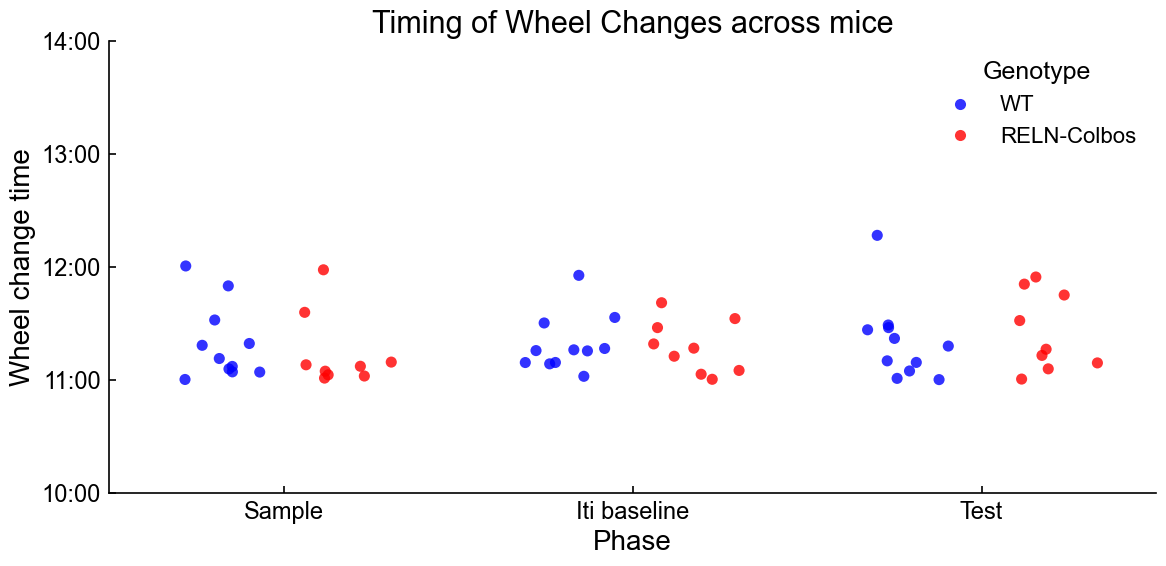

In [149]:
# Wheel change timing QC plot

wheel_times = events.rename(columns={"Description": "Genotype"})   
# events table keeps the kage_descriptions name


wheel_times["rotation"] = pd.to_datetime(wheel_times["rotation"])
wheel_times["clock_time"] = (
    wheel_times["rotation"].dt.hour
    + wheel_times["rotation"].dt.minute / 60
    + wheel_times["rotation"].dt.second / 3600
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.stripplot(
    data=wheel_times,
    x="Phase",
    y="clock_time",
    hue="Genotype",
    order=PHASE_ORDER,
    hue_order=GENO_ORDER,
    palette=GENO_COLORS,
    dodge=True,
    jitter=0.3,
    size=8,
    alpha=0.8,
    ax=ax
)

format_axes(ax)

ax.set_xticks(range(len(PHASE_ORDER)))
ax.set_xticklabels([clean_phase_label(p) for p in PHASE_ORDER])

ax.set_ylabel("Wheel change time")
ax.set_xlabel("Phase")
ax.set_title("Timing of Wheel Changes across mice")

# fixed clock time axis, 10:00 to 14:00
ax.set_ylim(10, 14)
ax.set_yticks([10, 11, 12, 13, 14])
ax.set_yticklabels(["10:00", "11:00", "12:00", "13:00", "14:00"])


ax.legend(
    title="Genotype",
    frameon=False
)

plt.tight_layout()
save_figure_pdf()
plt.show()


## 3.2 Total exploration 

This plot compares total exploration (first 24 h) for each phase between genotypes, with the statistics
drawn as stars.



In [150]:
# first 24 h of each phase (phases end at the next wheel change, so some are a little longer)
phase_total = (
    main_binned[main_binned["time_min"].lt(PHASE_CAP_MIN)]
    .groupby(["MouseSessionID", "KageID", "Cohort", "Age", "Genotype", "Phase"], as_index=False)["total_sec"]
    .sum()
)

phase_total.head()

,MouseSessionID,KageID,Cohort,Age,Genotype,Phase,total_sec
0,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,ITI_baseline,173.0
1,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,sample,712.5
2,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,test,246.0
3,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage3,Kage3,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,ITI_baseline,309.5
4,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage3,Kage3,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,sample,884.0


## Statistics: total exploration

For each phase, the two genotypes are compared (unpaired): Shapiro-Wilk on each genotype, then Welch t-test
(both normal) or Mann-Whitney U. Two-sided, raw p-values; each phase is tested on its own. The stars are drawn
on the figure below.

In [151]:
# Total exploration: genotype_1 vs genotype_2 in each phase (unpaired, two-sided, raw p-values).
# Normality is checked first (Shapiro-Wilk on each genotype; shapiro_p_1 / shapiro_p_2 in the table).
# Both normal -> unpaired t-test (Welch, does not assume equal variances); otherwise Mann-Whitney U.
# Each phase is tested on its own (no correction across phases).
total_exploration_rows = []
for age in AGE_ORDER:
    for phase in PHASE_ORDER:
        sub = phase_total[phase_total["Age"].eq(age) & phase_total["Phase"].eq(phase)]
        x = sub.loc[sub["Genotype"].eq(genotype_1), "total_sec"].dropna()
        y = sub.loc[sub["Genotype"].eq(genotype_2), "total_sec"].dropna()
        shapiro_p_1 = stats.shapiro(x).pvalue if len(x) >= 3 else np.nan
        shapiro_p_2 = stats.shapiro(y).pvalue if len(y) >= 3 else np.nan
        row = compare_two_groups(x, y)
        total_exploration_rows.append({
            "analysis": "Total exploration (between genotypes)", "Age": age, "Phase": phase,
            "test_window": "24 h", "comparison": f"{genotype_1} vs {genotype_2}",
            "shapiro_p_1": shapiro_p_1, "shapiro_p_2": shapiro_p_2,
            "normal": bool(shapiro_p_1 > 0.05 and shapiro_p_2 > 0.05),
            **row, "stars": p_stars(row["p"]),
        })
total_exploration_results = pd.DataFrame(total_exploration_rows)
display(total_exploration_results)

,analysis,Age,Phase,test_window,comparison,shapiro_p_1,shapiro_p_2,normal,n_1,n_2,mean_1,mean_2,median_1,median_2,test,statistic,effect_size,effect_size_type,p,stars
0,Total exploration (between genotypes),3m,sample,24 h,WT vs RELN-Colbos,0.152193,0.749726,True,11,9,910.090909,832.000000,806.5,834.5,Welch t-test,0.388207,0.161177,Hedges' g,0.702506,ns
1,Total exploration (between genotypes),3m,ITI_baseline,24 h,WT vs RELN-Colbos,0.389232,0.206976,True,11,9,399.772727,337.888889,370.5,309.5,Welch t-test,0.746571,0.307349,Hedges' g,0.465459,ns
2,Total exploration (between genotypes),3m,test,24 h,WT vs RELN-Colbos,0.192082,0.011021,False,11,9,624.772727,630.444444,568.0,513.5,Mann-Whitney U,45.000000,-0.090909,rank-biserial r,0.761208,ns


Saved PDF: Total_Exploration.pdf


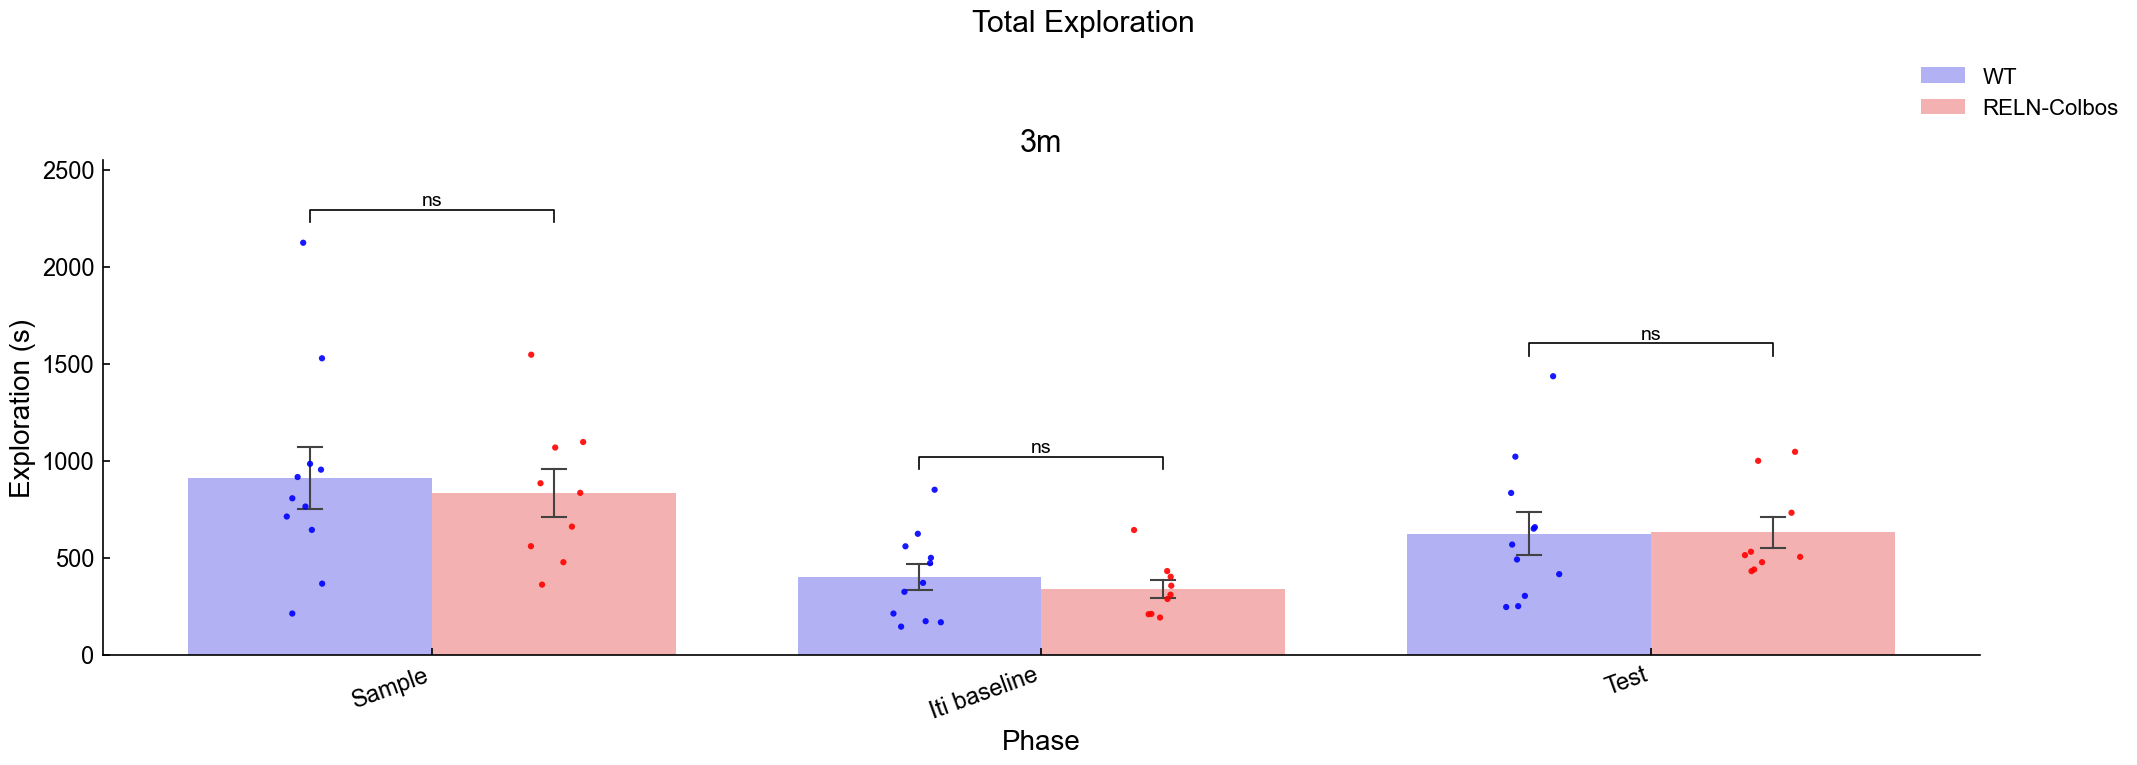

In [152]:
def plot_total_exploration_by_age(phase_total, stats_df=None):
    """stats_df: total_exploration_results; its stars are drawn above each phase (genotype_1 vs genotype_2)."""
    fig, axes = plt.subplots(1, len(AGE_ORDER), figsize=(22, 7.5), sharey=True)
    axes = np.atleast_1d(axes) 

    for ax, age in zip(axes, AGE_ORDER):
        sub = phase_total[phase_total["Age"] == age].copy()

        sns.barplot(
            data=sub,
            x="Phase",
            y="total_sec",
            hue="Genotype",
            order=PHASE_ORDER,
            hue_order=GENO_ORDER,
            palette=GENO_COLORS,
            errorbar="se",
            capsize=0.08,
            err_kws={"linewidth": 1.5},
            alpha=0.35,
            ax=ax
        )

        sns.stripplot(
            data=sub,
            x="Phase",
            y="total_sec",
            hue="Genotype",
            order=PHASE_ORDER,
            hue_order=GENO_ORDER,
            palette=GENO_COLORS,
            dodge=True,
            size=4.5,
            alpha=0.9,
            ax=ax
        )

        if stats_df is not None:
            # bars of the two genotypes sit at phase position -0.2 and +0.2
            y_top = sub["total_sec"].max()
            for i, phase in enumerate(PHASE_ORDER):
                match = stats_df[stats_df["Age"].eq(age) & stats_df["Phase"].eq(phase)]
                if match.empty or match["stars"].iloc[0] == "NA":
                    continue
                phase_max = sub.loc[sub["Phase"].eq(phase), "total_sec"].max()
                draw_star_bracket(ax, i - 0.2, i + 0.2, phase_max + 0.05 * y_top, match["stars"].iloc[0],
                                  height=0.03 * y_top)
            ax.set_ylim(top=y_top * 1.2)

        format_axes(ax)
        ax.set_title(age)
        ax.set_xlabel("Phase")
        ax.set_ylabel("Exploration (s)" if age == AGE_ORDER[0] else "")
        ax.set_xticks(range(len(PHASE_ORDER)))
        ax.set_xticklabels([clean_phase_label(p) for p in PHASE_ORDER], rotation=20, ha="right")


        if ax.get_legend() is not None:
            ax.get_legend().remove()

    handles, labels = axes[-1].get_legend_handles_labels()
    fig.legend(
        handles[:len(GENO_ORDER)],
        labels[:len(GENO_ORDER)],
        frameon=False,
        loc="upper right",
        bbox_to_anchor=(0.98, 0.98)
    )

    fig.suptitle("Total Exploration", y=1.03)
    plt.tight_layout(rect=[0, 0, 0.92, 0.98])
    save_figure_pdf()
    plt.show()

plot_total_exploration_by_age(phase_total, stats_df=total_exploration_results)


## 3.3 Average exploration over time

These are exploration-rate plots.

Exploration over time is plotted at the following timepoint:
- 4-hour: `0-240 min`
- 8-hour: `0-480 min`
- 24-hour: `0-1440 min`

The average is calculated separately within each age, genotype, phase and time bin.

In [153]:
def plot_phase_rows_for_one_age(
    summary_df,
    age,
    y_label,
    title,
    cutoff_min,
    sigma=0.5,
    xmin=0,
    figsize=(WIDE_W, WIDE_H)
):
    fig, axes = plt.subplots(
        len(PHASE_ORDER),
        1,
        figsize=figsize,
        sharex=True,
        sharey=True
    )


    age_df = summary_df[
        summary_df["Age"] == age
    ].copy()

    for ax, phase in zip(axes, PHASE_ORDER):

        phase_df = age_df[
            age_df["Phase"] == phase
        ].copy()

        for genotype in GENO_ORDER:

            temp = phase_df[
                phase_df["Genotype"] == genotype
            ].sort_values("time_min")

            if temp.empty:
                continue

            y = gaussian_filter1d(
                temp["mean_value"].values,
                sigma=sigma
            )

            sem = gaussian_filter1d(
                temp["sem_value"].fillna(0).values,
                sigma=sigma
            )

            ax.plot(
                temp["time_min"],
                y,
                color=GENO_COLORS[genotype],
                label=genotype,
                linewidth=2
            )

            ax.fill_between(
                temp["time_min"],
                y - sem,
                y + sem,
                color=GENO_COLORS[genotype],
                alpha=0.2
            )

        format_axes(ax)
        if xmin < 0:
            ax.axvline(0, color="black", linestyle="--", linewidth=1)

        ax.set_title(phase.replace("_", " ").capitalize())
        ax.set_ylabel(y_label)

    axes[-1].set_xlabel("Time from wheel change (min)")
    axes[-1].set_xlim(xmin, cutoff_min)

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        frameon=False,
        loc="upper right",
        bbox_to_anchor=(0.98, 0.98)
    )

    fig.suptitle(f"{title} ({age})", y=1.02)

    plt.tight_layout()
    save_figure_pdf()
    plt.show()

In [154]:
avg_4h_binned = rebin_timeseries(
    main_binned,
    value_cols=["total_sec"],
    bin_factor=1,
    cutoff_min=240
)

avg_4h_summary = summarise_timeseries(
    avg_4h_binned,
    "total_sec"
)

Saved PDF: Average_exploration_stacked.pdf (page 1: Average_exploration_4-hour_stacked_3m)


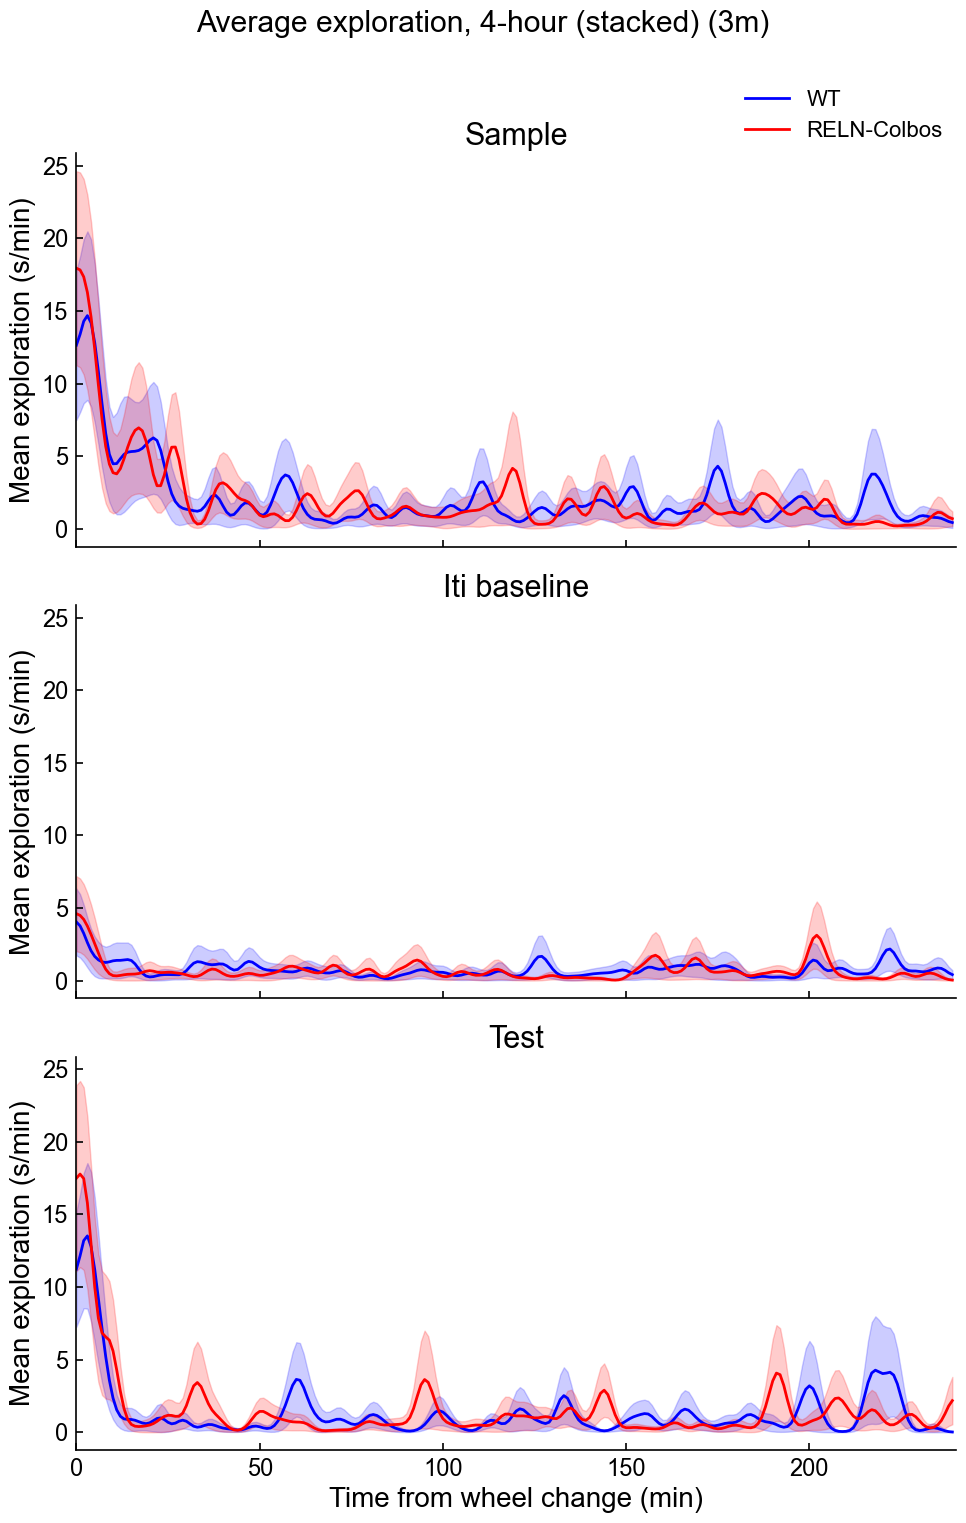

In [155]:
for age in AGE_ORDER:
    plot_phase_rows_for_one_age(
        avg_4h_summary,
        age=age,
        y_label="Mean exploration (s/min)",
        title="Average exploration, 4-hour (stacked)",
        cutoff_min=240,
        sigma=SMOOTH_SIGMA,
        figsize = (10, 15)
    )

In [156]:
avg_8h_binned = rebin_timeseries(
    main_binned,
    value_cols=["total_sec"],
    bin_factor=1,
    cutoff_min=480
)

avg_8h_summary = summarise_timeseries(
    avg_8h_binned,
    "total_sec"
)

Saved PDF: Average_exploration_stacked.pdf (page 2: Average_exploration_8-hour_stacked_3m)


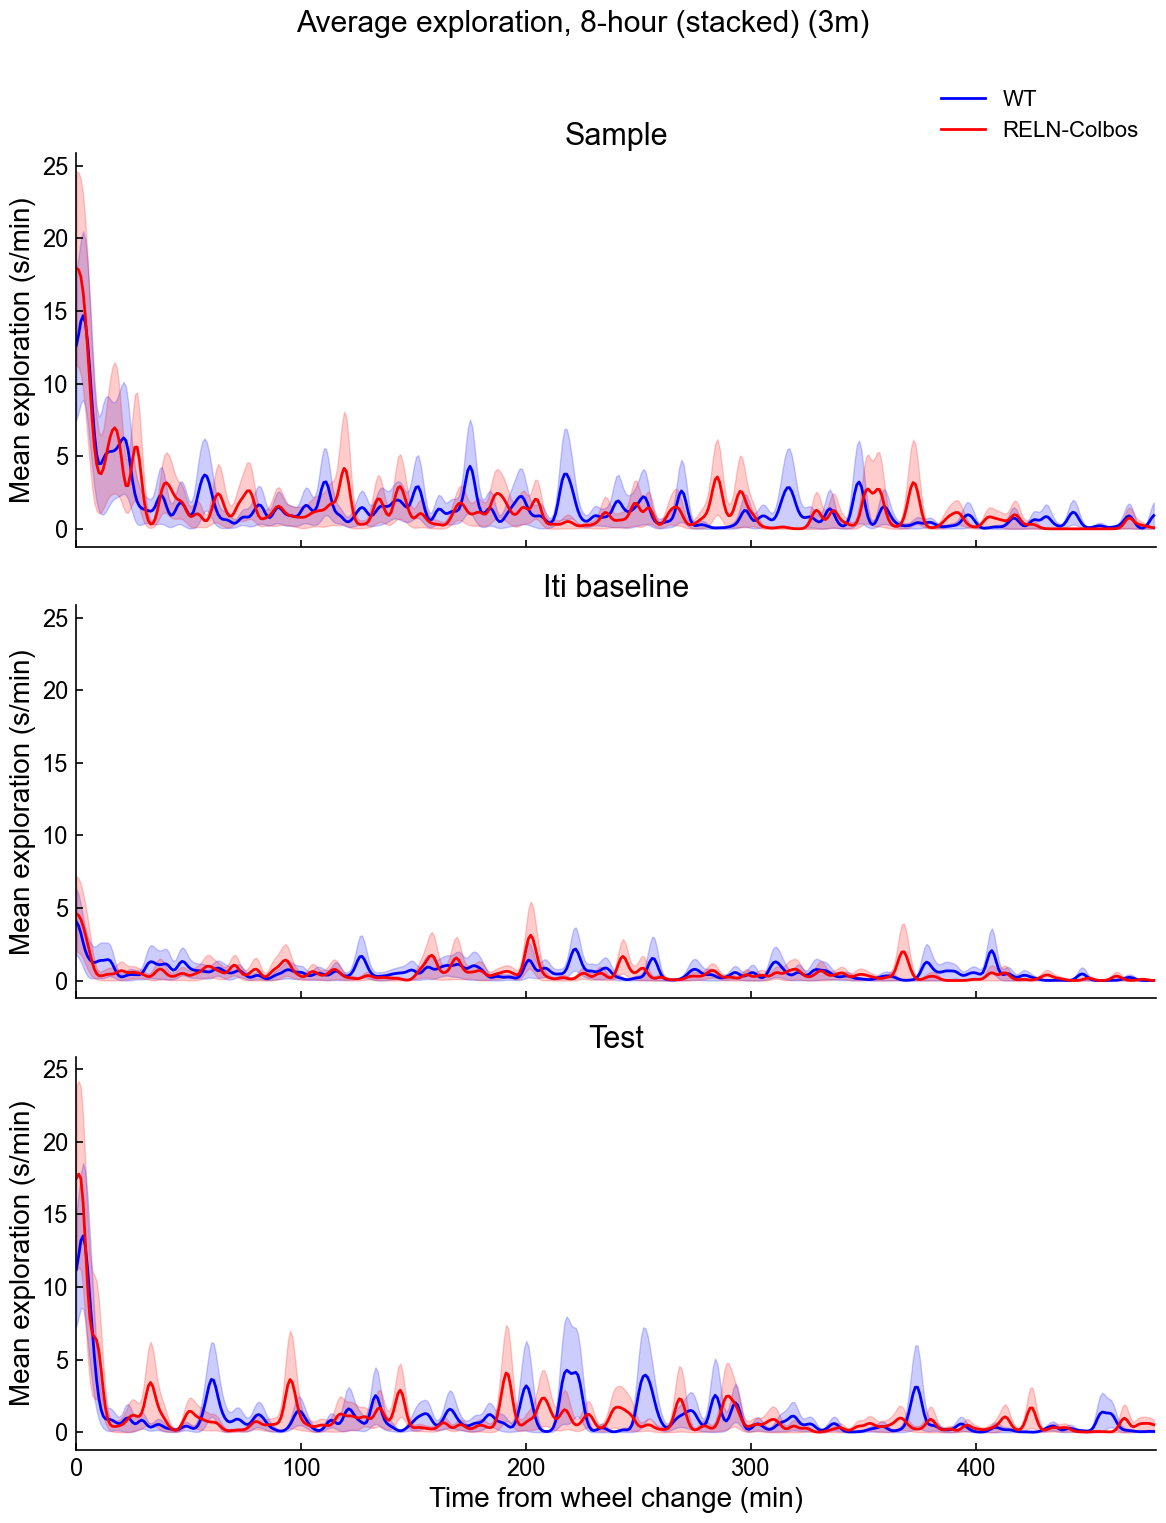

In [157]:
for age in AGE_ORDER:
    plot_phase_rows_for_one_age(
        avg_8h_summary,
        age=age,
        y_label="Mean exploration (s/min)",
        title="Average exploration, 8-hour (stacked)",
        cutoff_min=480,
        sigma=SMOOTH_SIGMA,
        figsize = (12, 15)
    )

In [158]:
avg_24h_binned = rebin_timeseries(
    main_binned,
    value_cols=["total_sec"],
    bin_factor=1,
    cutoff_min=1440
)

avg_24h_summary = summarise_timeseries(
    avg_24h_binned,
    "total_sec"
)

Saved PDF: Average_exploration_stacked.pdf (page 3: Average_exploration_24-hour_stacked_3m)


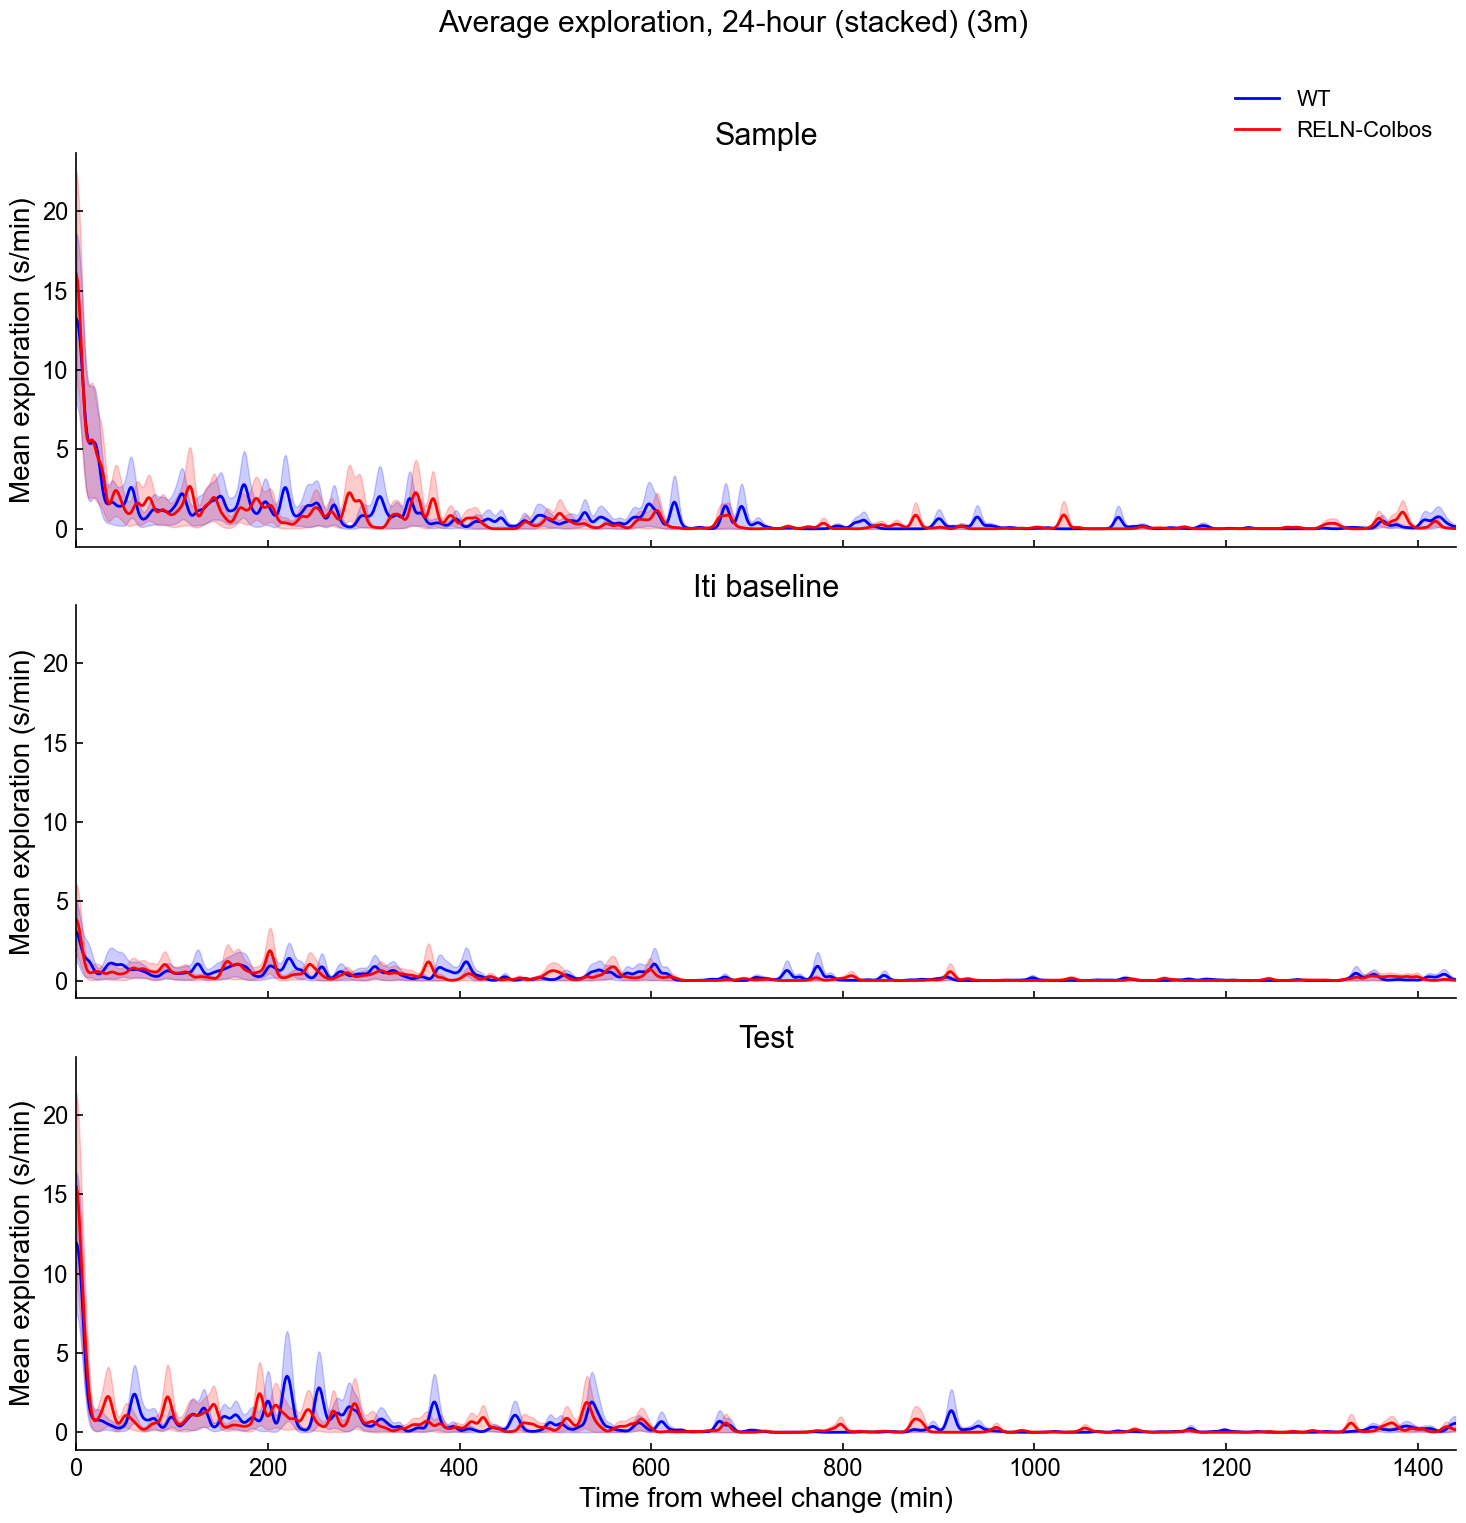

In [159]:
for age in AGE_ORDER:
    plot_phase_rows_for_one_age(
        avg_24h_summary,
        age=age,
        y_label="Mean exploration (s/min)",
        title="Average exploration, 24-hour (stacked)",
        cutoff_min=1440,
        sigma= 4,
        figsize = (15, 15)
    )

Saved PDF: Average_exploration_grid.pdf (page 1: Average_exploration_4-hour_grid_3m)


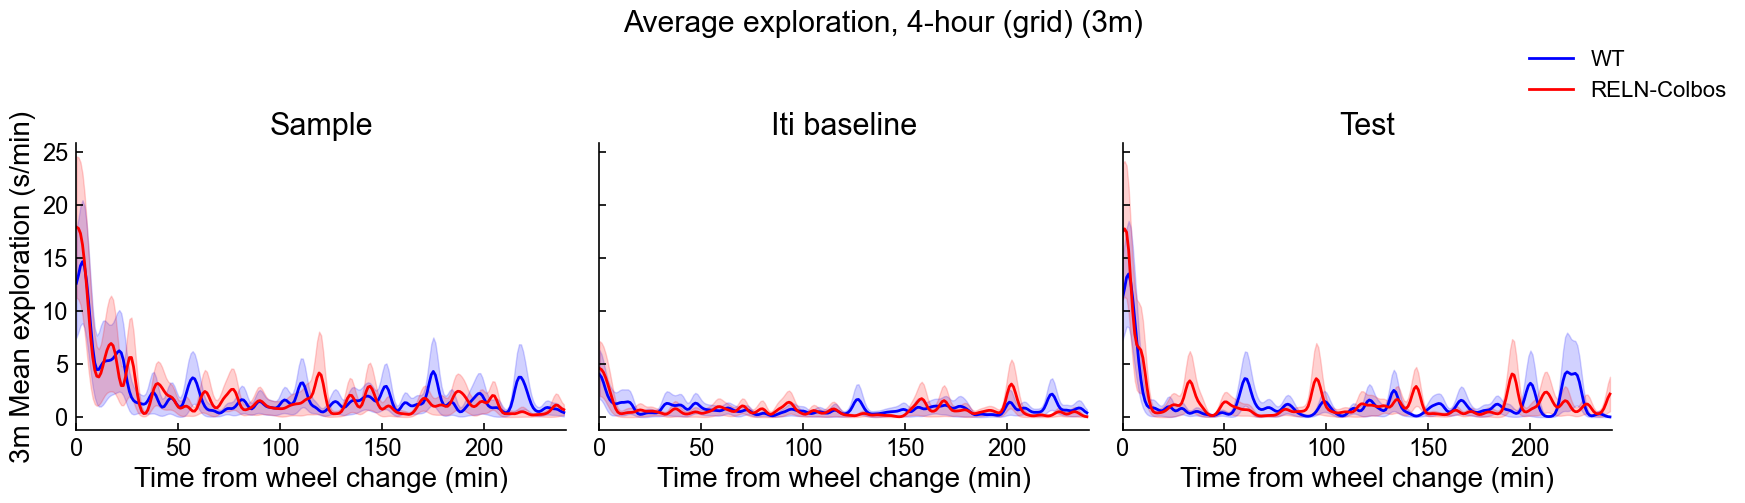

In [160]:
# Average exploration: 4 h (grid); avg_4h_summary is made above
plot_age_phase_grid(
    avg_4h_summary,
    y_label="Mean exploration (s/min)",
    title="Average exploration, 4-hour (grid)",
    cutoff_min=240,
    sigma=SMOOTH_SIGMA
)

Saved PDF: Average_exploration_grid.pdf (page 2: Average_exploration_8-hour_grid_3m)


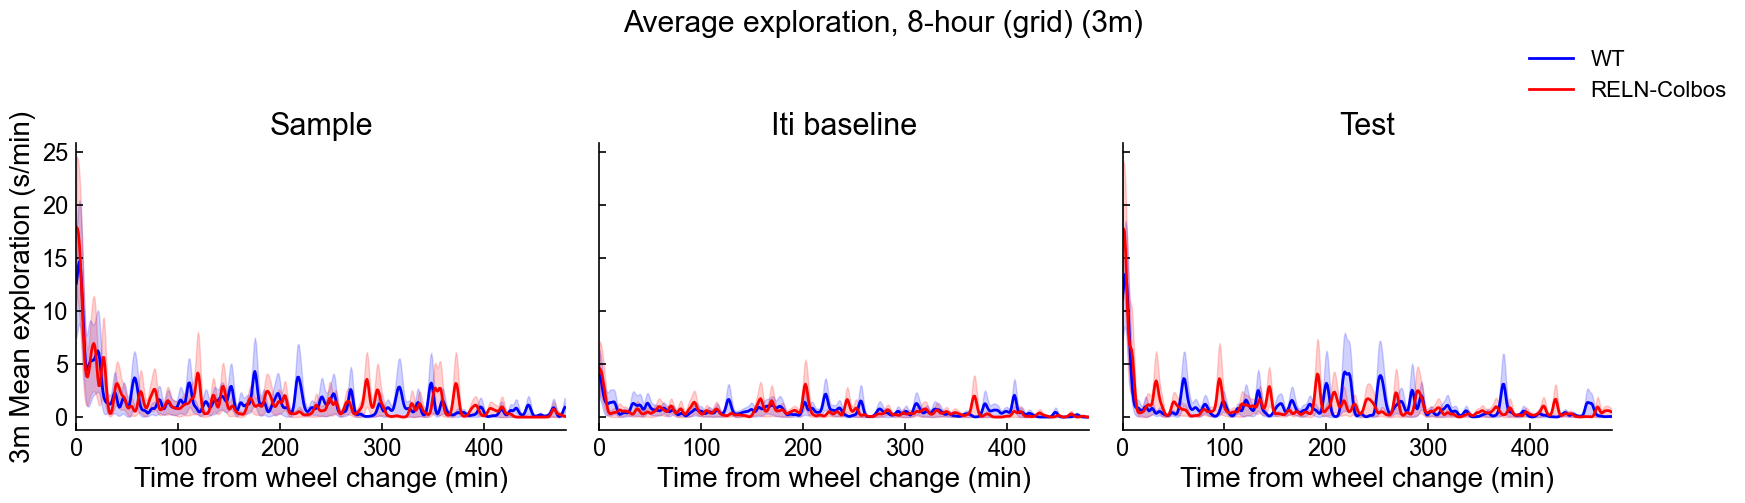

In [161]:
# Average exploration: 8 h (grid); avg_8h_summary is made above
plot_age_phase_grid(
    avg_8h_summary,
    y_label="Mean exploration (s/min)",
    title="Average exploration, 8-hour (grid)",
    cutoff_min=480,
    sigma=SMOOTH_SIGMA
)

Saved PDF: Average_exploration_grid.pdf (page 3: Average_exploration_24-hour_grid_3m)


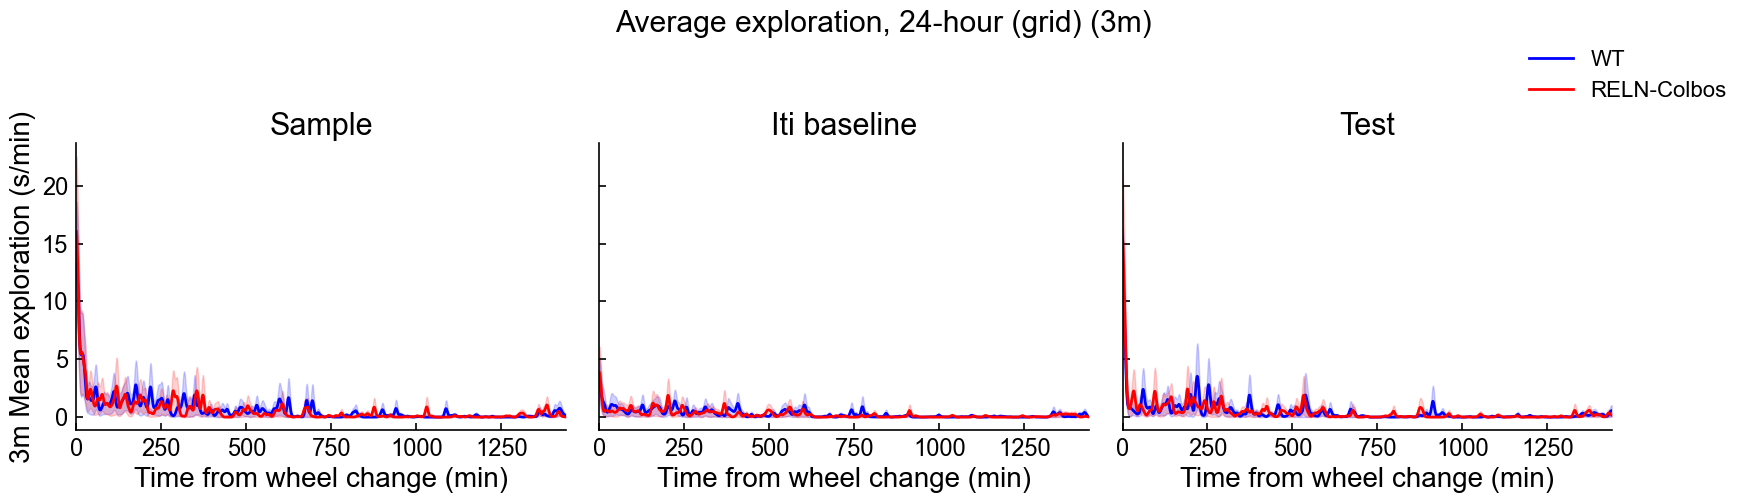

In [162]:
# Average exploration: 24 h (grid); avg_24h_summary is made above
plot_age_phase_grid(
    avg_24h_summary,
    y_label="Mean exploration (s/min)",
    title="Average exploration, 24-hour (grid)",
    cutoff_min=1440,
    sigma=4   # same smoothing as the 24 h stacked plot
)

## 3.3.1 Exploration around the wheel change

Exploration per minute from 2 h before to 2 h or 24 h after each wheel change.
Minute −1 is the last minute of the previous phase; minute 0 is the first minute after the wheel change.
"Before" comes from the previous phase in the binned file; for sample it comes from the `pre_sample`
window, the 2 h before the sample wheel change (added in the postprocessing notebook).

In [163]:
def make_around_wheel_change(data, pre_min=120, post_min=120):
    """Exploration per minute from -pre_min to +post_min around each wheel change, one row per mouse per minute.
    Before = last pre_min minutes of the previous phase (only if it ends at this wheel change).
    After = this phase's own minutes."""
    df = data.copy()
    df["rotation"] = pd.to_datetime(df["rotation"])
    df["window_end"] = pd.to_datetime(df["window_end"])

    keys = ["MouseSessionID", "KageID", "Cohort", "Age", "Genotype"]
    cols = keys + ["Phase", "rotation", "time_min", "total_sec"]

    # one row per mouse per phase, with the previous phase's start and end
    phases = (
        df[["MouseSessionID", "Phase", "rotation", "window_end"]]
        .drop_duplicates()
        .sort_values(["MouseSessionID", "rotation"])
    )
    phases["prev_rotation"] = phases.groupby("MouseSessionID")["rotation"].shift()
    phases["prev_window_end"] = phases.groupby("MouseSessionID")["window_end"].shift()
    phases = phases[phases["prev_window_end"].eq(phases["rotation"])]

    # after: minutes 0 to post_min of this phase
    after = df[df["time_min"] < post_min]

    # before: previous phase's minutes, re-timed so its last minute is -1
    df["n_bins"] = df.groupby(["MouseSessionID", "rotation"])["time_min"].transform("max") + 1
    before = df.drop(columns="Phase").merge(
        phases[["MouseSessionID", "prev_rotation", "Phase", "rotation"]]
        .rename(columns={"rotation": "next_rotation", "prev_rotation": "rotation"}),
        on=["MouseSessionID", "rotation"],
    )
    before["time_min"] = before["time_min"] - before["n_bins"]
    before = before[before["time_min"] >= -pre_min]
    before["rotation"] = before["next_rotation"]

    return pd.concat([before[cols], after[cols]], ignore_index=True)

Saved PDF: Exploration_around_wheel_change_stacked.pdf (page 1: Exploration_around_wheel_change_2_h_before__2_h_after_stacked_3m)


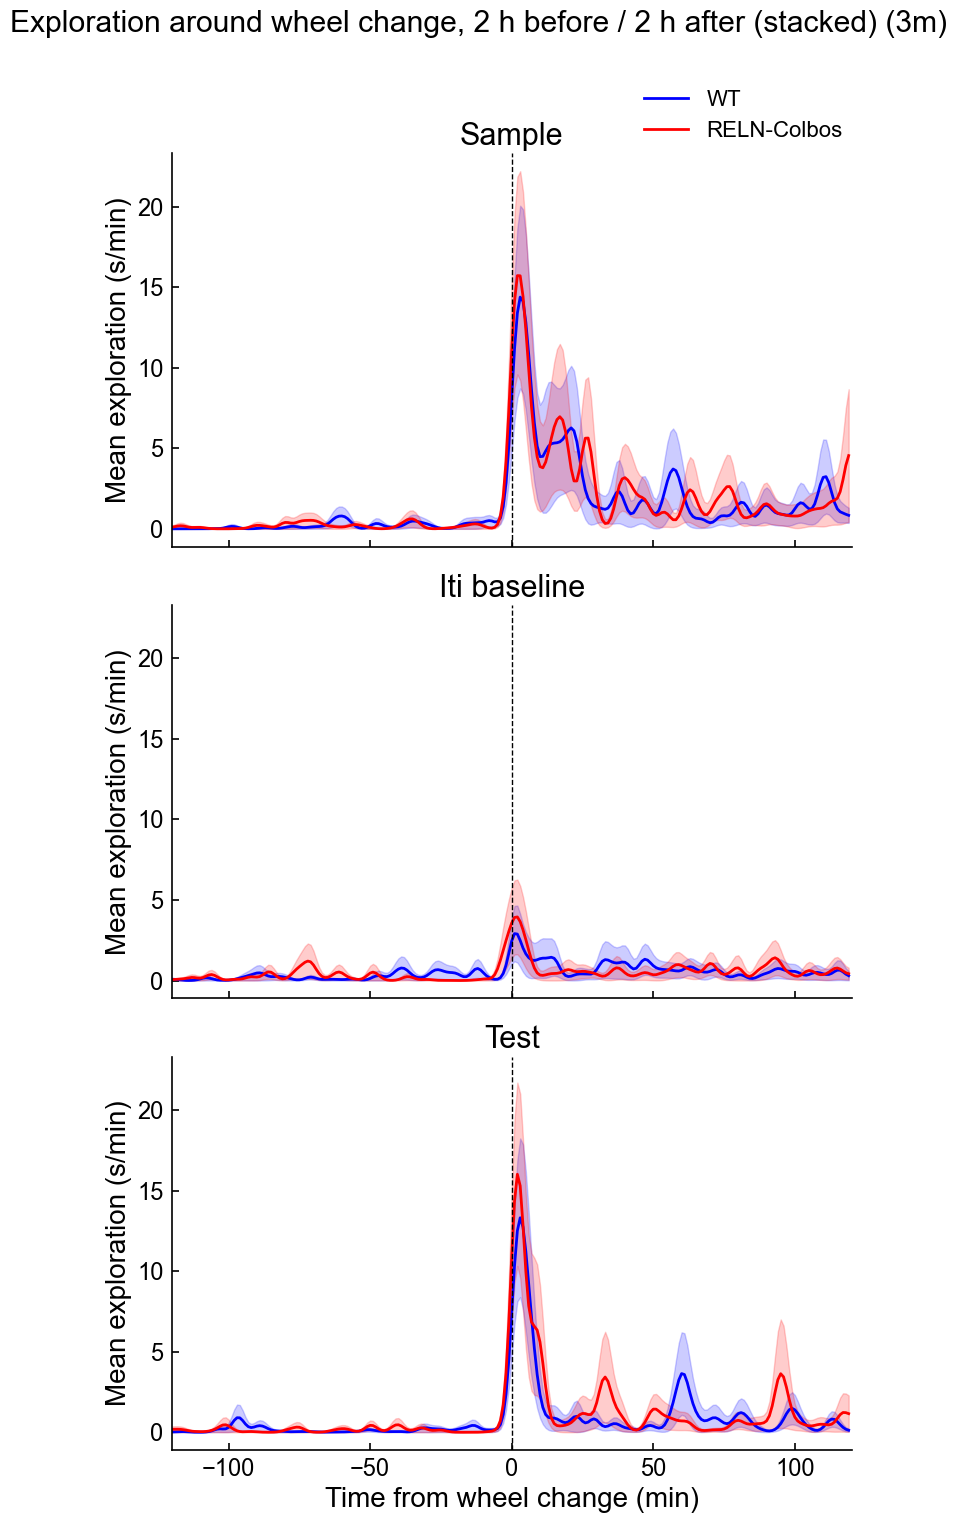

Saved PDF: Exploration_around_wheel_change_grid.pdf (page 1: Exploration_around_wheel_change_2_h_before__2_h_after_grid_3m)


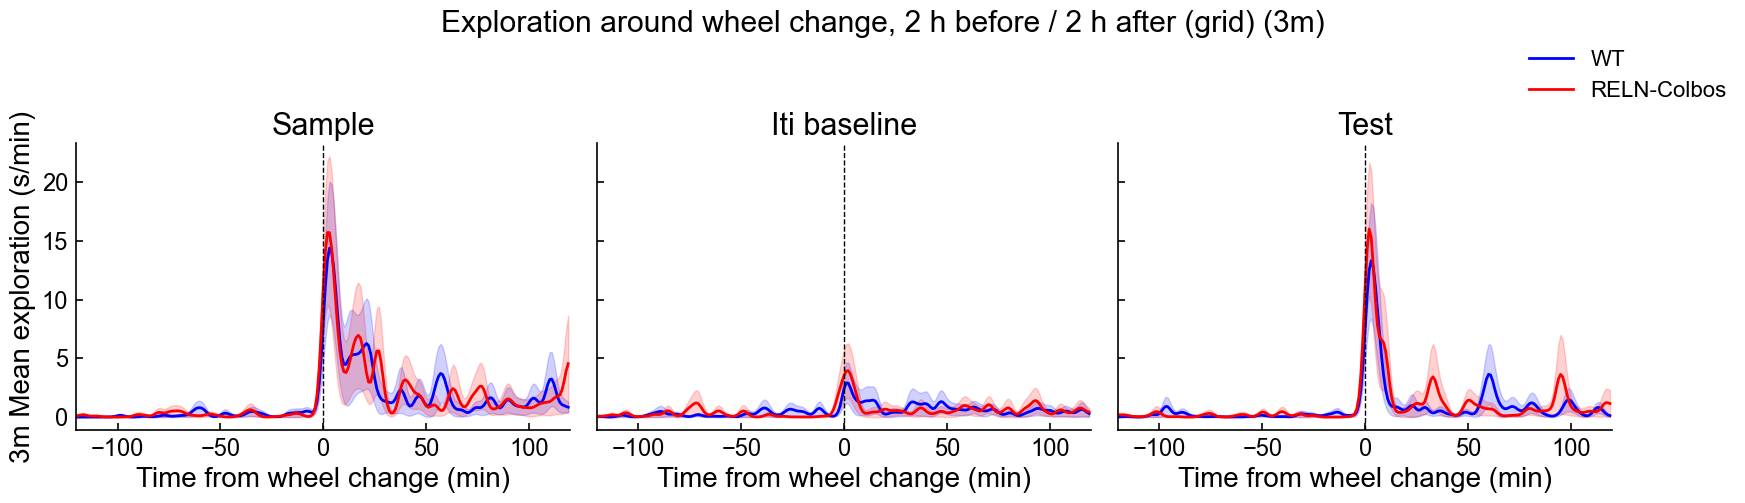

In [164]:
# Exploration around the wheel change: 2 h before / 2 h after
# pre_sample is kept so the sample phase has its 2 h before
around_input = binned_df[binned_df["Phase"].isin(["pre_sample"] + PHASE_ORDER)]
around_2h_2h = make_around_wheel_change(around_input, pre_min=120, post_min=120)
around_2h_2h_summary = summarise_timeseries(around_2h_2h, "total_sec")

for age in AGE_ORDER:
    plot_phase_rows_for_one_age(
        around_2h_2h_summary,
        age=age,
        y_label="Mean exploration (s/min)",
        title="Exploration around wheel change, 2 h before / 2 h after (stacked)",
        cutoff_min=120,
        sigma=SMOOTH_SIGMA,
        xmin=-120, 
        figsize = (8, 15)
    )

plot_age_phase_grid(
    around_2h_2h_summary,
    y_label=" Mean exploration (s/min)",
    title="Exploration around wheel change, 2 h before / 2 h after (grid)",
    cutoff_min=120,
    sigma=SMOOTH_SIGMA,
    xmin=-120
)

Saved PDF: Exploration_around_wheel_change_stacked.pdf (page 2: Exploration_around_wheel_change_2_h_before__24_h_after_stacked_3m)


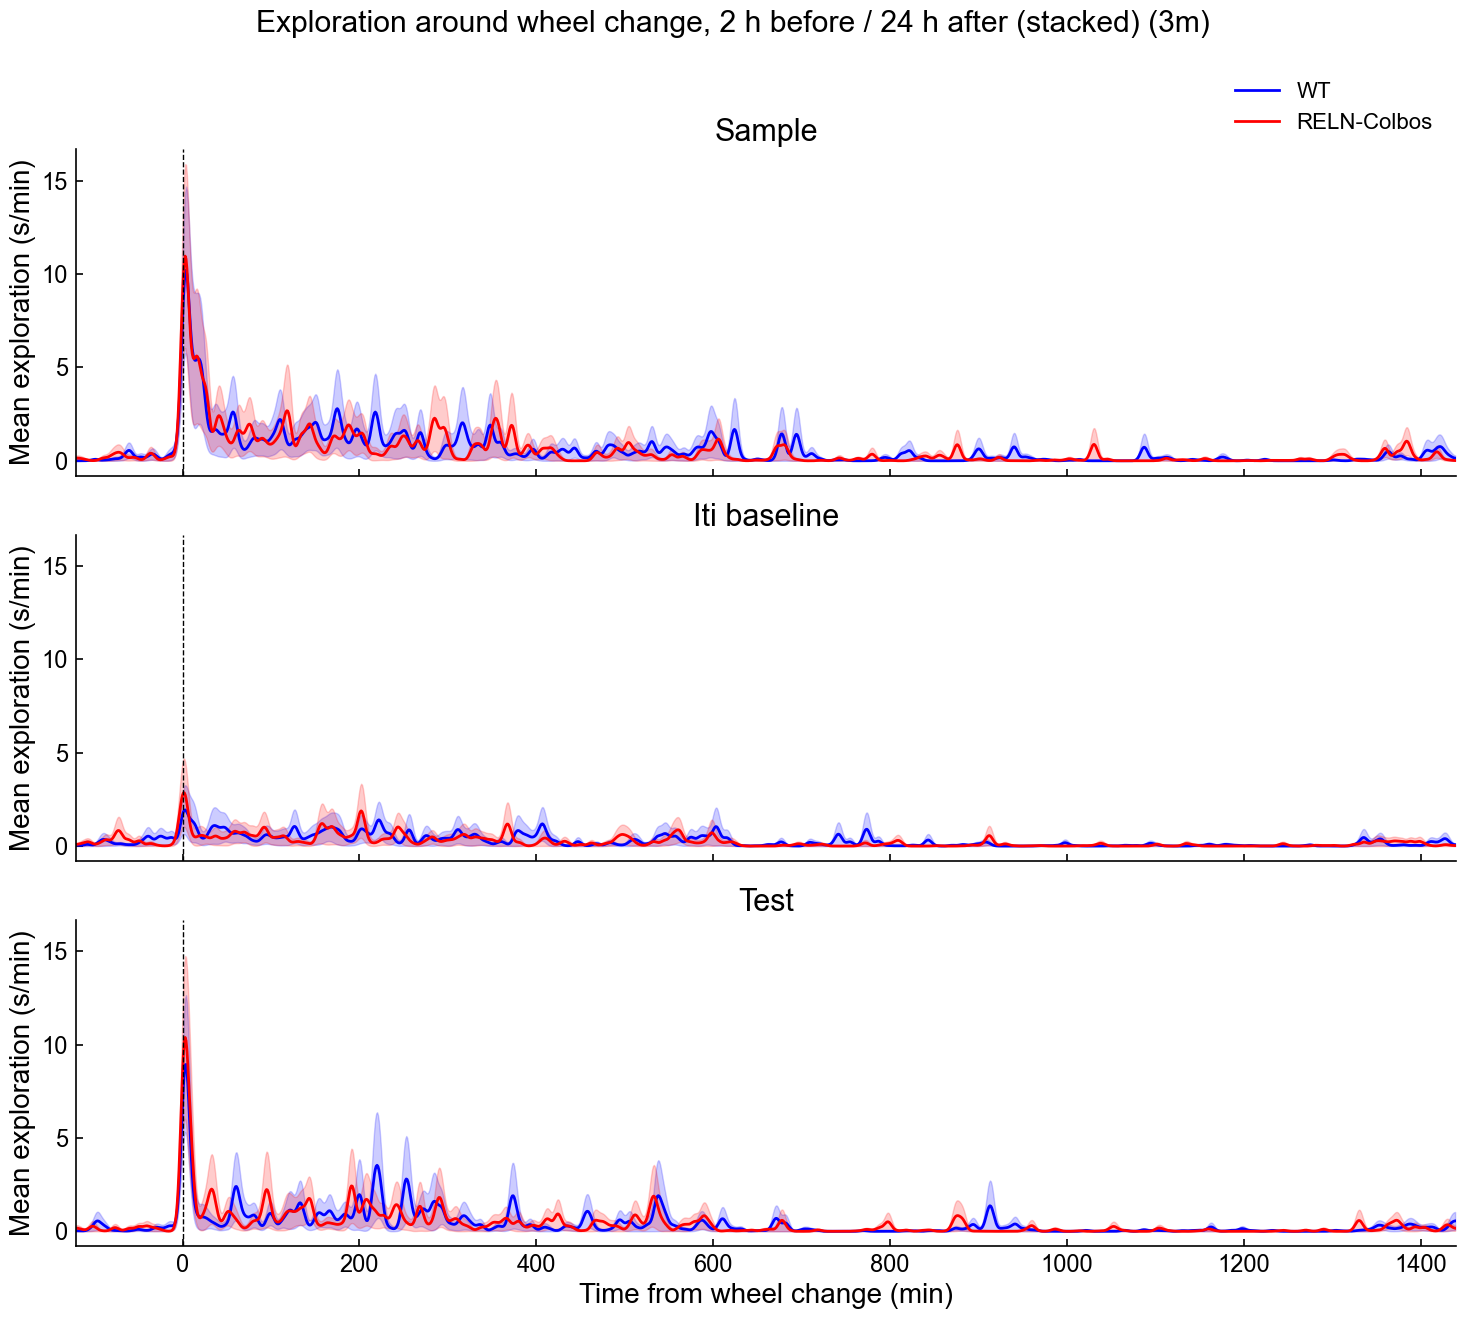

In [165]:
# Exploration around the wheel change: 2 h before / 24 h after
around_2h_24h = make_around_wheel_change(around_input, pre_min=120, post_min=1440)
around_2h_24h_summary = summarise_timeseries(around_2h_24h, "total_sec")

for age in AGE_ORDER:
    plot_phase_rows_for_one_age(
        around_2h_24h_summary,
        age=age,
        y_label="Mean exploration (s/min)",
        title="Exploration around wheel change, 2 h before / 24 h after (stacked)",
        cutoff_min=1440,
        sigma=4,
        xmin=-120,
        figsize = (15, 13)
    )


## 3.4 Cumulative exploration

Cumulative exploration is recomputed from `total_sec`. This avoids drops in the curve when different mice have different phase lengths.

- 2 h cumulative exploration
- 10 h cumulative exploration
- 24 h cumulative exploration

The curves are smoothed (Gaussian); the amount is set in `CUM_SMOOTH_SIGMA`.


In [166]:
def make_cumulative_filled_master(data, cutoff_min=1440):
    full_bins = range(0, cutoff_min)

    filled = []

    for (mouse, phase), df in data.groupby(["MouseSessionID", "Phase"]):

        df = df[df["time_min"] < cutoff_min].copy()

        df["time_min"] = pd.to_numeric(df["time_min"], errors="coerce")
        df["cumulative_total_sec"] = pd.to_numeric(
            df["cumulative_total_sec"],
            errors="coerce"
        )

        df = df.dropna(subset=["time_min", "cumulative_total_sec"])

        meta = df.iloc[0][
            ["MouseSessionID", "KageID", "Cohort", "Age", "Genotype", "Phase"]
        ]

        df = (
            df
            .groupby("time_min", as_index=False)
            .agg(
                cumulative_total_sec=("cumulative_total_sec", "max")
            )
        )

        df = df.set_index("time_min").reindex(full_bins)

        for col in meta.index:
            df[col] = meta[col]

        df["cumulative_total_sec"] = (
            df["cumulative_total_sec"]
            .ffill()
            .fillna(0)
        )

        filled.append(df.reset_index())

    return pd.concat(filled, ignore_index=True)

In [167]:
# Smoothing of the cumulative curves (Gaussian, sigma in minutes): about 1 min per hour shown,
# so every window looks equally smooth. Increase for smoother curves, 0.5 = almost none.
CUM_SMOOTH_SIGMA = {120: 2, 600: 10, 1440: 24}

# Make the full 24 h filled cumulative table once
binned_filled_24h = make_cumulative_filled_master(
    main_binned,
    cutoff_min=1440
)

binned_filled_2h = binned_filled_24h[
    binned_filled_24h["time_min"] < 120
].copy()

cum_2h_summary = (
    binned_filled_2h
    .groupby(["Age", "Genotype", "Phase", "time_min"], as_index=False)
    .agg(
        mean_value=("cumulative_total_sec", "mean"),
        sem_value=("cumulative_total_sec", lambda x: x.sem())
    )
)

Saved PDF: Cumulative_exploration.pdf (page 1: Cumulative_exploration_over_2-hour_3m)


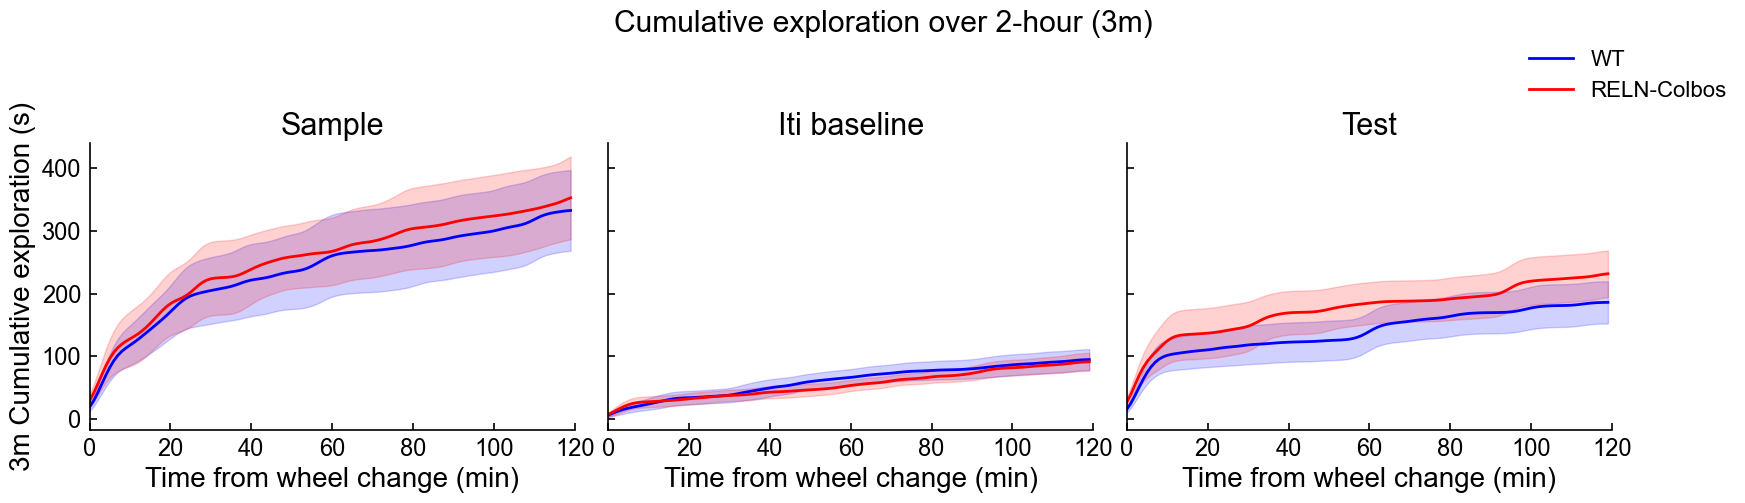

In [168]:
plot_age_phase_grid(
    cum_2h_summary,
    y_label="Cumulative exploration (s)",
    title="Cumulative exploration over 2-hour",
    cutoff_min=120,
    sigma=CUM_SMOOTH_SIGMA[120],
    smooth_mode="nearest",
)

In [169]:
binned_filled_10h = binned_filled_24h[
    binned_filled_24h["time_min"] < 600
].copy()

cum_10h_summary = (
    binned_filled_10h
    .groupby(["Age", "Genotype", "Phase", "time_min"], as_index=False)
    .agg(
        mean_value=("cumulative_total_sec", "mean"),
        sem_value=("cumulative_total_sec", lambda x: x.sem())
    )
)

Saved PDF: Cumulative_exploration.pdf (page 2: Cumulative_exploration_over_10-hour_3m)


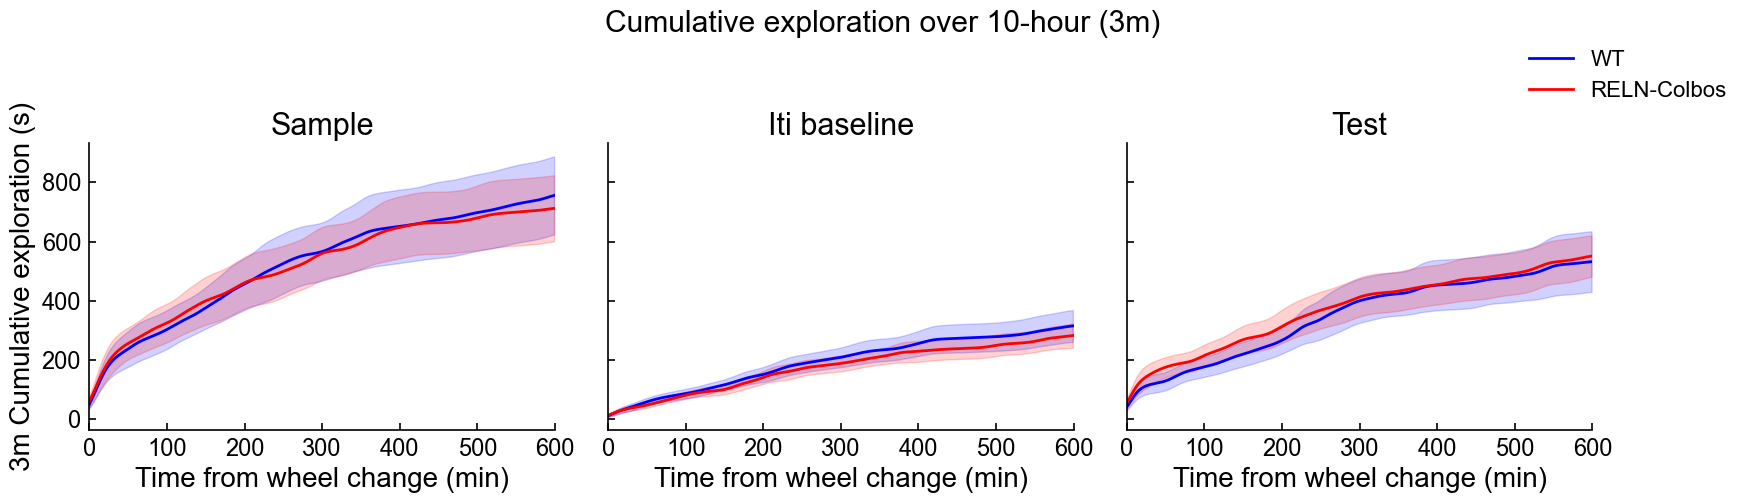

In [170]:
plot_age_phase_grid(
    cum_10h_summary,
    y_label="Cumulative exploration (s)",
    title="Cumulative exploration over 10-hour",
    cutoff_min=600,
    sigma=CUM_SMOOTH_SIGMA[600],
    smooth_mode="nearest",
)

Saved PDF: Cumulative_exploration.pdf (page 3: Cumulative_exploration_over_24-hour_3m)


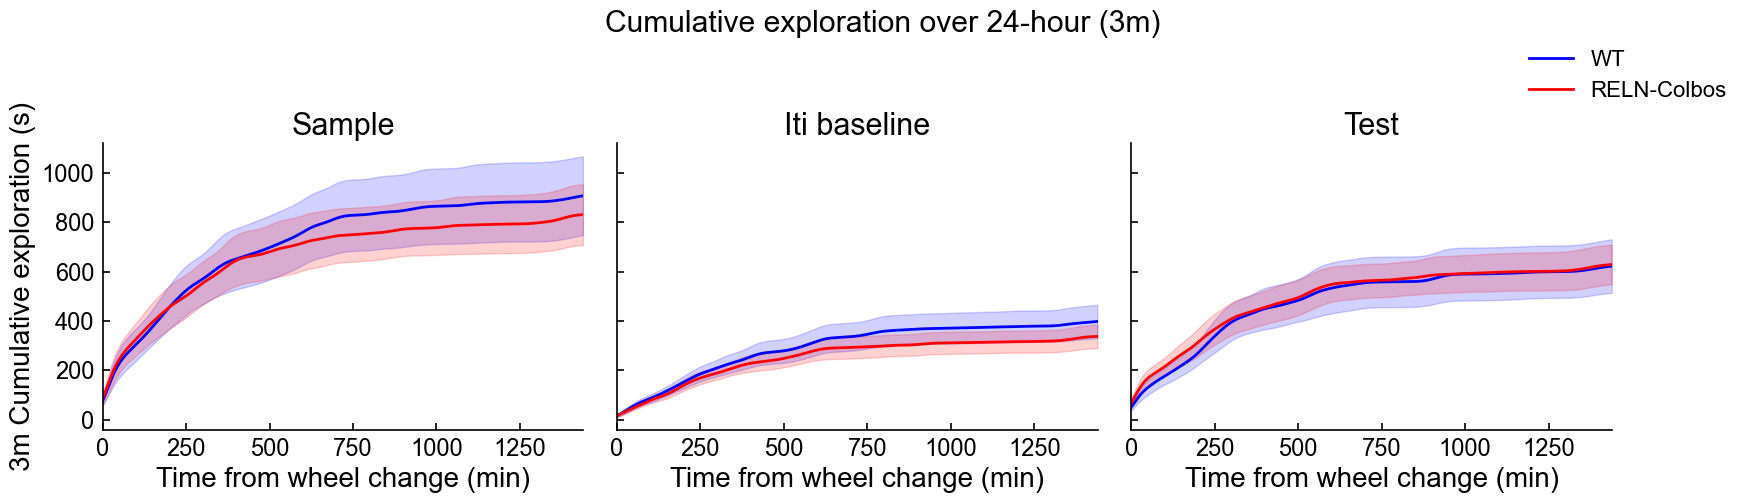

In [171]:
cum_24h_summary = (
    binned_filled_24h
    .groupby(["Age", "Genotype", "Phase", "time_min"], as_index=False)
    .agg(
        mean_value=("cumulative_total_sec", "mean"),
        sem_value=("cumulative_total_sec", lambda x: x.sem())
    )
)

plot_age_phase_grid(
    cum_24h_summary,
    y_label="Cumulative exploration (s)",
    title="Cumulative exploration over 24-hour",
    cutoff_min=1440,
    sigma=CUM_SMOOTH_SIGMA[1440],
    smooth_mode="nearest",
)

## 4. Novel/Familiar & Left/Right Discrimination Index

In the `kage_descriptions` file: 
- `NOR_side = L` means left side is novel.
- `NOR_side = R` means right side is novel.

DI is calculated at the mouse/session level first, then averaged by age and genotype.

Two DI measures are generated:

1. Novel/Familiar DI

`(Novel - Familiar) / (Novel + Familiar)`

2. Side-bias DI

`(Left - Right) / (Left + Right)`


## 4.1 Cumulative DI over time

In [172]:
def make_test_di_table(data, cutoff_min=120, bin_factor=1):
    test = data[data["Phase"] == "test"].copy()

    needed = ["left_sec", "right_sec", "NOR_side"]
    missing = [c for c in needed if c not in test.columns]
    if missing:
        raise ValueError(f"Missing required columns for DI: {missing}")

    test = rebin_timeseries(
        test,
        value_cols=["left_sec", "right_sec"],
        bin_factor=bin_factor,
        cutoff_min=cutoff_min
    )

    # rebin_timeseries drops NOR_side, so bring it back per MouseSessionID
    meta_cols = ["MouseSessionID", "NOR_side"]
    meta = data[data["Phase"] == "test"][meta_cols].drop_duplicates("MouseSessionID")
    test = test.merge(meta, on="MouseSessionID", how="left")

    side = test["NOR_side"].astype(str).str.upper().str[0]

    test["novel_sec"] = np.where(side == "L", test["left_sec"], test["right_sec"])
    test["familiar_sec"] = np.where(side == "L", test["right_sec"], test["left_sec"])

    test["novel_familiar_total"] = test["novel_sec"] + test["familiar_sec"]
    test["left_right_total"] = test["left_sec"] + test["right_sec"]

    test["DI"] = np.where(
        test["novel_familiar_total"] > 0,
        (test["novel_sec"] - test["familiar_sec"]) / test["novel_familiar_total"],
        np.nan
    )

    test["side_bias_DI"] = np.where(
        test["left_right_total"] > 0,
        (test["left_sec"] - test["right_sec"]) / test["left_right_total"],
        np.nan
    )

    # cumulative DI: novel/familiar (and left/right) summed from the wheel change up to each time bin
    test = test.sort_values(["MouseSessionID", "time_min"])
    g = test.groupby("MouseSessionID")
    for col in ["novel_sec", "familiar_sec", "left_sec", "right_sec"]:
        test[f"cumulative_{col}"] = g[col].cumsum()

    cum_nf = test["cumulative_novel_sec"] + test["cumulative_familiar_sec"]
    cum_lr = test["cumulative_left_sec"] + test["cumulative_right_sec"]
    test["cumulative_DI"] = (
        (test["cumulative_novel_sec"] - test["cumulative_familiar_sec"]) / cum_nf
    ).where(cum_nf > 0)
    test["cumulative_side_bias_DI"] = (
        (test["cumulative_left_sec"] - test["cumulative_right_sec"]) / cum_lr
    ).where(cum_lr > 0)


    return test


def summarise_di(di_table, value_col):
    return (
        di_table
        .groupby(["Age", "Genotype", "time_min"], as_index=False)
        .agg(
            mean_value=(value_col, "mean"),
            sem_value=(value_col, "sem"),
            n=(value_col, "count")
        )
    )


def plot_di_by_age(di_summary, title, cutoff_min, y_label="DI", sigma=2, smooth_mode="reflect"):
    """sigma: Gaussian smoothing width in minutes (0 = none); smooth_mode: how the curve ends are handled."""
    fig, axes = plt.subplots(
        len(AGE_ORDER), 1,
        figsize=(10, 4 * len(AGE_ORDER) + 1),
        sharex=True, sharey=True
    )
    axes = np.atleast_1d(axes)

    for ax, age in zip(axes, AGE_ORDER):
        sub = di_summary[di_summary["Age"] == age].copy()

        for genotype in GENO_ORDER:
            # drop minutes where no mouse has explored yet (DI undefined)
            temp = sub[sub["Genotype"] == genotype].sort_values("time_min").dropna(subset=["mean_value"])
            if temp.empty:
                continue

            y = temp["mean_value"].to_numpy()
            e = temp["sem_value"].fillna(0).to_numpy()
            if sigma:
                y = gaussian_filter1d(y, sigma=sigma, mode=smooth_mode)
                e = gaussian_filter1d(e, sigma=sigma, mode=smooth_mode)

            ax.plot(
                temp["time_min"],
                y,
                color=GENO_COLORS.get(genotype, "black"),
                label=genotype,
                linewidth=2
            )

            ax.fill_between(
                temp["time_min"],
                y - e,
                y + e,
                color=GENO_COLORS.get(genotype, "black"),
                alpha=0.18
            )

        ax.axhline(0, color="black", linestyle="--", linewidth=1)
        format_axes(ax)
        ax.set_xlim(0, cutoff_min)
        ax.set_ylim(-1, 1)
        ax.set_ylabel(f"{age} {y_label.strip()}")

    axes[-1].set_xlabel("Time from test wheel change (min)")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, loc="upper right", bbox_to_anchor=(0.98, 0.98))
    fig.suptitle(f"{title} ({', '.join(AGE_ORDER)})", y=1.02)
    plt.tight_layout(rect=[0, 0, 0.90, 0.98])
    save_figure_pdf()
    plt.show()



Saved PDF: Cumulative_novel_familiar_DI.pdf (page 1: Cumulative_novelfamiliar_DI_first_20_min_3m)


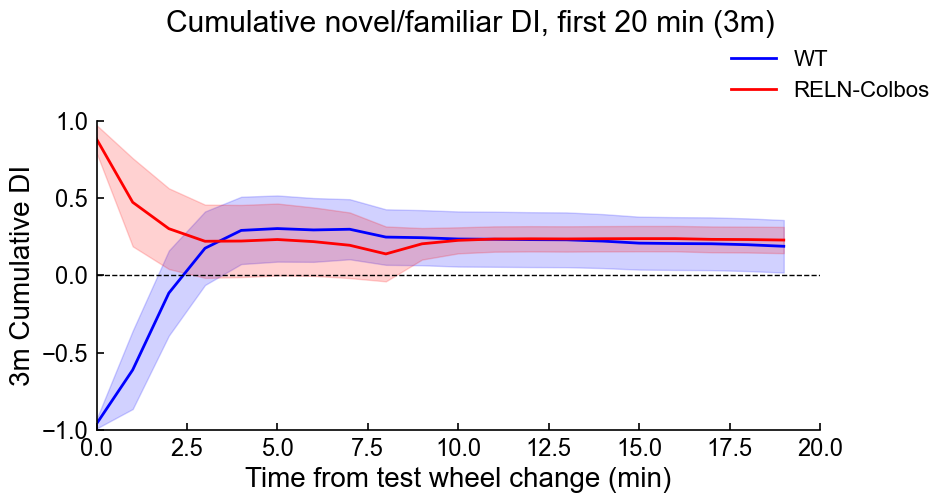

Saved PDF: Cumulative_novel_familiar_DI.pdf (page 2: Cumulative_novelfamiliar_DI_first_120_min_3m)


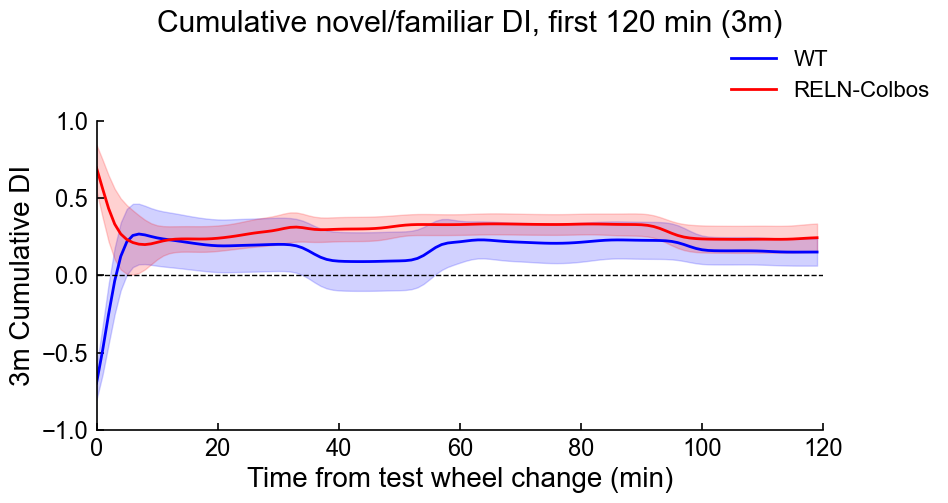

Saved PDF: Cumulative_novel_familiar_DI.pdf (page 3: Cumulative_novelfamiliar_DI_first_600_min_3m)


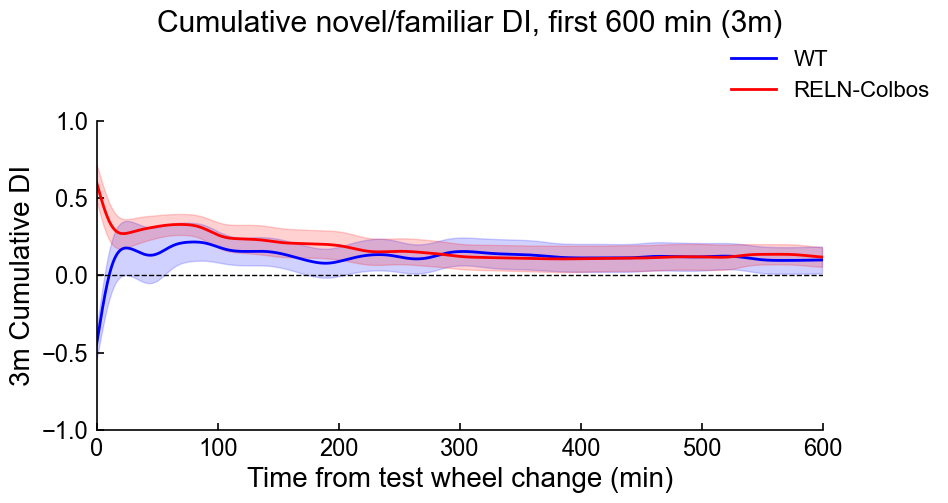

Saved PDF: Cumulative_novel_familiar_DI.pdf (page 4: Cumulative_novelfamiliar_DI_first_1440_min_3m)


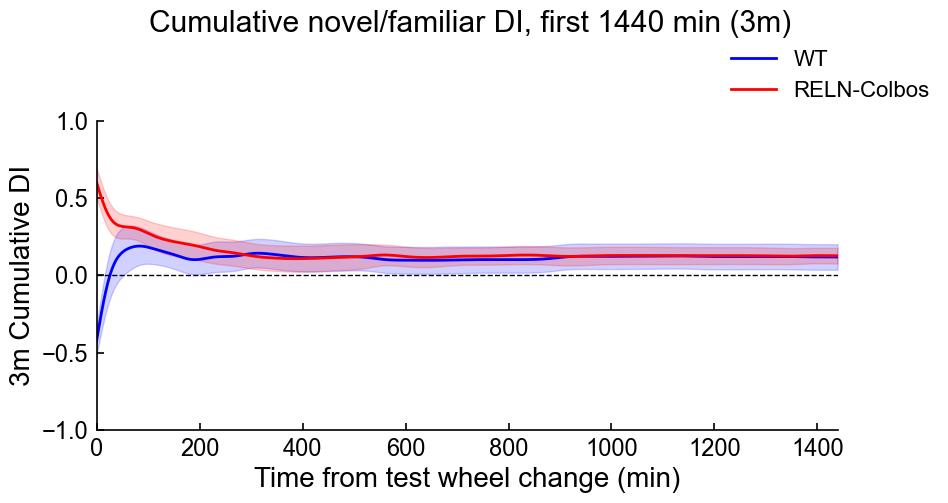

In [173]:
# Cumulative novel/familiar DI: 20 min, 2 h, 10 h, 24 h
di_table = make_test_di_table(main_binned, cutoff_min=1440, bin_factor=1)

# Smoothing of the plotted curves (Gaussian, sigma in minutes): about 1 min per hour shown, the same rule as
# the cumulative exploration plots (3.4). The 20 min plot is almost unsmoothed. 0 = no smoothing.
CUM_DI_SMOOTH_SIGMA = {20: 0.5, 120: 2, 600: 10, 1440: 24}

for cutoff in [20, 120, 600, 1440]:
    di_summary = summarise_di(di_table[di_table["time_min"] < cutoff], "cumulative_DI")
    plot_di_by_age(
        di_summary,
        title=f"Cumulative novel/familiar DI, first {cutoff} min",
        cutoff_min=cutoff,
        y_label=" Cumulative DI",
        sigma=CUM_DI_SMOOTH_SIGMA[cutoff],
        smooth_mode="nearest",
    )


Saved PDF: Cumulative_side_bias_DI.pdf (page 1: Cumulative_side-bias_DI_first_20_min_3m)


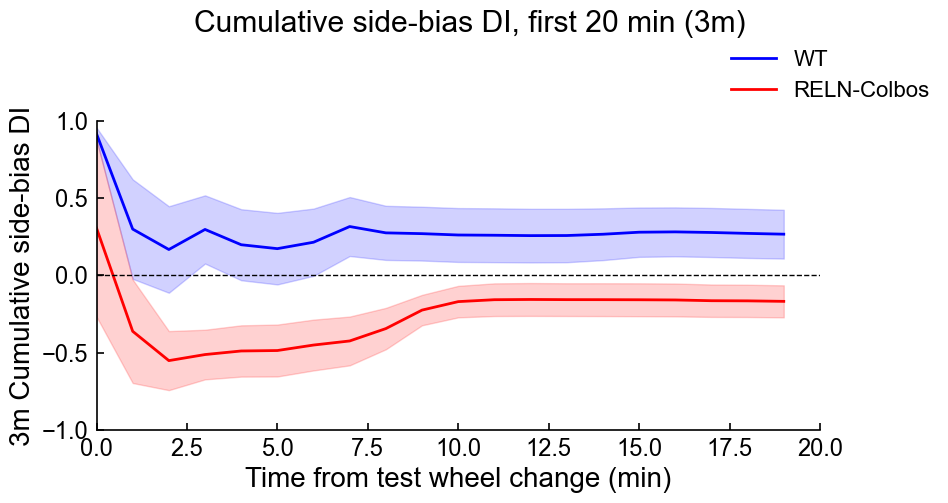

Saved PDF: Cumulative_side_bias_DI.pdf (page 2: Cumulative_side-bias_DI_first_120_min_3m)


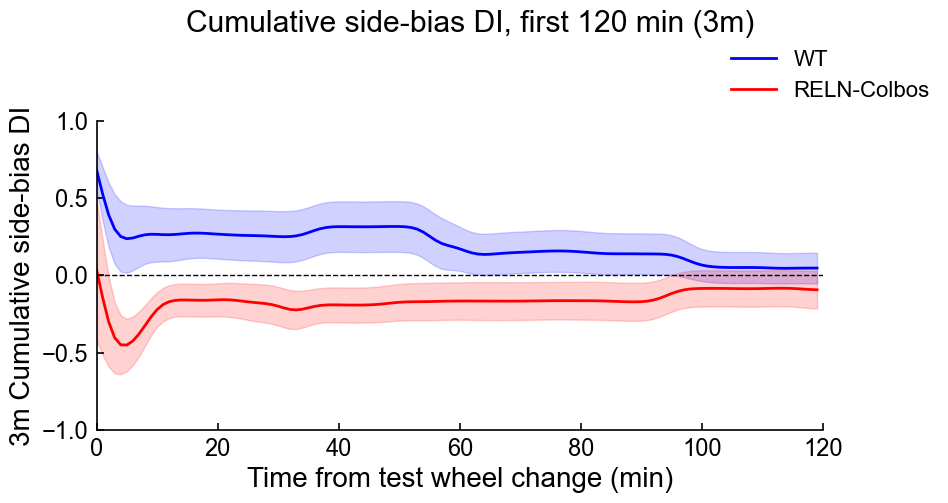

Saved PDF: Cumulative_side_bias_DI.pdf (page 3: Cumulative_side-bias_DI_first_600_min_3m)


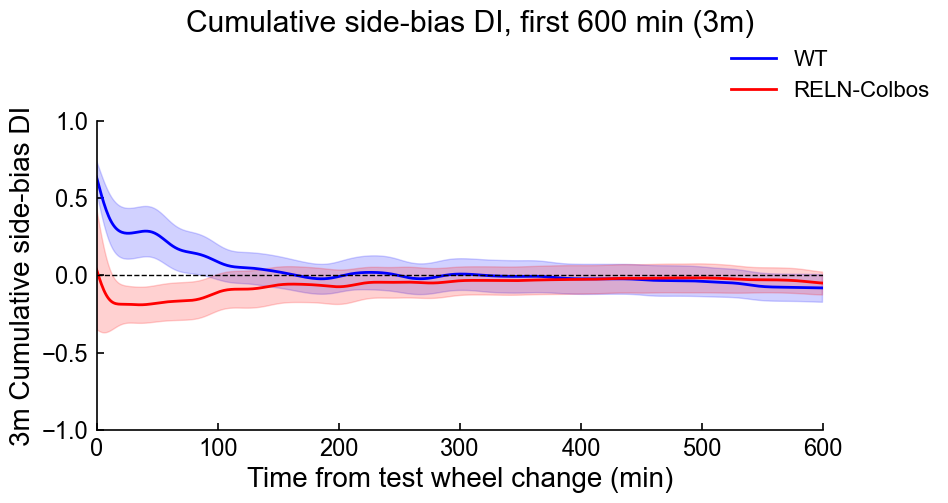

Saved PDF: Cumulative_side_bias_DI.pdf (page 4: Cumulative_side-bias_DI_first_1440_min_3m)


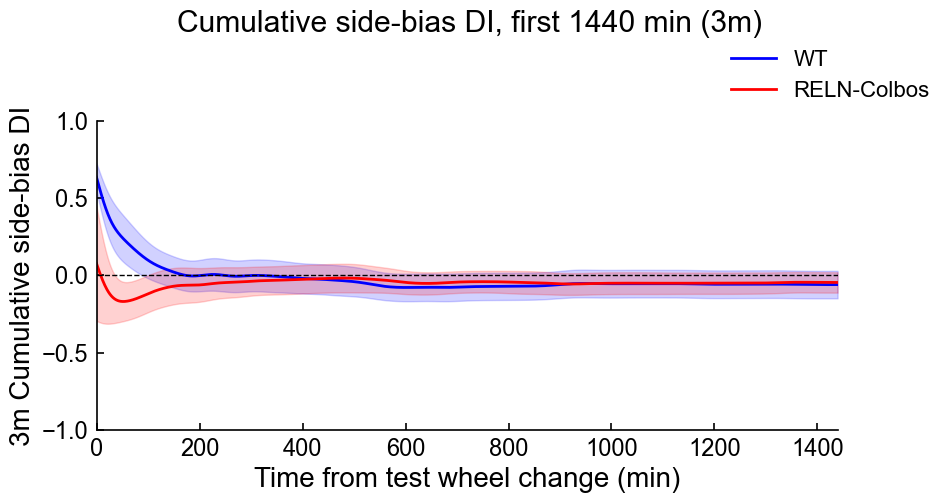

In [174]:
# Cumulative side-bias DI: 20 min, 2 h, 10 h, 24 h
for cutoff in [20, 120, 600, 1440]:
    side_summary = summarise_di(di_table[di_table["time_min"] < cutoff], "cumulative_side_bias_DI")
    plot_di_by_age(
        side_summary,
        title=f"Cumulative side-bias DI, first {cutoff} min",
        cutoff_min=cutoff,
        y_label=" Cumulative side-bias DI",
        sigma=CUM_DI_SMOOTH_SIGMA[cutoff],   # same smoothing as the novel/familiar DI plots
        smooth_mode="nearest",
    )

## 4.2 DI value at 20min, 2h, 4h, 6h, 8h

In [175]:
DI_TIMEPOINTS = [20, 120, 240, 360, 480]  # 20 min, 2, 4, 6, 8 h

# cumulative DI at the last minute of each window (minute 119 = first 2 h)
di_timepoint_df = (
    di_table[di_table["time_min"].isin([t - 1 for t in DI_TIMEPOINTS])]
    .assign(
        timepoint_min=lambda d: d["time_min"] + 1,
        timepoint_h=lambda d: (d["time_min"] + 1) / 60,
    )
    .drop(columns=["DI"])                      # per-minute DI, not needed here
    .rename(columns={"cumulative_DI": "DI"})
    [["Age", "Genotype", "MouseSessionID", "timepoint_min", "timepoint_h", "DI"]]
)

# readable labels for plots: "20 min", "2 h", ...
def timepoint_label(minutes):
    return f"{minutes} min" if minutes < 60 else f"{minutes // 60} h"

TIMEPOINT_LABELS = [timepoint_label(t) for t in DI_TIMEPOINTS]
di_timepoint_df["timepoint_label"] = pd.Categorical(
    di_timepoint_df["timepoint_min"].map(timepoint_label),
    categories=TIMEPOINT_LABELS,
    ordered=True,
)

di_timepoint_df.head()


,Age,Genotype,MouseSessionID,timepoint_min,timepoint_h,DI,timepoint_label
19,3m,WT,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,20,0.333333,0.175676,20 min
119,3m,WT,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,120,2.000000,0.147368,2 h
239,3m,WT,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,240,4.000000,0.093596,4 h
359,3m,WT,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,360,6.000000,0.127660,6 h
479,3m,WT,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,480,8.000000,0.090909,8 h


In [176]:
def plot_di_timepoints_by_age(di_df, age):

    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

    plot_df = di_df[
        di_df["Age"] == age
    ].copy()

    sns.barplot(
        data=plot_df,
        x="timepoint_label",
        order=TIMEPOINT_LABELS,
        y="DI",
        hue="Genotype",
        hue_order=GENO_ORDER,
        palette=GENO_COLORS,
        errorbar="se",
        capsize=0.1,
        alpha=0.35,
        err_kws={"linewidth":1.5},
        ax=ax
    )

    sns.stripplot(
        data=plot_df,
        x="timepoint_label",
        y="DI",
        hue="Genotype",
        hue_order=GENO_ORDER,
        palette=GENO_COLORS,
        dodge=True,
        size=4,
        alpha=0.9,
        ax=ax
    )

    format_axes(ax)

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_xlabel("Time after wheel change")
    ax.set_ylabel("Discrimination index")
    ax.set_title(f"{age} discrimination index")

    handles, labels = ax.get_legend_handles_labels()

    ax.legend(
        handles[:len(GENO_ORDER)],
        labels[:len(GENO_ORDER)],
        frameon=False
    )

    plt.tight_layout()
    save_figure_pdf()
    plt.show()

Saved PDF: 3m_discrimination_index.pdf


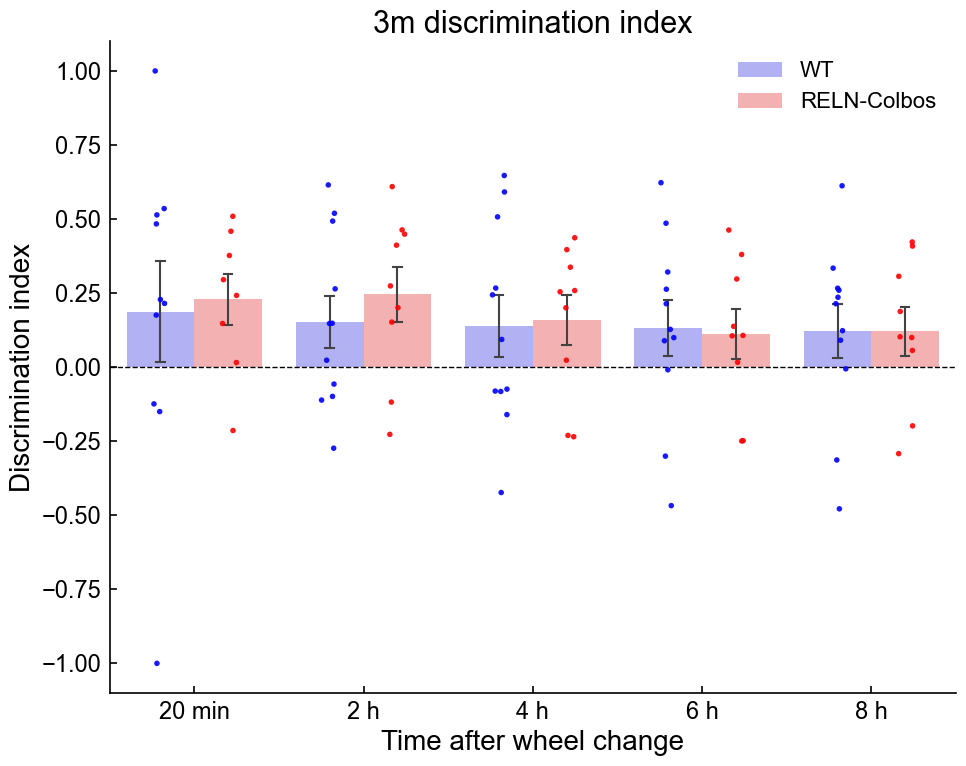

In [177]:
for age in AGE_ORDER:
    plot_di_timepoints_by_age(
        di_timepoint_df,
        age
    )

## 4.3 Novel/familiar DI: sample vs test

This analysis compares each mouse's discrimination index during the sample phase (whole sample phase, capped at 24 hours) with its discrimination index during the test phase (20 minutes, 2 hours and 24 hours).

During the sample phase, both objects are identical. Therefore, the index represents baseline side preference toward the side that will later contain the novel object.

During the test phase, the same calculation represents novel-object discrimination.

- Primary analysis: first 20 minutes after wheel change. 
- Addtional analysis: first 2 hours after wheel change.
- Sensitivity analysis: whole 24-hour phase.

The sample and test points are paired within each mouse.

In [178]:
# Novel/familiar DI: sample vs test

SAMPLE_TEST_PHASE_ORDER = ["sample", "test"]

def make_sample_test_di(data, cutoff_min=120):
    """
    Calculate one DI per mouse for sample and test phases.

    Sample phase:
        'novel_sec' means exploration of the side that will later contain
        the novel object. Because the sample objects are identical, this is
        a baseline side-preference index.

    Test phase:
        DI is the conventional novel-versus-familiar discrimination index.
    """
    required = {
        "Phase", "MouseSessionID", "KageID", "Cohort", "Age",
        "Genotype", "NOR_side", "time_min", "left_sec", "right_sec"
    }
    missing = required - set(data.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    temp = data[
        data["Phase"].astype(str).str.lower().isin(SAMPLE_TEST_PHASE_ORDER)
    ].copy()

    temp["Phase"] = temp["Phase"].astype(str).str.lower()
    temp["Genotype"] = temp["Genotype"].astype(str).str.strip()
    temp["Age"] = temp["Age"].astype(str).str.strip()

    # Sample: first 24 h of the phase (shorter phases use their real length).
    # Test: only the first cutoff_min minutes after the wheel change.
    temp["time_min"] = pd.to_numeric(temp["time_min"], errors="coerce")
    is_test = temp["Phase"].eq("test")
    temp = temp[
        temp["time_min"].ge(0)
        & (~is_test | temp["time_min"].lt(cutoff_min))
        & (is_test | temp["time_min"].lt(PHASE_CAP_MIN))
    ].copy()


    side = temp["NOR_side"].astype(str).str.upper().str[0]

    # Map both phases using the future novel side.
    temp["future_novel_side_sec"] = np.where(
        side.eq("L"),
        temp["left_sec"],
        temp["right_sec"],
    )
    temp["future_familiar_side_sec"] = np.where(
        side.eq("L"),
        temp["right_sec"],
        temp["left_sec"],
    )

    mouse_phase = (
        temp
        .groupby(
            [
                "MouseSessionID", "KageID", "Cohort",
                "Age", "Genotype", "Phase"
            ],
            as_index=False,
        )
        .agg(
            novel_side_sec=("future_novel_side_sec", "sum"),
            familiar_side_sec=("future_familiar_side_sec", "sum"),
        )
    )

    total = (
        mouse_phase["novel_side_sec"]
        + mouse_phase["familiar_side_sec"]
    )

    mouse_phase["DI"] = np.where(
        total > 0,
        (
            mouse_phase["novel_side_sec"]
            - mouse_phase["familiar_side_sec"]
        ) / total,
        np.nan,
    )

    mouse_phase["total_sec"] = total
    mouse_phase["explored"] = total > 0


    mouse_phase["window_h"] = cutoff_min / 60
    return mouse_phase


sample_test_di_20m = make_sample_test_di(main_binned, cutoff_min=20)
sample_test_di_2h = make_sample_test_di(main_binned, cutoff_min=120)    # 2 h
sample_test_di_24h = make_sample_test_di(main_binned, cutoff_min=1440)

display(sample_test_di_20m.head())


,MouseSessionID,KageID,Cohort,Age,Genotype,Phase,novel_side_sec,familiar_side_sec,DI,total_sec,explored,window_h
0,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,sample,219.5,493.0,-0.383860,712.5,True,0.333333
1,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,test,43.5,30.5,0.175676,74.0,True,0.333333
2,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage3,Kage3,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,sample,369.0,515.0,-0.165158,884.0,True,0.333333
3,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage3,Kage3,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,test,32.5,31.5,0.015625,64.0,True,0.333333
4,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage4,Kage4,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,sample,320.5,514.0,-0.231875,834.5,True,0.333333


## 20 minutes check
Check if exploration take place in the first 20 minutes of test phase, if no exploration happen, the animal is dropped in the 20 minutes analysis

In [179]:
# Mice with no exploration in the first 20 min of the test phase have no test DI.
# They are dropped from the 20-min paired plot and stats only (2 h and 24 h keep them).
no_test_20m = sample_test_di_20m[
    sample_test_di_20m["Phase"].eq("test")
    & ~sample_test_di_20m["explored"]
]

if not no_test_20m.empty:
    print("WARNING: no exploration in the first 20 min of the test phase. "
          "Dropped from the 20-min analysis:")
    for _, row in no_test_20m.iterrows():
        print(f"  {row['MouseSessionID']} ({row['Genotype']}, {row['Age']})")


  2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage16 (RELN-Colbos, 3m)
  2026-01-Jan-Feb_RELN-COLBOS_Coh2_Kage3 (WT, 3m)


## Statistics: novel/familiar DI, sample vs test

Paired comparison within each genotype for each test window: Shapiro-Wilk on the differences, then a paired
t-test (normal) or Wilcoxon signed-rank. Two-sided, raw p-values. The stars are drawn on the figures below.

In [180]:
# Novel/familiar DI, sample vs test within each age and genotype (two-sided, raw p-values).
# Sample = whole sample phase (first 24 h); test = first 20 min, 2 h and 24 h.
sample_test_paired_results = pd.concat(
    [
        paired_sample_vs_test(di_df, "DI", "Novel/familiar DI, sample vs test", window)
        for window, di_df in {"20 min": sample_test_di_20m, "2 h": sample_test_di_2h,
                              "24 h": sample_test_di_24h}.items()
    ],
    ignore_index=True,
)
display(sample_test_paired_results)

,analysis,test_window,Age,Genotype,n_pairs,sample_mean,test_mean,mean_change,shapiro_p_diff,normal,test,statistic,effect_size,effect_size_type,p,stars
0,"Novel/familiar DI, sample vs test",20 min,3m,WT,10,-0.019330,0.187824,0.207154,0.526564,True,paired t-test,1.014358,0.320768,Cohen's dz,0.336904,ns
1,"Novel/familiar DI, sample vs test",20 min,3m,RELN-Colbos,8,-0.098067,0.228982,0.327049,0.383957,True,paired t-test,2.702446,0.955459,Cohen's dz,0.030531,*
2,"Novel/familiar DI, sample vs test",2 h,3m,WT,11,-0.062075,0.151877,0.213952,0.684012,True,paired t-test,2.106379,0.635097,Cohen's dz,0.061415,ns
3,"Novel/familiar DI, sample vs test",2 h,3m,RELN-Colbos,9,-0.046283,0.246241,0.292525,0.058840,True,paired t-test,2.499765,0.833255,Cohen's dz,0.036956,*
4,"Novel/familiar DI, sample vs test",24 h,3m,WT,11,-0.062075,0.119375,0.181450,0.518136,True,paired t-test,2.128773,0.641849,Cohen's dz,0.059143,ns
5,"Novel/familiar DI, sample vs test",24 h,3m,RELN-Colbos,9,-0.046283,0.126910,0.173193,0.715927,True,paired t-test,2.699766,0.899922,Cohen's dz,0.027084,*


## Plot novel/familiar DI, sample vs test (test 20 min, 2 h and 24 h)

Saved PDF: Novel_familiar_DI_sample_vs_test.pdf (page 1: Novelfamiliar_DI_test_first_20_min_whole_sample)


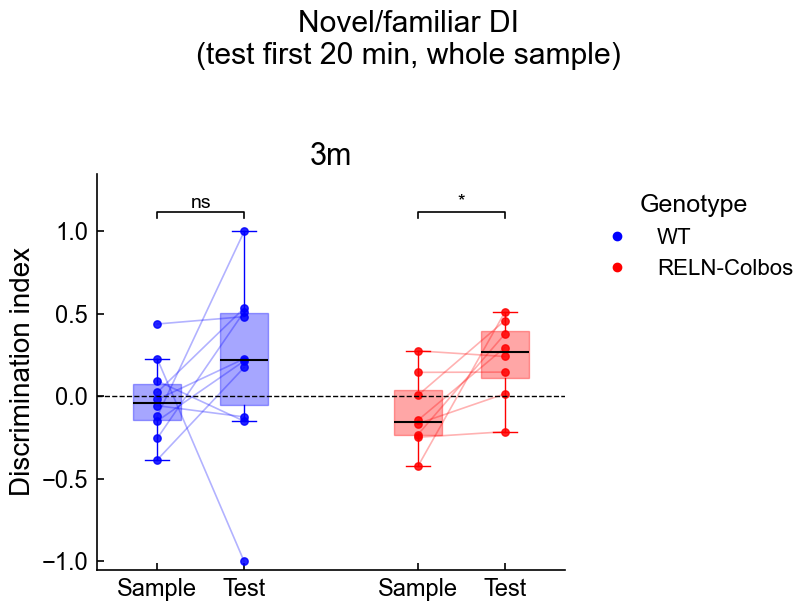

Saved PDF: Novel_familiar_DI_sample_vs_test.pdf (page 2: Novelfamiliar_DI_test_first_2_h_whole_sample)


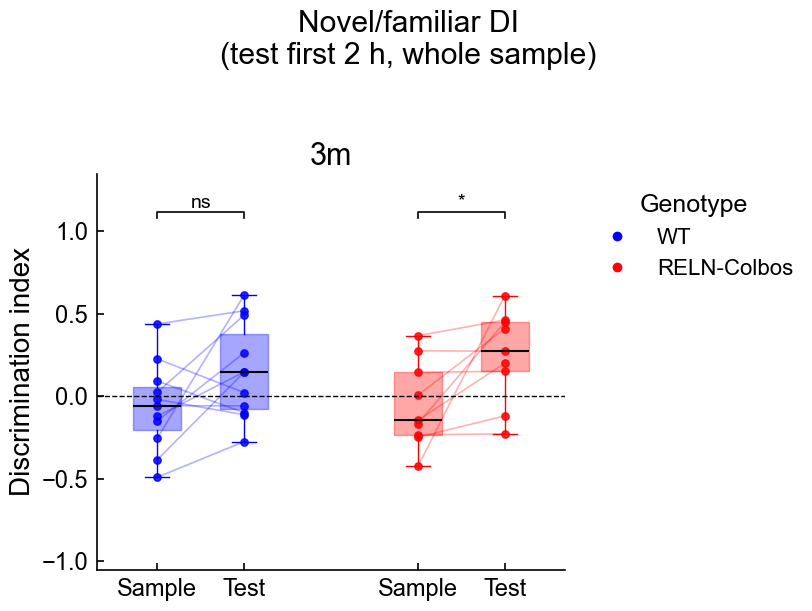

Saved PDF: Novel_familiar_DI_sample_vs_test.pdf (page 3: Novelfamiliar_DI_test_24_h_whole_sample)


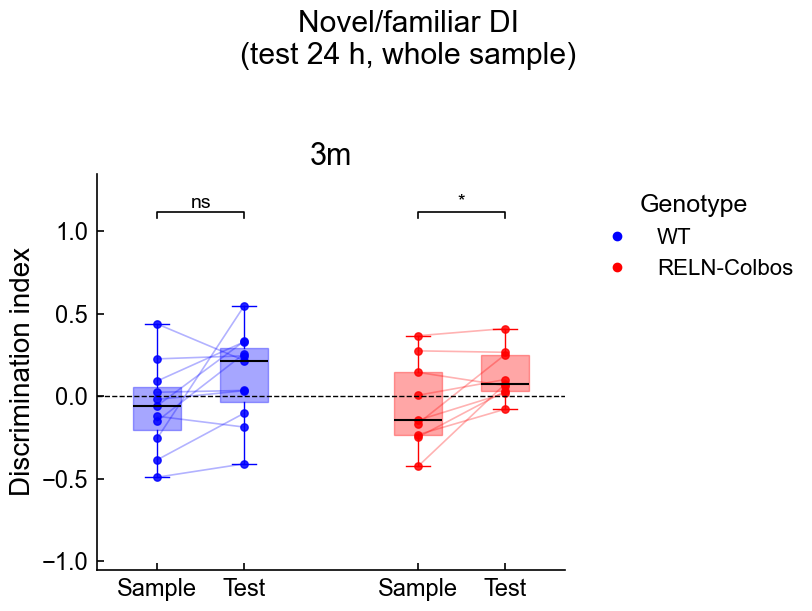

In [181]:
def plot_sample_vs_test_di(di_df, window_label=None, value_col="DI", title=None,
                           y_label="Discrimination index", stats_df=None, pdf_name=None):
    """
    Plot paired sample-versus-test values (value_col) for each age and genotype.
    stats_df: results of paired_sample_vs_test for this window; its stars are drawn above each genotype.
    pdf_name: file name for the saved PDF (default: made from the title).
    """
    plot_df = di_df[
        di_df["Genotype"].isin(GENO_ORDER)
    ].dropna(subset=[value_col]).copy()

    ages_present = [
        age for age in AGE_ORDER
        if age in plot_df["Age"].unique()
    ]

    fig, axes = plt.subplots(
        1,
        len(ages_present),
        figsize=(6 * len(ages_present) + 2.5, 6),  # + 2.5 leaves room for the legend
        sharey=True,
    )
    axes = np.atleast_1d(axes)

    for ax, age in zip(axes, ages_present):
        age_df = plot_df[plot_df["Age"] == age].copy()

        genotype_positions = {
            genotype: index * 3
            for index, genotype in enumerate(GENO_ORDER)
        }

        for genotype in GENO_ORDER:
            genotype_df = age_df[
                age_df["Genotype"] == genotype
            ].copy()

            paired = (
                genotype_df
                .pivot_table(
                    index="MouseSessionID",
                    columns="Phase",
                    values=value_col,
                    aggfunc="first",
                )
                .reindex(columns=["sample", "test"])
                .dropna(subset=["sample", "test"])
            )

            if paired.empty:
                continue

            x0 = genotype_positions[genotype]
            x_sample = x0
            x_test = x0 + 1
            color = GENO_COLORS.get(genotype, "black")

            for _, row in paired.iterrows():
                ax.plot(
                    [x_sample, x_test],
                    [row["sample"], row["test"]],
                    color=color,
                    alpha=0.30,
                    linewidth=1.2,
                    zorder=1,
                )
                ax.scatter(
                    [x_sample, x_test],
                    [row["sample"], row["test"]],
                    color=color,
                    alpha=0.85,
                    s=28,
                    zorder=2,
                )

            # Boxplots overlaid on paired observations.
            ax.boxplot(
                [paired["sample"], paired["test"]],
                positions=[x_sample, x_test],
                widths=0.55,
                patch_artist=True,
                showfliers=False,
                boxprops={
                    "facecolor": color,
                    "alpha": 0.35,
                    "edgecolor": color,
                },
                medianprops={"color": "black", "linewidth": 1.5},
                whiskerprops={"color": color},
                capprops={"color": color},
            )

            if stats_df is not None:
                match = stats_df[stats_df["Age"].eq(age) & stats_df["Genotype"].eq(genotype)]
                if not match.empty and match["stars"].iloc[0] != "NA":
                    draw_star_bracket(ax, x_sample, x_test, 1.08, match["stars"].iloc[0])

        tick_positions = []
        tick_labels = []
        for genotype in GENO_ORDER:
            x0 = genotype_positions[genotype]
            tick_positions.extend([x0, x0 + 1])
            tick_labels.extend(["Sample", "Test"])

        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels)
        ax.set_xlim(-0.7, max(tick_positions) + 0.7)
        ax.axhline(0, color="black", linestyle="--", linewidth=1)
        ax.set_ylim(-1.05, 1.35 if stats_df is not None else 1.05)
        ax.set_title(age)
        ax.set_xlabel("")
        format_axes(ax)

    # Genotype legend on the right: one coloured point per genotype
    legend_handles = [
        plt.Line2D(
            [0], [0],
            marker="o", linestyle="",
            color=GENO_COLORS.get(genotype, "black"),
            label=genotype,
        )
        for genotype in GENO_ORDER
    ]
    axes[-1].legend(
        handles=legend_handles,
        title="Genotype",
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),  # second number = height (1 = top of plot)
    )

    axes[0].set_ylabel(y_label)
    if title is None:
        title = f"Novel/familiar DI\n(test {window_label}, whole sample)"
    fig.suptitle(title, y=1.03)
    plt.tight_layout()
    save_figure_pdf(name=pdf_name)
    plt.show()


def window_stats(window):
    return sample_test_paired_results[sample_test_paired_results["test_window"].eq(window)]

# Primary figure
plot_sample_vs_test_di(sample_test_di_20m, "first 20 min", stats_df=window_stats("20 min"))

# Secondary figure
plot_sample_vs_test_di(sample_test_di_2h, "first 2 h", stats_df=window_stats("2 h"))

# Sensitivity figure
plot_sample_vs_test_di(sample_test_di_24h, "24 h", stats_df=window_stats("24 h"))


## 4.4 Change in DI (ΔDI) over time 
ΔDI = test DI (first *t* of the test phase) − sample DI (whole sample phase, capped at 24 h), one value per mouse.

Test windows: 20 min, 2, 4, 6 and 8 h (the same as 4.2), plus 24 h. The x-axis is categorical, so the windows are
evenly spaced on the plot even though they are not evenly spaced in time.

In [182]:
# Build Delta DI at cumulative test windows (20 min, 2, 4, 6, 8 and 24 h).
# Delta DI = test DI (0 to t) - whole sample DI

DELTA_DI_TIMEPOINTS_MIN = [20, 120, 240, 360, 480, 1440]  # same as 4.2, plus 24 h

delta_di_parts = []

for cutoff_min in DELTA_DI_TIMEPOINTS_MIN:
    temp = make_sample_test_di(
        main_binned,
        cutoff_min=cutoff_min,
    )

    temp = temp[
        temp["Genotype"].isin(GENO_ORDER)
    ].copy()

    # Put the paired sample and test values on the same row for each mouse.
    paired = (
        temp
        .pivot_table(
            index=[
                "MouseSessionID",
                "KageID",
                "Cohort",
                "Age",
                "Genotype",
            ],
            columns="Phase",
            values="DI",
            aggfunc="first",
        )
        .reindex(columns=["sample", "test"])
        .reset_index()
    )

    # Only calculate a change score when both phases are available
    # (mice with no test exploration in the window are dropped here).
    paired = paired.dropna(subset=["sample", "test"]).copy()

    paired["Delta_DI"] = paired["test"] - paired["sample"]
    paired["timepoint_min"] = cutoff_min
    paired["timepoint_h"] = cutoff_min / 60

    delta_di_parts.append(paired)

delta_di_over_time = pd.concat(
    delta_di_parts,
    ignore_index=True,
)

DELTA_DI_LABELS = [timepoint_label(t) for t in DELTA_DI_TIMEPOINTS_MIN]
delta_di_over_time["timepoint_label"] = pd.Categorical(
    delta_di_over_time["timepoint_min"].map(timepoint_label),
    categories=DELTA_DI_LABELS,
    ordered=True,
)

display(delta_di_over_time.head())

Phase,MouseSessionID,KageID,Cohort,Age,Genotype,sample,test,Delta_DI,timepoint_min,timepoint_h,timepoint_label
0,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,-0.383860,0.175676,0.559535,20,0.333333,20 min
1,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage3,Kage3,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,-0.165158,0.015625,0.180783,20,0.333333,20 min
2,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage4,Kage4,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,-0.231875,0.377049,0.608925,20,0.333333,20 min
3,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage5,Kage5,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,-0.017979,0.228346,0.246325,20,0.333333,20 min
4,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage8,Kage8,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,0.146067,0.147475,0.001407,20,0.333333,20 min


Saved PDF: Change_in_discrimination_index_from_sample_to_test.pdf


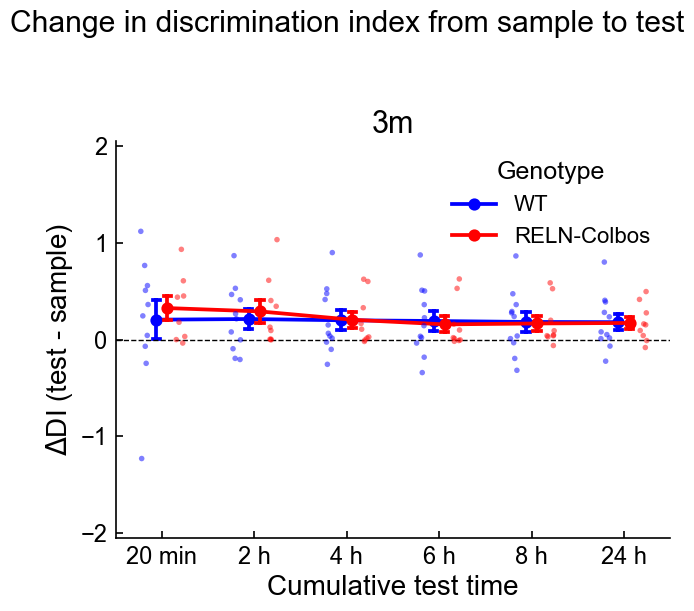

In [183]:
# Plot change in DI at the selected time points:
# Delta DI = test DI (0 to t) - whole sample DI

def plot_delta_di_over_time(delta_df):
    ages_present = [
        age for age in AGE_ORDER
        if age in delta_df["Age"].dropna().unique()
    ]

    fig, axes = plt.subplots(
        1,
        len(ages_present),
        figsize=(7 * len(ages_present), 6),
        sharey=True,
    )
    axes = np.atleast_1d(axes)

    for ax, age in zip(axes, ages_present):
        age_df = delta_df[
            delta_df["Age"].eq(age)
            & delta_df["Genotype"].isin(GENO_ORDER)
        ].copy()

        sns.pointplot(
            data=age_df,
            x="timepoint_label",
            y="Delta_DI",
            order=DELTA_DI_LABELS,
            hue="Genotype",
            hue_order=GENO_ORDER,
            palette=GENO_COLORS,
            errorbar="se",
            dodge=0.12,
            markers="o",
            linestyles="-",
            capsize=0.08,
            ax=ax,
        )

        sns.stripplot(
            data=age_df,
            x="timepoint_label",
            y="Delta_DI",
            order=DELTA_DI_LABELS,
            hue="Genotype",
            hue_order=GENO_ORDER,
            palette=GENO_COLORS,
            dodge=True,
            jitter=0.10,
            size=4,
            alpha=0.50,
            legend=False,
            ax=ax,
        )

        ax.axhline(0, color="black", linestyle="--", linewidth=1)
        ax.set_title(age)
        ax.set_xlabel("Cumulative test time")
        ax.set_ylabel(r"$\Delta$DI (test - sample)" if ax is axes[0] else "")
        ax.set_ylim(-2.05, 2.05)
        format_axes(ax)

        handles, labels = ax.get_legend_handles_labels()
        ax.legend(
            handles[:len(GENO_ORDER)],
            labels[:len(GENO_ORDER)],
            frameon=False,
            title="Genotype",
        )

    fig.suptitle("Change in discrimination index from sample to test", y=1.03)
    plt.tight_layout()
    save_figure_pdf()
    plt.show()


plot_delta_di_over_time(delta_di_over_time)

## 4.5 Side-bias DI: sample phase between genotypes, and sample vs test

Side-bias DI = (left − right) / (left + right), using exploration of the left and right objects in the kage.
+1 = only the left object, −1 = only the right object, 0 = no side preference. Mice with no exploration have no value.

Both phases use the first 24 h after their wheel change (shorter phases use their real length).

1. **Sample phase, between genotypes.** In the sample phase both objects are identical, so this is each mouse's
   baseline side preference. Statistics: below.
2. **Sample vs test, within each genotype (both 24 h).** Does a mouse keep the same left/right preference on
   the test day? Note: in the test phase, a preference for the novel object also moves this value towards the
   novel side. Statistics: below.

This differs from the 4.3 "sample DI", which uses the side that will later hold the novel object rather than
left/right. The size is the same; only the sign is flipped for mice whose novel object is on the right.

In [184]:
# Side-bias DI per mouse for the sample and test phases (first 24 h of each phase)

def make_side_bias_di(data, cutoff_min=PHASE_CAP_MIN):
    temp = data[data["Phase"].astype(str).str.lower().isin(["sample", "test"])].copy()
    temp["Phase"] = temp["Phase"].astype(str).str.lower()
    temp["time_min"] = pd.to_numeric(temp["time_min"], errors="coerce")
    temp = temp[temp["time_min"].ge(0) & temp["time_min"].lt(cutoff_min)]

    out = (
        temp
        .groupby(["MouseSessionID", "KageID", "Cohort", "Age", "Genotype", "NOR_side", "Phase"], as_index=False)
        .agg(left_sec=("left_sec", "sum"), right_sec=("right_sec", "sum"))
    )
    total = out["left_sec"] + out["right_sec"]
    out["side_bias_DI"] = ((out["left_sec"] - out["right_sec"]) / total).where(total > 0)
    return out


side_bias_24h = make_side_bias_di(main_binned)
side_bias_24h = side_bias_24h[side_bias_24h["Genotype"].isin(GENO_ORDER)]
side_bias_sample = side_bias_24h[side_bias_24h["Phase"].eq("sample")]

display(side_bias_24h.head())

,MouseSessionID,KageID,Cohort,Age,Genotype,NOR_side,Phase,left_sec,right_sec,side_bias_DI
0,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,L,sample,219.5,493.0,-0.383860
1,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,L,test,110.5,135.5,-0.101626
2,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage3,Kage3,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,L,sample,369.0,515.0,-0.165158
3,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage3,Kage3,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,L,test,275.0,164.5,0.251422
4,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage4,Kage4,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,R,sample,514.0,320.5,0.231875


## Statistics: side-bias DI

- Sample phase, between genotypes (unpaired): Shapiro-Wilk on each genotype, then Welch t-test (both normal)
  or Mann-Whitney U.
- Sample vs test, within each genotype (both 24 h): paired t-test.

Two-sided, raw p-values. The stars are drawn on the figures below.

In [185]:
# 1) Sample side-bias DI: genotype_1 vs genotype_2 within each age (unpaired)
#    Normality is checked first (Shapiro-Wilk on each genotype; shapiro_p_1 / shapiro_p_2 in the table).
#    Both normal -> unpaired t-test (Welch, does not assume equal variances); otherwise Mann-Whitney U.
side_bias_genotype_rows = []
for age in AGE_ORDER:
    sub = side_bias_sample[side_bias_sample["Age"].eq(age)]
    x = sub.loc[sub["Genotype"].eq(genotype_1), "side_bias_DI"].dropna()
    y = sub.loc[sub["Genotype"].eq(genotype_2), "side_bias_DI"].dropna()
    shapiro_p_1 = stats.shapiro(x).pvalue if len(x) >= 3 else np.nan
    shapiro_p_2 = stats.shapiro(y).pvalue if len(y) >= 3 else np.nan
    row = compare_two_groups(x, y)
    side_bias_genotype_rows.append({
        "analysis": "Sample side-bias DI (between genotypes)", "Age": age, "Phase": "sample",
        "test_window": "24 h", "comparison": f"{genotype_1} vs {genotype_2}",
        "shapiro_p_1": shapiro_p_1, "shapiro_p_2": shapiro_p_2,
        "normal": bool(shapiro_p_1 > 0.05 and shapiro_p_2 > 0.05),
        **row, "stars": p_stars(row["p"]),
    })
side_bias_genotype_results = pd.DataFrame(side_bias_genotype_rows)
display(side_bias_genotype_results)

# 2) Side-bias DI, sample vs test (both 24 h): paired t-test within each age and genotype
side_bias_paired_rows = []
for age in AGE_ORDER:
    for genotype in GENO_ORDER:
        paired = (
            side_bias_24h[side_bias_24h["Age"].eq(age) & side_bias_24h["Genotype"].eq(genotype)]
            .pivot_table(index="MouseSessionID", columns="Phase", values="side_bias_DI")
            .reindex(columns=["sample", "test"])
            .dropna()
        )
        n = len(paired)
        change = paired["test"] - paired["sample"]
        t, p = stats.ttest_rel(paired["test"], paired["sample"]) if n >= 3 else (np.nan, np.nan)
        side_bias_paired_rows.append({
            "analysis": "Side-bias DI, sample vs test (paired t-test)", "test": "paired t-test",
            "test_window": "24 h", "Age": age, "Genotype": genotype, "n_pairs": n,
            "sample_DI_mean": paired["sample"].mean(), "test_DI_mean": paired["test"].mean(),
            "mean_change": change.mean(),
            "cohen_dz": change.mean() / change.std() if n >= 3 else np.nan,
            "t": t, "df": n - 1, "p": p, "stars": p_stars(p),
        })
side_bias_paired_results = pd.DataFrame(side_bias_paired_rows)
display(side_bias_paired_results)

,analysis,Age,Phase,test_window,comparison,shapiro_p_1,shapiro_p_2,normal,n_1,n_2,mean_1,mean_2,median_1,median_2,test,statistic,effect_size,effect_size_type,p,stars
0,Sample side-bias DI (between genotypes),3m,sample,24 h,WT vs RELN-Colbos,0.950747,0.580529,True,11,9,0.068751,-0.045114,0.055935,-0.144654,Welch t-test,0.960332,0.41355,Hedges' g,0.350196,ns


,analysis,test,test_window,Age,Genotype,n_pairs,sample_DI_mean,test_DI_mean,mean_change,cohen_dz,t,df,p,stars
0,"Side-bias DI, sample vs test (paired t-test)",paired t-test,24 h,3m,WT,11,0.068751,-0.058840,-0.127591,-0.407100,-1.350199,10,0.206717,ns
1,"Side-bias DI, sample vs test (paired t-test)",paired t-test,24 h,3m,RELN-Colbos,9,-0.045114,-0.045586,-0.000473,-0.001776,-0.005328,8,0.995879,ns


Saved PDF: Side_bias_DI.pdf


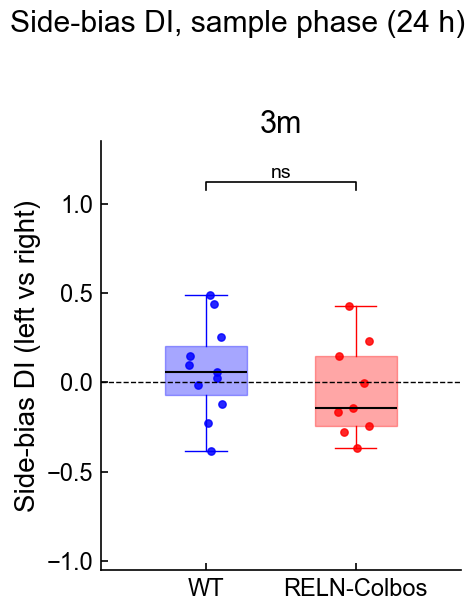

In [186]:
# Plot 1: sample-phase side-bias DI, genotypes side by side (one point per mouse)

ages_present = [age for age in AGE_ORDER if age in side_bias_sample["Age"].unique()]
fig, axes = plt.subplots(1, len(ages_present), figsize=(4 * len(ages_present) + 1, 6), sharey=True)
axes = np.atleast_1d(axes)

for ax, age in zip(axes, ages_present):
    age_df = side_bias_sample[side_bias_sample["Age"].eq(age)].dropna(subset=["side_bias_DI"])
    # Same box and point style as the 4.3 novel/familiar DI figures (plot_sample_vs_test_di)
    rng = np.random.default_rng(0)   # fixed jitter so the figure is the same on every run
    for x_pos, genotype in enumerate(GENO_ORDER):
        values = age_df.loc[age_df["Genotype"].eq(genotype), "side_bias_DI"]
        if values.empty:
            continue
        color = GENO_COLORS.get(genotype, "black")
        ax.scatter(
            x_pos + rng.uniform(-0.12, 0.12, len(values)), values,
            color=color, alpha=0.85, s=28, zorder=2,
        )
        ax.boxplot(
            [values],
            positions=[x_pos],
            widths=0.55,
            patch_artist=True,
            showfliers=False,
            boxprops={"facecolor": color, "alpha": 0.35, "edgecolor": color},
            medianprops={"color": "black", "linewidth": 1.5},
            whiskerprops={"color": color},
            capprops={"color": color},
        )

    ax.set_xticks(range(len(GENO_ORDER)))
    ax.set_xticklabels(GENO_ORDER)
    ax.set_xlim(-0.7, len(GENO_ORDER) - 0.3)
    match = side_bias_genotype_results[side_bias_genotype_results["Age"].eq(age)]
    if not match.empty and match["stars"].iloc[0] != "NA":
        draw_star_bracket(ax, 0, 1, 1.08, match["stars"].iloc[0])   # genotype_1 vs genotype_2

    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_ylim(-1.05, 1.35)
    ax.set_title(age)
    ax.set_xlabel("")
    ax.set_ylabel("Side-bias DI (left vs right)" if ax is axes[0] else "")
    format_axes(ax)

fig.suptitle("Side-bias DI, sample phase (24 h)", y=1.03)
plt.tight_layout()
save_figure_pdf(name="Side_bias_DI")
plt.show()

Saved PDF: Side_bias_DI_sample_test.pdf


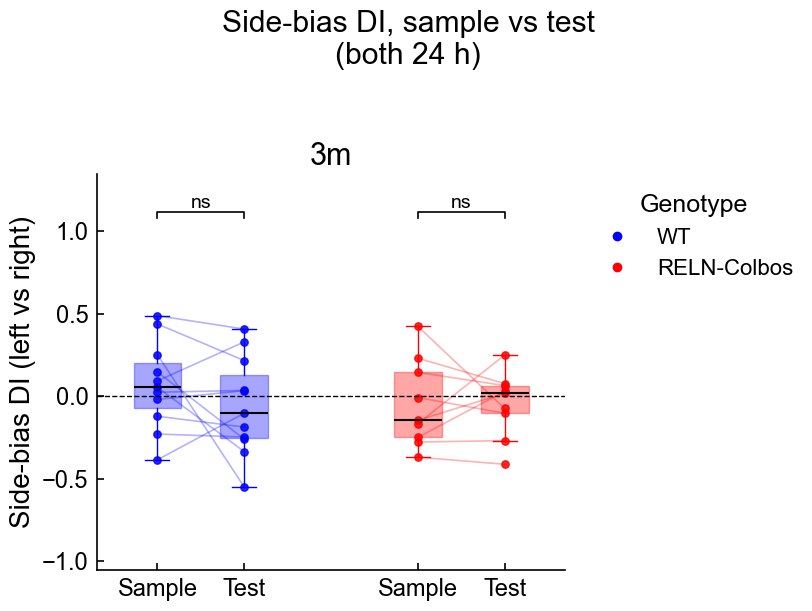

In [187]:
# Plot 2: side-bias DI, sample vs test (both 24 h), paired within each mouse
# Same layout as the 4.3 novel/familiar DI figures.

plot_sample_vs_test_di(
    side_bias_24h,
    value_col="side_bias_DI",
    title="Side-bias DI, sample vs test\n(both 24 h)",
    y_label="Side-bias DI (left vs right)",
    stats_df=side_bias_paired_results,
    pdf_name="Side_bias_DI_sample_test",
)

# 5. First approach

Which object each mouse explored first after the test wheel change (novel or familiar). Mice that did not explore
within the first-approach window are left out.

1. Count of mice choosing novel/familiar first.
2. Statistics: binomial test against 50% (each genotype) and Fisher's exact test between genotypes.
3. Figure: stacked bars of novel-first and familiar-first mice (counts inside), with the 50% chance line and the
   statistics as stars. Saved as `First_approach_novel_vs_familiar.pdf`.

In [188]:
if first_approach_df is not None:
    for col in ["Age", "Genotype", "FirstApproach"]:
        first_approach_df[col] = first_approach_df[col].astype(str).str.strip()

    first_approach_df["FirstApproach"] = first_approach_df["FirstApproach"].str.lower()
    first_approach_df = first_approach_df[first_approach_df["Age"].isin(AGE_ORDER)].copy()

    first_approach_counts = (
        first_approach_df
        .groupby(["Age", "Genotype", "FirstApproach"], as_index=False)
        .size()
        .rename(columns={"size": "count"})
    )

    display(first_approach_counts)
    # only mouse explored within the first 2h are included in the first approach summary
    first_approach_df = first_approach_df[first_approach_df["FirstApproach"].isin(["novel", "familiar"])].copy()

else:
    first_approach_counts = None


,Age,Genotype,FirstApproach,count
0,3m,RELN-Colbos,familiar,2
1,3m,RELN-Colbos,novel,7
2,3m,WT,familiar,6
3,3m,WT,novel,5


## Statistics: first approach

- **Binomial test** (each genotype): is the proportion of mice that go to the novel object first different from 50%?
- **Fisher's exact test**: does that proportion differ between the two genotypes?

Only mice that explored within the first-approach window are included. Two-sided, raw p-values. The stars are
drawn on the figure below: above each bar (binomial, vs 50%) and on a bracket between the genotypes (Fisher).

In [189]:
# First approach statistics (two-sided, raw p-values). Only mice that explored in the first-approach window
# (2 h after the test wheel change, set in postprocessing) are included.
# - Binomial test, each genotype: is the proportion of mice going to the novel object first different from 50%?
# - Fisher's exact test: does that proportion differ between genotype_1 and genotype_2? (2x2 table of counts)
# Groups with fewer than 3 mice are not tested.
binomial_rows, fisher_rows = [], []
if first_approach_df is not None:
    for age in AGE_ORDER:
        counts = {}
        for genotype in GENO_ORDER:
            sub = first_approach_df[first_approach_df["Age"].eq(age) & first_approach_df["Genotype"].eq(genotype)]
            n_total = len(sub)
            n_novel = int(sub["FirstApproach"].eq("novel").sum())
            counts[genotype] = (n_novel, n_total - n_novel)
            tested = n_total >= 3
            p = stats.binomtest(n_novel, n_total, 0.5).pvalue if tested else np.nan
            binomial_rows.append({
                "analysis": "First approach: novel first vs 50% (binomial)", "Age": age, "Genotype": genotype,
                "test_window": "2 h", "n_total": n_total, "n_novel": n_novel,
                "percent_novel": 100 * n_novel / n_total if n_total else np.nan,
                "test": "binomial test" if tested else "not tested (fewer than 3 mice)",
                "p": p, "stars": p_stars(p),
            })

        (novel_1, familiar_1), (novel_2, familiar_2) = counts[genotype_1], counts[genotype_2]
        n_1, n_2 = novel_1 + familiar_1, novel_2 + familiar_2
        if n_1 >= 3 and n_2 >= 3:
            odds_ratio, p = stats.fisher_exact([[novel_1, familiar_1], [novel_2, familiar_2]])
            test_name = "Fisher's exact test"
        else:
            odds_ratio, p, test_name = np.nan, np.nan, "not tested (fewer than 3 mice in a group)"
        fisher_rows.append({
            "analysis": "First approach: novel first, between genotypes (Fisher)", "Age": age,
            "test_window": "2 h", "comparison": f"{genotype_1} vs {genotype_2}", "n_1": n_1, "n_2": n_2,
            "test": test_name, "statistic": odds_ratio, "effect_size": odds_ratio,
            "effect_size_type": "odds ratio", "p": p, "stars": p_stars(p),
        })

first_approach_binomial_results = pd.DataFrame(binomial_rows)
first_approach_fisher_results = pd.DataFrame(fisher_rows)
display(first_approach_binomial_results)
display(first_approach_fisher_results)

,analysis,Age,Genotype,test_window,n_total,n_novel,percent_novel,test,p,stars
0,First approach: novel first vs 50% (binomial),3m,WT,2 h,11,5,45.454545,binomial test,1.000000,ns
1,First approach: novel first vs 50% (binomial),3m,RELN-Colbos,2 h,9,7,77.777778,binomial test,0.179688,ns


,analysis,Age,test_window,comparison,n_1,n_2,test,statistic,effect_size,effect_size_type,p,stars
0,"First approach: novel first, between genotypes...",3m,2 h,WT vs RELN-Colbos,11,9,Fisher's exact test,0.238095,0.238095,odds ratio,0.196809,ns


Saved PDF: First_object_approached_during_the_NOR_test.pdf


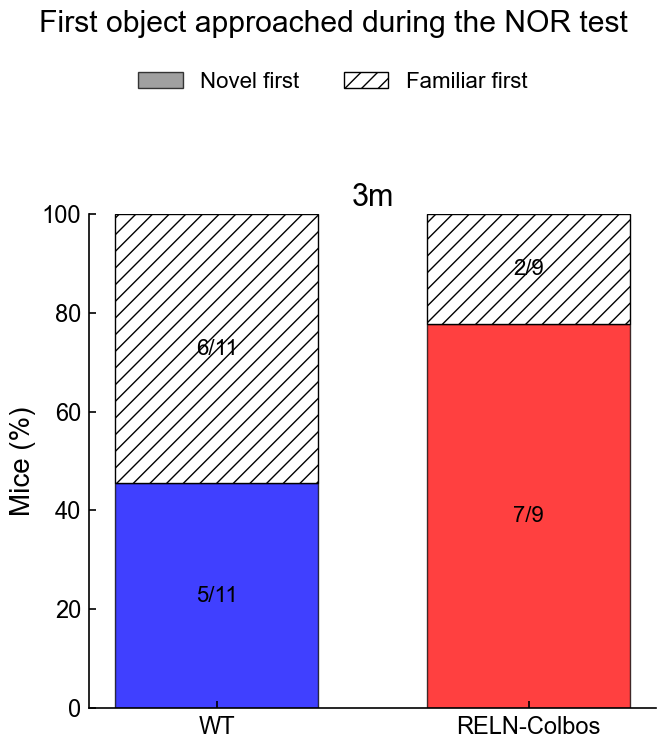

,Age,Genotype,n_total,n_novel,n_familiar,percent_novel,percent_familiar
0,3m,RELN-Colbos,9,7,2,77.777778,22.222222
1,3m,WT,11,5,6,45.454545,54.545455


In [191]:
if first_approach_df is not None:

    # --------------------------------------------
    # Create binary novel/familiar-first summary
    # --------------------------------------------
    first_binary = first_approach_df.copy()

    first_binary["novel_first"] = (
        first_binary["FirstApproach"] == "novel"
    ).astype(int)

    first_summary = (
        first_binary
        .groupby(["Age", "Genotype"], as_index=False)
        .agg(
            n_total=("novel_first", "count"),
            n_novel=("novel_first", "sum"),
        )
    )

    first_summary["n_familiar"] = (
        first_summary["n_total"]
        - first_summary["n_novel"]
    )

    first_summary["percent_novel"] = (
        first_summary["n_novel"]
        / first_summary["n_total"]
        * 100
    )

    first_summary["percent_familiar"] = (
        first_summary["n_familiar"]
        / first_summary["n_total"]
        * 100
    )

    # --------------------------------------------
    # Plot stacked bars
    # --------------------------------------------
    fig, axes = plt.subplots(
        1,
        len(AGE_ORDER),
        figsize=(4 * len(AGE_ORDER) + 3, 7),
        sharey=True,
        squeeze=False,
    )
    axes = axes.flatten()
    x = np.arange(len(GENO_ORDER))

    for ax, age in zip(axes, AGE_ORDER):

        sub = (
            first_summary[
                first_summary["Age"] == age
            ]
            .set_index("Genotype")
            .reindex(GENO_ORDER)
        )

        novel_vals = sub["percent_novel"].to_numpy()
        familiar_vals = sub["percent_familiar"].to_numpy()

        # Novel first
        ax.bar(
            x,
            novel_vals,
            width=0.65,
            color=[
                GENO_COLORS[g]
                for g in GENO_ORDER
            ],
            alpha=0.75,
            edgecolor="black",
            linewidth=1,
            label="Novel first"
        )

        # Familiar first
        ax.bar(
            x,
            familiar_vals,
            bottom=novel_vals,
            width=0.65,
            color="white",
            edgecolor="black",
            linewidth=1,
            hatch="//",
            label="Familiar first"
        )

        # ----------------------------------------
        # Add counts inside each segment
        # ----------------------------------------
        for i, genotype in enumerate(GENO_ORDER):

            if pd.isna(sub.loc[genotype, "n_total"]):
                continue

            n_total = int(sub.loc[genotype, "n_total"])
            n_novel = int(sub.loc[genotype, "n_novel"])
            n_familiar = int(sub.loc[genotype, "n_familiar"])

            # Novel count
            if novel_vals[i] > 8:
                ax.text(
                    i,
                    novel_vals[i] * 0.4,             # below the middle, so it never sits on the 50% line
                    f"{n_novel}/{n_total}",
                    ha="center",
                    va="center",
                    fontsize=16
                )

            # Familiar count
            if familiar_vals[i] > 8:
                ax.text(
                    i,
                    novel_vals[i] + familiar_vals[i] * 0.6,
                    f"{n_familiar}/{n_total}",
                    ha="center",
                    va="center",
                    fontsize=16
                )

        # ----------------------------------------
        # Chance line and statistics (from the statistics cell above):
        # binomial test vs 50% above each bar, Fisher's exact test between genotypes on the bracket
        # ----------------------------------------
        ax.axhline(50, color="black", linestyle="--", linewidth=1.2, zorder=3)

        for i, genotype in enumerate(GENO_ORDER):
            match = first_approach_binomial_results[
                first_approach_binomial_results["Age"].eq(age)
                & first_approach_binomial_results["Genotype"].eq(genotype)
            ]
            if not match.empty and match["stars"].iloc[0] != "NA":
                ax.text(i, 102, match["stars"].iloc[0], ha="center", va="bottom", fontsize=14)

        match = first_approach_fisher_results[first_approach_fisher_results["Age"].eq(age)]
        if not match.empty and match["stars"].iloc[0] != "NA":
            draw_star_bracket(ax, 0, 1, 112, match["stars"].iloc[0], height=3)

        ax.set_title(age)

        ax.set_xticks(x)
        ax.set_xticklabels(
            GENO_ORDER,
            rotation=0
        )

        ax.set_xlabel("")
        ax.set_ylabel(
            "Mice (%)"
            if age == AGE_ORDER[0]
            else ""
        )

        ax.set_ylim(0, 125)                  # room for the stars above 100%

        ax.set_yticks([
            0,
            20,
            40,
            60,
            80,
            100
        ])

        format_axes(ax)

    # --------------------------------------------
    # Shared legend
    # --------------------------------------------
    handles = [
        plt.Rectangle(
            (0, 0),
            1,
            1,
            facecolor="gray",
            alpha=0.75,
            edgecolor="black",
            label="Novel first"
        ),
        plt.Rectangle(
            (0, 0),
            1,
            1,
            facecolor="white",
            edgecolor="black",
            hatch="//",
            label="Familiar first"
        ),
        plt.Line2D([0], [0], color="black", linestyle="--", linewidth=1.2, label="Chance (50%)"),
    ]

    axes[-1].legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        frameon=False
    )

    fig.suptitle(
        "Object approached first in the test phase",
        y=1.03
    )

    plt.tight_layout()

    save_figure_pdf(name="First_approach_novel_vs_familiar")

    plt.show()

    display(first_summary)

## Save analysis summaries

Saved to `analysis_summaries/`:
- `average_exploration_24h_summary.csv`: mean ± SEM exploration per minute (data behind the 3.3 plots;
  the 4 h and 8 h plots are the first 240 / 480 minutes of it)
- `cumulative_exploration_24h_summary.csv`: mean ± SEM cumulative exploration per minute (3.4 plots;
  2 h and 10 h are the first 120 / 600 minutes)
- `cumulative_DI_at_timepoints_per_mouse.csv`: test DI per mouse at 20 min, 2, 4, 6 and 8 h (4.2)

Per-mouse totals, sample/test DI and first approach are already in the `NOR_MASTER_*.csv` files.

In [192]:
ANALYSIS_OUTPUT = MASTER_OUTPUT / "analysis_summaries"
ANALYSIS_OUTPUT.mkdir(exist_ok=True)

avg_24h_summary.to_csv(ANALYSIS_OUTPUT / "average_exploration_24h_summary.csv", index=False)
cum_24h_summary.to_csv(ANALYSIS_OUTPUT / "cumulative_exploration_24h_summary.csv", index=False)
di_timepoint_df.to_csv(ANALYSIS_OUTPUT / "cumulative_DI_at_timepoints_per_mouse.csv", index=False)

print("Saved summaries to:", ANALYSIS_OUTPUT)

Saved summaries to: /Users/jiatongsun/SmartKages_RELN-Colbos_analysis/NOR_MASTER_RELN-COLBOS/analysis_summaries


# 6. Statistics overview

Every test is run next to its figure (3.2, 4.3, 4.5 and 5; helpers in 2.4). This section collects them into one
table, shows an overview, and saves it. One value per mouse in every test; all tests are two-sided with raw
p-values.

## 6.1 Overview of all tests

In [193]:
nor_statistics = pd.concat(
    [total_exploration_results,
     sample_test_paired_results,
     side_bias_genotype_results,
     side_bias_paired_results,
     first_approach_binomial_results,
     first_approach_fisher_results],
    ignore_index=True,
)

# Short overview: what was compared, which test, group sizes, p-value and stars
overview_cols = ["analysis", "Age", "Phase", "test_window", "comparison", "Genotype",
                 "test", "n_1", "n_2", "n_pairs", "n_total", "p", "stars"]
statistics_overview = nor_statistics[[c for c in overview_cols if c in nor_statistics.columns]]

n_tested = nor_statistics["p"].notna().sum()
n_significant = nor_statistics["p"].lt(0.05).sum()
print(f"{len(nor_statistics)} comparisons, {n_tested} tested, {n_significant} with p < 0.05")
display(statistics_overview)

print("Significant results (p < 0.05):")
display(statistics_overview[statistics_overview["p"].lt(0.05)])

15 comparisons, 15 tested, 3 with p < 0.05


,analysis,Age,Phase,test_window,comparison,Genotype,test,n_1,n_2,n_pairs,n_total,p,stars
0,Total exploration (between genotypes),3m,sample,24 h,WT vs RELN-Colbos,NaN,Welch t-test,11.0,9.0,NaN,NaN,0.702506,ns
1,Total exploration (between genotypes),3m,ITI_baseline,24 h,WT vs RELN-Colbos,NaN,Welch t-test,11.0,9.0,NaN,NaN,0.465459,ns
2,Total exploration (between genotypes),3m,test,24 h,WT vs RELN-Colbos,NaN,Mann-Whitney U,11.0,9.0,NaN,NaN,0.761208,ns
3,"Novel/familiar DI, sample vs test",3m,NaN,20 min,NaN,WT,paired t-test,NaN,NaN,10.0,NaN,0.336904,ns
4,"Novel/familiar DI, sample vs test",3m,NaN,20 min,NaN,RELN-Colbos,paired t-test,NaN,NaN,8.0,NaN,0.030531,*
5,"Novel/familiar DI, sample vs test",3m,NaN,2 h,NaN,WT,paired t-test,NaN,NaN,11.0,NaN,0.061415,ns
6,"Novel/familiar DI, sample vs test",3m,NaN,2 h,NaN,RELN-Colbos,paired t-test,NaN,NaN,9.0,NaN,0.036956,*
7,"Novel/familiar DI, sample vs test",3m,NaN,24 h,NaN,WT,paired t-test,NaN,NaN,11.0,NaN,0.059143,ns
8,"Novel/familiar DI, sample vs test",3m,NaN,24 h,NaN,RELN-Colbos,paired t-test,NaN,NaN,9.0,NaN,0.027084,*
9,Sample side-bias DI (between genotypes),3m,sample,24 h,WT vs RELN-Colbos,NaN,Welch t-test,11.0,9.0,NaN,NaN,0.350196,ns


Significant results (p < 0.05):


,analysis,Age,Phase,test_window,comparison,Genotype,test,n_1,n_2,n_pairs,n_total,p,stars
4,"Novel/familiar DI, sample vs test",3m,NaN,20 min,NaN,RELN-Colbos,paired t-test,NaN,NaN,8.0,NaN,0.030531,*
6,"Novel/familiar DI, sample vs test",3m,NaN,2 h,NaN,RELN-Colbos,paired t-test,NaN,NaN,9.0,NaN,0.036956,*
8,"Novel/familiar DI, sample vs test",3m,NaN,24 h,NaN,RELN-Colbos,paired t-test,NaN,NaN,9.0,NaN,0.027084,*


## 6.2 Save statistics

All results (3.2, 4.3, 4.5 and 5) in one table, `statistics/NOR_statistics.csv` (one row per test; the `analysis` column
says which). Columns that don't apply to a test are left empty.

In [194]:
STATS_OUTPUT = MASTER_OUTPUT / "statistics"
STATS_OUTPUT.mkdir(exist_ok=True)

nor_statistics.to_csv(STATS_OUTPUT / "NOR_statistics.csv", index=False)
print("Saved:", STATS_OUTPUT / "NOR_statistics.csv")

Saved: /Users/jiatongsun/SmartKages_RELN-Colbos_analysis/NOR_MASTER_RELN-COLBOS/statistics/NOR_statistics.csv


# For Aimi's Analysis: 6-month cohort split and change in DI over time

The following sections are used for Aimi's 6 month cohort analysis. Some function may still need update

**Saving is off by default:** set `SAVE_AIMI_OUTPUTS = True` in the next cell to save the figures and tables from these sections.

This section adds the two requested NOR analyses:

1. Split the 6-month mice by cohort for novel/familiar DI.
2. Calculate the within-mouse change in DI at 2, 4, 6, and 8 hours:

\[
\Delta DI = DI_{\mathrm{test}} - DI_{\mathrm{sample}}
\]

A positive value means discrimination increased from the sample phase to the
test phase. A value near zero means little change, and a negative value means
the test DI was lower than the sample-side preference.


In [195]:
# ----------------------------------------------------------
# SWITCH: save outputs from the sections below?
# These sections were written for Aimi's 6-month cohort (NLGF study).
# False = the cells still run and plot, but no figures, PDFs or CSVs are saved.
# True  = save everything as before.
# ----------------------------------------------------------
SAVE_AIMI_OUTPUTS = False

In [196]:
# Build sample and test DI values at cumulative 2, 4, 6, and 8 h windows.

AIMI_DELTA_DI_TIMEPOINTS_MIN = [120, 240, 360, 480]
DELTA_DI_GENOTYPES = ["WT", "RELN-Colbos"]  #<----------------- Add more genotypes if desired
# GENO_COLORS (genotype -> colour) is defined in the formatting cell at the top;
# it is not overwritten here so later plots can look colours up by genotype.

delta_di_parts = []

for cutoff_min in AIMI_DELTA_DI_TIMEPOINTS_MIN:
    temp = make_sample_test_di(
        main_binned,
        cutoff_min=cutoff_min,
    )

    temp = temp[
        temp["Genotype"].isin(DELTA_DI_GENOTYPES)
    ].copy()

    # Put the paired sample and test values on the same row for each mouse.
    paired = (
        temp
        .pivot_table(
            index=[
                "MouseSessionID",
                "KageID",
                "Cohort",
                "Age",
                "Genotype",
            ],
            columns="Phase",
            values="DI",
            aggfunc="first",
        )
        .reset_index()
    )

    # Only calculate a change score when both phases are available.
    paired = paired.dropna(subset=["sample", "test"]).copy()

    paired["Delta_DI"] = paired["test"] - paired["sample"]
    paired["timepoint_min"] = cutoff_min
    paired["timepoint_h"] = cutoff_min / 60

    delta_di_parts.append(paired)

aimi_delta_di_over_time = pd.concat(
    delta_di_parts,
    ignore_index=True,
)

aimi_delta_di_over_time["timepoint_h"] = pd.Categorical(
    aimi_delta_di_over_time["timepoint_h"],
    categories=[2, 4, 6, 8],
    ordered=True,
)

display(aimi_delta_di_over_time.head())


Phase,MouseSessionID,KageID,Cohort,Age,Genotype,sample,test,Delta_DI,timepoint_min,timepoint_h
0,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,-0.383860,0.147368,0.531228,120,2
1,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage3,Kage3,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,-0.165158,0.449057,0.614215,120,2
2,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage4,Kage4,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,-0.231875,-0.226994,0.004882,120,2
3,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage5,Kage5,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,-0.017979,-0.111111,-0.093132,120,2
4,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage8,Kage8,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,0.146067,0.152137,0.006069,120,2


In [197]:
# Plot the raw novel/familiar TEST DI over time with the 6-month cohorts split.

test_di_6m_split = aimi_delta_di_over_time[
    aimi_delta_di_over_time["Age"].eq("6m")
].copy()

cohorts_6m = sorted(
    test_di_6m_split["Cohort"]
    .dropna()
    .astype(str)
    .unique()
)

if len(cohorts_6m) == 0:
    print("No 6-month cohort data were found.")
else:
    fig, axes = plt.subplots(
        1,
        len(cohorts_6m),
        figsize=(7 * len(cohorts_6m), 6),
        sharey=True,
    )
    axes = np.atleast_1d(axes)

    for ax, cohort in zip(axes, cohorts_6m):
        cohort_df = test_di_6m_split[
            test_di_6m_split["Cohort"].astype(str).eq(cohort)
        ].copy()

        sns.pointplot(
            data=cohort_df,
            x="timepoint_h",
            y="test",
            hue="Genotype",
            hue_order=DELTA_DI_GENOTYPES,
            palette=GENO_COLORS,
            errorbar="se",
            dodge=0.12,
            markers="o",
            linestyles="-",
            capsize=0.08,
            ax=ax,
        )

        sns.stripplot(
            data=cohort_df,
            x="timepoint_h",
            y="test",
            hue="Genotype",
            hue_order=DELTA_DI_GENOTYPES,
            palette=GENO_COLORS,
            dodge=True,
            jitter=0.10,
            size=4,
            alpha=0.55,
            legend=False,
            ax=ax,
        )

        ax.axhline(0, color="black", linestyle="--", linewidth=1)
        ax.set_title(f"6m: {cohort}")
        ax.set_xlabel("Cumulative time after wheel change (h)")
        ax.set_ylabel("Novel/familiar DI" if ax is axes[0] else "")
        ax.set_ylim(-1.05, 1.05)
        format_axes(ax)

        handles, labels = ax.get_legend_handles_labels()
        ax.legend(
            handles[:len(DELTA_DI_GENOTYPES)],
            labels[:len(DELTA_DI_GENOTYPES)],
            frameon=False,
            title="Genotype",
        )

    fig.suptitle(
        "6-month novel/familiar test DI",
        y=1.03,
    )
    plt.tight_layout()
    if SAVE_AIMI_OUTPUTS:
        save_figure_pdf()
plt.show()


No 6-month cohort data were found.


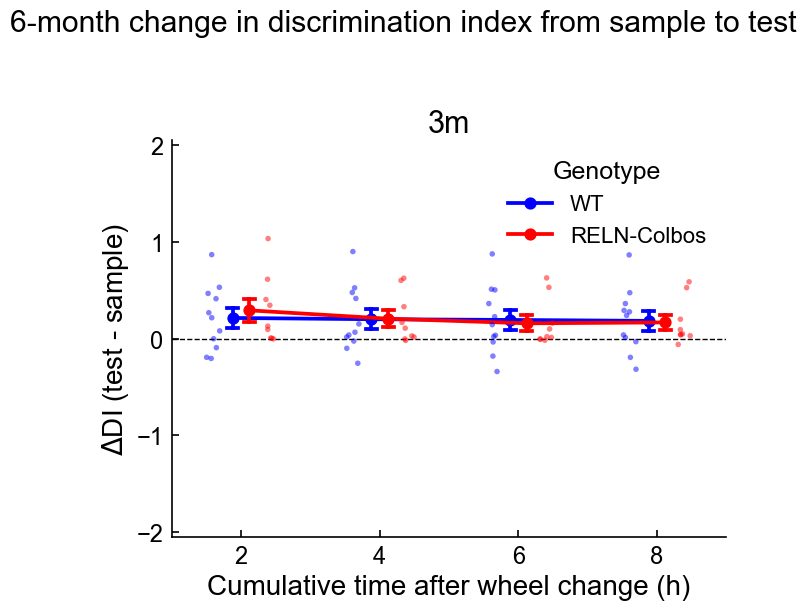

In [198]:
# Plot change in DI over time:
# Delta DI = test DI - sample DI

def plot_aimi_delta_di_over_time(delta_df):
    ages_present = [
        age for age in AGE_ORDER
        if age in delta_df["Age"].dropna().unique()
    ]

    fig, axes = plt.subplots(
        1,
        len(ages_present),
        figsize=(7 * len(ages_present), 6),
        sharey=True,
    )
    axes = np.atleast_1d(axes)

    for ax, age in zip(axes, ages_present):
        age_df = delta_df[
            delta_df["Genotype"].isin(DELTA_DI_GENOTYPES)
        ].copy()

        sns.pointplot(
            data=age_df,
            x="timepoint_h",
            y="Delta_DI",
            hue="Genotype",
            hue_order=DELTA_DI_GENOTYPES,
            palette=GENO_COLORS,
            errorbar="se",
            dodge=0.12,
            markers="o",
            linestyles="-",
            capsize=0.08,
            ax=ax,
        )

        sns.stripplot(
            data=age_df,
            x="timepoint_h",
            y="Delta_DI",
            hue="Genotype",
            hue_order=DELTA_DI_GENOTYPES,
            palette=GENO_COLORS,
            dodge=True,
            jitter=0.10,
            size=4,
            alpha=0.50,
            legend=False,
            ax=ax,
        )

        ax.axhline(
            0,
            color="black",
            linestyle="--",
            linewidth=1,
        )
        ax.set_title(age)
        ax.set_xlabel("Cumulative time after wheel change (h)")
        ax.set_ylabel(
            r"$\Delta$DI (test - sample)"
            if ax is axes[0]
            else ""
        )
        ax.set_ylim(-2.05, 2.05)
        format_axes(ax)

        handles, labels = ax.get_legend_handles_labels()
        ax.legend(
            handles[:len(DELTA_DI_GENOTYPES)],
            labels[:len(DELTA_DI_GENOTYPES)],
            frameon=False,
            title="Genotype",
        )

    fig.suptitle(
        "6-month change in discrimination index from sample to test",
        y=1.03,
    )
    plt.tight_layout()
    if SAVE_AIMI_OUTPUTS:
        save_figure_pdf()
plt.show()


plot_aimi_delta_di_over_time(aimi_delta_di_over_time)


In [199]:
# Split the 6-month Delta DI plot by cohort as well.

delta_di_6m = aimi_delta_di_over_time[
    aimi_delta_di_over_time["Age"].eq("6m")
].copy()

cohorts_6m = sorted(
    delta_di_6m["Cohort"]
    .dropna()
    .astype(str)
    .unique()
)

if len(cohorts_6m) == 0:
    print("No 6-month cohort data were found.")
else:
    fig, axes = plt.subplots(
        1,
        len(cohorts_6m),
        figsize=(7 * len(cohorts_6m), 6),
        sharey=True,
    )
    axes = np.atleast_1d(axes)

    for ax, cohort in zip(axes, cohorts_6m):
        cohort_df = delta_di_6m[
            delta_di_6m["Cohort"].astype(str).eq(cohort)
        ].copy()

        sns.pointplot(
            data=cohort_df,
            x="timepoint_h",
            y="Delta_DI",
            hue="Genotype",
            hue_order=DELTA_DI_GENOTYPES,
            palette=GENO_COLORS,
            errorbar="se",
            dodge=0.12,
            markers="o",
            linestyles="-",
            capsize=0.08,
            ax=ax,
        )

        sns.stripplot(
            data=cohort_df,
            x="timepoint_h",
            y="Delta_DI",
            hue="Genotype",
            hue_order=DELTA_DI_GENOTYPES,
            palette=GENO_COLORS,
            dodge=True,
            jitter=0.10,
            size=4,
            alpha=0.55,
            legend=False,
            ax=ax,
        )

        ax.axhline(0, color="black", linestyle="--", linewidth=1)
        ax.set_title(f"6m: {cohort}")
        ax.set_xlabel("Cumulative time after wheel change (h)")
        ax.set_ylabel(
            r"$\Delta$DI (test - sample)"
            if ax is axes[0]
            else ""
        )
        ax.set_ylim(-2.05, 2.05)
        format_axes(ax)

        handles, labels = ax.get_legend_handles_labels()
        ax.legend(
            handles[:len(DELTA_DI_GENOTYPES)],
            labels[:len(DELTA_DI_GENOTYPES)],
            frameon=False,
            title="Genotype",
        )

    fig.suptitle(
        "6-month change in DI",
        y=1.03,
    )
    plt.tight_layout()
    if SAVE_AIMI_OUTPUTS:
        save_figure_pdf()
plt.show()


No 6-month cohort data were found.


In [200]:
# Save the new tables.

if SAVE_AIMI_OUTPUTS:
    DELTA_DI_OUTPUT = MASTER_OUTPUT / "delta_DI_over_time"
    DELTA_DI_OUTPUT.mkdir(exist_ok=True)

    aimi_delta_di_over_time.to_csv(
        DELTA_DI_OUTPUT / "sample_to_test_delta_DI_2h_4h_6h_8h.csv",
        index=False,
    )

    # test_di_6m_split.to_csv(
        #DELTA_DI_OUTPUT / "6m_test_DI_split_by_cohort.csv",
        #index=False,
    #)

    if "delta_mixed_model_table" in globals():
        delta_mixed_model_table.to_csv(
            DELTA_DI_OUTPUT / "delta_DI_mixed_model_coefficients.csv",
            index=False,
        )

    print("Saved Delta DI outputs to:", DELTA_DI_OUTPUT)

else:
    print("Aimi outputs not saved (SAVE_AIMI_OUTPUTS = False)")

Aimi outputs not saved (SAVE_AIMI_OUTPUTS = False)


In [201]:
# ----------------------------------------------------------
# Helpers used by the paired Sample-versus-Test statistics and figure below
# ----------------------------------------------------------
from scipy.stats import shapiro, ttest_rel, wilcoxon
from statsmodels.stats.multitest import multipletests

SAMPLE_TEST_PHASES = ["sample", "test"]

REQUESTED_STATS_OUTPUT = MASTER_OUTPUT / "requested_statistics"
if SAVE_AIMI_OUTPUTS:
    REQUESTED_STATS_OUTPUT.mkdir(exist_ok=True)


def shapiro_result(values):
    """Shapiro-Wilk on the values; 'normal' is False if fewer than 3 values."""
    x = pd.to_numeric(pd.Series(values), errors="coerce").dropna()
    if len(x) < 3:
        return {"W": np.nan, "p": np.nan, "normal": False}
    W, p = shapiro(x)
    return {"W": W, "p": p, "normal": bool(p > 0.05)}


def compare_sample_test_paired(df, context=None):
    """Paired Sample-versus-Test comparison of DI (one value per mouse and phase)."""
    return compare_sample_test_paired_value(df, value_col="DI", context=context)


def add_holm_and_stars(results, p_col="p_raw"):
    """Add Holm-corrected p-values (p_holm) and stars based on them."""
    results = results.copy()
    results["p_holm"] = np.nan
    valid = results[p_col].notna()
    if valid.any():
        results.loc[valid, "p_holm"] = multipletests(results.loc[valid, p_col], method="holm")[1]
    results["stars"] = results["p_holm"].apply(p_to_stars)
    return results


def add_bracket(ax, x1, x2, y, label, height=0.03, fontsize=14):
    """Draw a significance bracket from x1 to x2 at height y with a label."""
    ax.plot([x1, x1, x2, x2], [y, y + height, y + height, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y + height, label, ha="center", va="bottom", fontsize=fontsize)


def compare_sample_test_paired_value(df, value_col, context=None):
    """Paired Sample-versus-Test analysis for a specified outcome."""
    context = {} if context is None else dict(context)

    paired = (
        df.pivot_table(
            index="MouseSessionID",
            columns="Phase",
            values=value_col,
            aggfunc="first",
        )
        .dropna(subset=SAMPLE_TEST_PHASES)
    )

    difference = paired["test"] - paired["sample"]
    diff_norm = shapiro_result(difference)

    result = {
        **context,
        "comparison": "Whole Sample vs Test",
        "value_col": value_col,
        "n_pairs": len(paired),
        "sample_mean": paired["sample"].mean() if len(paired) else np.nan,
        "test_mean": paired["test"].mean() if len(paired) else np.nan,
        "mean_change_test_minus_sample": (
            difference.mean() if len(difference) else np.nan
        ),
        "difference_shapiro_W": diff_norm["W"],
        "difference_shapiro_p": diff_norm["p"],
        "differences_normal": diff_norm["normal"],
        "test": "not enough paired data",
        "statistic": np.nan,
        "p_raw": np.nan,
    }

    if len(paired) < 2:
        return result

    if diff_norm["normal"]:
        statistic, p = ttest_rel(
            paired["test"], paired["sample"], nan_policy="omit"
        )
        result["test"] = "Paired t-test"
    else:
        try:
            statistic, p = wilcoxon(
                paired["test"],
                paired["sample"],
                alternative="two-sided",
                zero_method="wilcox",
            )
            result["test"] = "Wilcoxon signed-rank"
        except ValueError:
            statistic, p = np.nan, np.nan
            result["test"] = "Wilcoxon unavailable"

    result["statistic"] = statistic
    result["p_raw"] = p
    return result



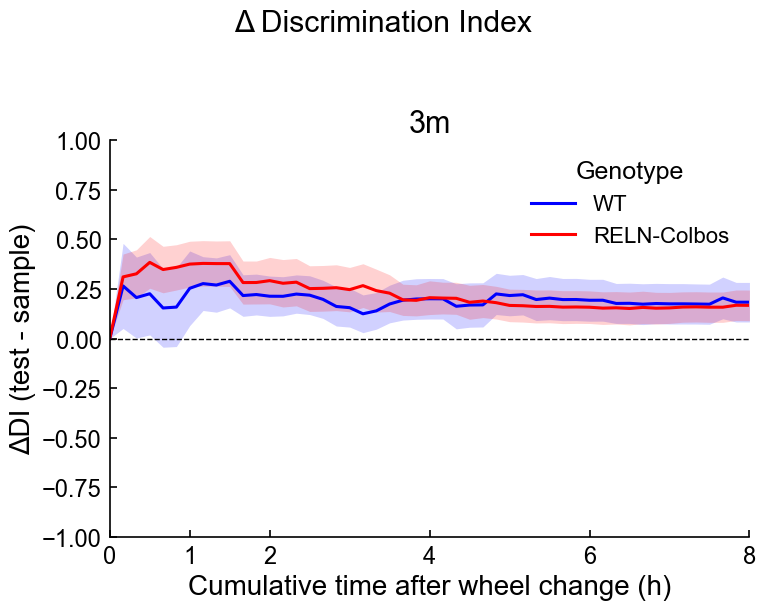

In [202]:
# 3. Analyse Delta DI as a continuous time-course rather than as isolated timepoints.

import statsmodels.formula.api as smf

delta_curve_model_results = []
delta_curve_models = {}


def fit_delta_curve_mixed_model(data, age):
    model_df = data[
        data["Age"].eq(age)
        & data["Genotype"].isin(DELTA_DI_GENOTYPES)
    ].dropna(
        subset=[
            "Delta_DI",
            "time_h",
            "Genotype",
            "MouseSessionID",
        ]
    ).copy()

    model_df["Genotype"] = pd.Categorical(
        model_df["Genotype"],
        categories=DELTA_DI_GENOTYPES,
        ordered=True,
    )

    if (
        model_df["MouseSessionID"].nunique() < 3
        or model_df["Genotype"].nunique() < 2
    ):
        print(f"{age}: insufficient data for Delta DI curve model.")
        return None

    # Time is treated as a continuous variable.
    # The interaction tests whether WT and NLGF change differently over time.
    model = smf.mixedlm(
        "Delta_DI ~ C(Genotype) * time_h",
        data=model_df,
        groups=model_df["MouseSessionID"],
        re_formula="1",
    )

    try:
        result = model.fit(
            reml=False,
            method="lbfgs",
            maxiter=2000,
        )
    except Exception:
        result = model.fit(
            reml=False,
            method="powell",
            maxiter=2000,
        )

    print("\n" + "=" * 80)
    print(f"{age}: Delta DI continuous time-course")
    print("=" * 80)
    print(result.summary())

    coefficient_table = (
        result.summary2()
        .tables[1]
        .reset_index()
        .rename(columns={"index": "term"})
    )
    coefficient_table["Age"] = age
    coefficient_table["model"] = (
        "Delta_DI ~ Genotype * continuous time + random intercept(Mouse)"
    )
    delta_curve_model_results.append(coefficient_table)

    return result





def plot_delta_di_curve(delta_df):
    # Add time-zero baseline:
    # before any test exploration has occurred, Delta DI = 0
    baseline_rows = (
        delta_df[
            [
                "MouseSessionID",
                "Age",
                "Genotype",
            ]
        ]
        .drop_duplicates()
        .copy()
    )

    baseline_rows["time_h"] = 0.0
    baseline_rows["Delta_DI"] = 0.0

    plot_df = pd.concat(
        [
            delta_df,
            baseline_rows,
        ],
        ignore_index=True,
    )
    fig, axes = plt.subplots(
        1,
        len(AGE_ORDER),
        figsize=(6 * len(AGE_ORDER) + 2, 6),
        sharey=True,
    )
    axes = np.atleast_1d(axes)

    summary = (
        plot_df
        .groupby(
            ["Age", "Genotype", "time_h"],
            as_index=False,
        )
        .agg(
            mean_delta_di=("Delta_DI", "mean"),
            sem_delta_di=("Delta_DI", "sem"),
            n=("Delta_DI", "count"),
        )
    )

    for ax, age in zip(axes, AGE_ORDER):
        age_summary = summary[
            summary["Age"].eq(age)
        ].copy()

        for genotype in DELTA_DI_GENOTYPES:
            genotype_df = age_summary[
                age_summary["Genotype"].eq(genotype)
            ].sort_values("time_h")

            if genotype_df.empty:
                continue

            color = GENO_COLORS[genotype]
            x = genotype_df["time_h"].to_numpy()
            y = genotype_df["mean_delta_di"].to_numpy()
            sem = genotype_df["sem_delta_di"].fillna(0).to_numpy()

            ax.plot(
                x,
                y,
                color=color,
                linewidth=2.2,
                label=genotype,
            )
            ax.fill_between(
                x,
                y - sem,
                y + sem,
                color=color,
                alpha=0.18,
                linewidth=0,
            )

        ax.axhline(
            0,
            color="black",
            linestyle="--",
            linewidth=1,
        )
        ax.set_xlim(0, 8)
        ax.set_xticks([0, 1, 2, 4, 6, 8])
        ax.set_ylim(-1, 1)
        ax.set_title(age)
        ax.set_xlabel("Cumulative time after wheel change (h)")
        ax.set_ylabel(
            "ΔDI (test - sample)"
            if age == AGE_ORDER[0]
            else ""
        )
        format_axes(ax)
        ax.legend(frameon=False, title="Genotype")

    fig.suptitle(
        "Δ Discrimination Index",
        y=1.03,
    )
    plt.tight_layout()
    if SAVE_AIMI_OUTPUTS:
        save_figure_pdf()
plt.show()


# Delta DI as a continuous curve: matched cumulative windows after each wheel
# change (sample 0-t vs test 0-t, the same definition as the 2/4/6/8 h plot),
# calculated every DELTA_CURVE_STEP_MIN minutes up to DELTA_CURVE_MAX_MIN.
DELTA_CURVE_STEP_MIN = 10
DELTA_CURVE_MAX_MIN = 8 * 60

delta_curve_parts = []
for cutoff_min in range(DELTA_CURVE_STEP_MIN, DELTA_CURVE_MAX_MIN + 1, DELTA_CURVE_STEP_MIN):
    temp = make_sample_test_di(main_binned, cutoff_min=cutoff_min)
    temp = temp[temp["Genotype"].isin(DELTA_DI_GENOTYPES)]
    paired = (
        temp.pivot_table(
            index=["MouseSessionID", "Age", "Genotype"],
            columns="Phase",
            values="DI",
            aggfunc="first",
        )
        .reset_index()
        .dropna(subset=["sample", "test"])
    )
    paired["Delta_DI"] = paired["test"] - paired["sample"]
    paired["time_h"] = cutoff_min / 60
    delta_curve_parts.append(paired[["MouseSessionID", "Age", "Genotype", "time_h", "Delta_DI"]])

delta_di_curve = pd.concat(delta_curve_parts, ignore_index=True)

plot_delta_di_curve(delta_di_curve)


In [203]:

# Build Delta DI continuously across the complete 24-hour test.
# Delta DI(t) = cumulative test DI(t) - complete sample DI

DELTA_STEP_MIN = 10
DELTA_MAX_MIN = 24 * 60
DELTA_SELECTED_HOURS = [2, 4, 6, 8, 10]
DELTA_GENOTYPES = ["WT", "RELN-Colbos"]


def build_delta_di_24h(data):
    work = data.copy()
    side = work["NOR_side"].astype(str).str.upper().str[0]
    left = pd.to_numeric(work["left_sec"], errors="coerce")
    right = pd.to_numeric(work["right_sec"], errors="coerce")

    work["novel_sec"] = np.where(side.eq("L"), left, right)
    work["familiar_sec"] = np.where(side.eq("L"), right, left)

    ids = ["MouseSessionID", "KageID", "Cohort", "Age", "Genotype"]

    sample = work[work["Phase"].astype(str).str.lower().eq("sample")]
    sample_di = (
        sample.groupby(ids, as_index=False)
        .agg(
            sample_novel=("novel_sec", "sum"),
            sample_familiar=("familiar_sec", "sum"),
        )
    )
    sample_total = sample_di["sample_novel"] + sample_di["sample_familiar"]
    sample_di["sample_DI"] = np.where(
        sample_total > 0,
        (sample_di["sample_novel"] - sample_di["sample_familiar"]) / sample_total,
        np.nan,
    )

    test = work[work["Phase"].astype(str).str.lower().eq("test")].copy()
    test["time_min"] = pd.to_numeric(test["time_min"], errors="coerce")
    test = test[test["time_min"].between(0, DELTA_MAX_MIN)]

    rows = []
    cutoffs = np.arange(DELTA_STEP_MIN, DELTA_MAX_MIN + DELTA_STEP_MIN, DELTA_STEP_MIN)

    for keys, mouse_df in test.groupby(ids):
        mouse_df = mouse_df.sort_values("time_min")
        times = mouse_df["time_min"].to_numpy(float)
        novel_cs = np.cumsum(mouse_df["novel_sec"].fillna(0).to_numpy(float))
        familiar_cs = np.cumsum(mouse_df["familiar_sec"].fillna(0).to_numpy(float))

        for cutoff in cutoffs:
            idx = np.searchsorted(times, cutoff, side="right") - 1

            if idx < 0:
                novel = 0.0
                familiar = 0.0
            else:
                novel = novel_cs[idx]
                familiar = familiar_cs[idx]

            total = novel + familiar
            test_di = (novel - familiar) / total if total > 0 else np.nan

            row = dict(zip(ids, keys))
            row.update({
                "time_min": cutoff,
                "time_h": cutoff / 60,
                "test_DI": test_di,
            })
            rows.append(row)

    curve = pd.DataFrame(rows).merge(
        sample_di[ids + ["sample_DI"]],
        on=ids,
        how="left",
        validate="many_to_one",
    )
    curve["Delta_DI"] = curve["test_DI"] - curve["sample_DI"]

    return curve[curve["Genotype"].isin(DELTA_GENOTYPES)].copy()


delta_di_24h = build_delta_di_24h(main_binned)
display(delta_di_24h.head())


,MouseSessionID,KageID,Cohort,Age,Genotype,time_min,time_h,test_DI,sample_DI,Delta_DI
0,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,10,0.166667,0.248120,-0.38386,0.631980
1,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,20,0.333333,0.175676,-0.38386,0.559535
2,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,30,0.500000,0.189542,-0.38386,0.573402
3,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,40,0.666667,0.189542,-0.38386,0.573402
4,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,50,0.833333,0.166667,-0.38386,0.550526


In [204]:
print(GENO_COLORS)

{'WT': 'blue', 'RELN-Colbos': 'red'}


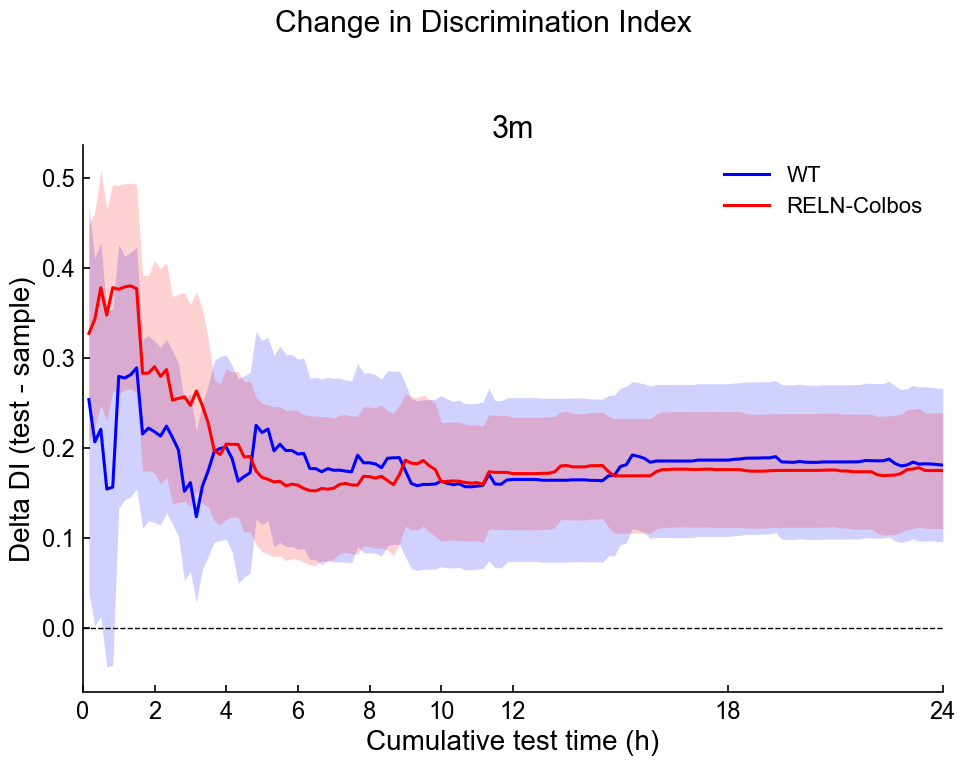

In [205]:

# Plot the full 24-hour Delta DI curve and run a mixed-effects model.

summary = (
    delta_di_24h.groupby(["Age", "Genotype", "time_h"], as_index=False)
    .agg(
        mean_delta=("Delta_DI", "mean"),
        sem_delta=("Delta_DI", "sem"),
    )
)

fig, axes = plt.subplots(1, len(AGE_ORDER), figsize=(10, 7.5), sharey=True)
axes = np.atleast_1d(axes)


for ax, age in zip(axes, AGE_ORDER):
    for genotype in DELTA_GENOTYPES:
        sub = summary[
            summary["Age"].eq(age)
            & summary["Genotype"].eq(genotype)
        ].sort_values("time_h")

        x = sub["time_h"].to_numpy()
        y = sub["mean_delta"].to_numpy()
        sem = sub["sem_delta"].fillna(0).to_numpy()

        ax.plot(x, y, color=GENO_COLORS[genotype], linewidth=2.2, label=genotype)
        ax.fill_between(
            x, y - sem, y + sem,
            color=GENO_COLORS[genotype],
            alpha=0.18,
            linewidth=0,
        )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_xlim(0, 24)
    ax.set_xticks([0, 2, 4, 6, 8, 10, 12, 18, 24])
    ax.set_title(age)
    ax.set_xlabel("Cumulative test time (h)")
    ax.set_ylabel("Delta DI (test - sample)" if age == AGE_ORDER[0] else "")
    format_axes(ax)
    ax.legend(frameon=False)

fig.suptitle("Change in Discrimination Index", y=1.03)
plt.tight_layout()
if SAVE_AIMI_OUTPUTS:
    save_figure_pdf()
plt.show()




# Whole Sample versus cumulative Test at 30, 45 and 60 minutes

This section performs the clarified analysis for **both total object exploration and
discrimination index (DI)**.

For every mouse, the Sample value is calculated once using the **whole Sample phase**.
That same Sample value is then compared separately with cumulative Test values at:

- 0–30 minutes
- 0–45 minutes
- 0–60 minutes

The analyses include:

1. WT versus RELN-Colbos comparisons within Sample and Test.
2. Paired whole-Sample versus Test comparisons within each genotype.
3. Separate statistics for 30, 45 and 60 minute Test endpoints.
4. Paired figures, CSV tables and PDF export.

For Sample DI, the side that later becomes novel is used. The Sample DI therefore
represents pre-existing side preference, whereas Test DI represents novel-object
discrimination.


In [206]:
# ==========================================================
# WHOLE SAMPLE VERSUS CUMULATIVE TEST
# FOR TOTAL EXPLORATION AND DI
# AT 30, 45 AND 60 MINUTES
# ==========================================================

EARLY_TIMEPOINTS_MIN = [30, 45, 60]
EARLY_TIME_LABELS = ["30 min", "45 min", "60 min"]
EARLY_GENOTYPES = ["WT", "RELN-Colbos"]
SAMPLE_TEST_PHASES = ["sample", "test"]
DI_PHASES = SAMPLE_TEST_PHASES
TOTAL_PHASES = SAMPLE_TEST_PHASES


def build_loukia_whole_sample_vs_test_tables(data):
    """
    Return mouse-level whole-Sample and cumulative-Test values.

    The whole Sample phase is summarised once per mouse and then repeated
    beside each Test endpoint so that the following paired comparisons can
    be made independently:

        whole Sample vs Test 0-30 min
        whole Sample vs Test 0-45 min
        whole Sample vs Test 0-60 min

    Both total object exploration and DI are calculated from the same
    mouse-level summaries.
    """

    required = {
        "MouseSessionID", "KageID", "Cohort", "Age", "Genotype",
        "Phase", "NOR_side", "time_min", "left_sec", "right_sec",
    }
    missing = required - set(data.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    work = data.copy()
    work["Phase"] = work["Phase"].astype(str).str.strip().str.lower()

    for column in ["time_min", "left_sec", "right_sec"]:
        work[column] = pd.to_numeric(work[column], errors="coerce")

    work["left_sec"] = work["left_sec"].fillna(0)
    work["right_sec"] = work["right_sec"].fillna(0)

    work = work[
        work["time_min"].notna()
        & work["time_min"].ge(0)
        & work["Genotype"].isin(EARLY_GENOTYPES)
        & work["Phase"].isin(SAMPLE_TEST_PHASES)
    ].copy()

    # Use the side that becomes novel during Test for both phases.
    future_novel_side = (
        work["NOR_side"].astype(str).str.strip().str.upper().str[0]
    )
    work["novel_sec"] = np.where(
        future_novel_side.eq("L"), work["left_sec"], work["right_sec"]
    )
    work["familiar_sec"] = np.where(
        future_novel_side.eq("L"), work["right_sec"], work["left_sec"]
    )

    id_columns = [
        "MouseSessionID", "KageID", "Cohort", "Age", "Genotype", "Phase"
    ]

    def summarise_mouse_phase(phase_data):
        summary = (
            phase_data
            .groupby(id_columns, as_index=False, observed=True)
            .agg(
                left_sec=("left_sec", "sum"),
                right_sec=("right_sec", "sum"),
                novel_sec=("novel_sec", "sum"),
                familiar_sec=("familiar_sec", "sum"),
            )
        )

        summary["Total_exploration_sec"] = (
            summary["left_sec"] + summary["right_sec"]
        )
        denominator = summary["novel_sec"] + summary["familiar_sec"]
        summary["DI"] = np.where(
            denominator > 0,
            (summary["novel_sec"] - summary["familiar_sec"]) / denominator,
            np.nan,
        )
        return summary

    # Whole Sample: no 30/45/60-minute truncation.
    whole_sample = summarise_mouse_phase(
        work[work["Phase"].eq("sample")].copy()
    )

    output_parts = []

    for cutoff_min in EARLY_TIMEPOINTS_MIN:
        # Repeat the same whole-Sample value for each independent comparison.
        sample_for_endpoint = whole_sample.copy()
        sample_for_endpoint["time_min"] = cutoff_min
        sample_for_endpoint["time_label"] = f"{cutoff_min} min"

        # Test values are cumulative from time zero to the requested endpoint.
        test_for_endpoint = summarise_mouse_phase(
            work[
                work["Phase"].eq("test")
                & work["time_min"].between(0, cutoff_min, inclusive="both")
            ].copy()
        )
        test_for_endpoint["time_min"] = cutoff_min
        test_for_endpoint["time_label"] = f"{cutoff_min} min"

        output_parts.extend([sample_for_endpoint, test_for_endpoint])

    metrics = pd.concat(output_parts, ignore_index=True)
    metrics["time_label"] = pd.Categorical(
        metrics["time_label"],
        categories=EARLY_TIME_LABELS,
        ordered=True,
    )
    metrics["Phase"] = pd.Categorical(
        metrics["Phase"],
        categories=SAMPLE_TEST_PHASES,
        ordered=True,
    )

    return metrics


sample_test_metrics_30_45_60 = (
    build_loukia_whole_sample_vs_test_tables(main_binned)
)

# Keep the familiar variable names used later in the notebook.
total_exploration_30_45_60 = sample_test_metrics_30_45_60.copy()
sample_test_DI_30_45_60 = sample_test_metrics_30_45_60.copy()

print("Phases included:")
print(sample_test_metrics_30_45_60["Phase"].dropna().unique())

# Confirm that each mouse has exactly one whole-Sample value repeated at
# all three endpoints.
sample_consistency_qc = (
    sample_test_metrics_30_45_60[
        sample_test_metrics_30_45_60["Phase"].eq("sample")
    ]
    .groupby("MouseSessionID", observed=True)
    .agg(
        n_sample_total_values=("Total_exploration_sec", "nunique"),
        n_sample_DI_values=("DI", "nunique"),
    )
    .reset_index()
)

if (
    sample_consistency_qc["n_sample_total_values"].gt(1).any()
    or sample_consistency_qc["n_sample_DI_values"].gt(1).any()
):
    raise ValueError(
        "Whole-Sample values changed across endpoints. Check phase filtering."
    )

loukia_sample_sizes = (
    sample_test_metrics_30_45_60
    .groupby(
        ["Phase", "Age", "Genotype", "time_label"],
        observed=True,
        as_index=False,
    )
    .agg(n_mice=("MouseSessionID", "nunique"))
)

display(sample_test_metrics_30_45_60.head())
display(loukia_sample_sizes)


Phases included:
['sample', 'test']
Categories (2, object): ['sample' < 'test']


,MouseSessionID,KageID,Cohort,Age,Genotype,Phase,left_sec,right_sec,novel_sec,familiar_sec,Total_exploration_sec,DI,time_min,time_label
0,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage1,Kage1,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,sample,219.5,493.0,219.5,493.0,712.5,-0.383860,30,30 min
1,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage3,Kage3,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,sample,369.5,517.0,369.5,517.0,886.5,-0.166385,30,30 min
2,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage4,Kage4,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,sample,514.0,320.5,320.5,514.0,834.5,-0.231875,30,30 min
3,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage5,Kage5,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,WT,sample,396.0,410.5,396.0,410.5,806.5,-0.017979,30,30 min
4,2025-11-Nov-Dec_RELN-COLBOS_Coh1_Kage8,Kage8,2025-11-Nov-Dec_RELN-COLBOS_Coh1,3m,RELN-Colbos,sample,612.0,456.0,612.0,456.0,1068.0,0.146067,30,30 min


,Phase,Age,Genotype,time_label,n_mice
0,sample,3m,RELN-Colbos,30 min,9
1,sample,3m,RELN-Colbos,45 min,9
2,sample,3m,RELN-Colbos,60 min,9
3,sample,3m,WT,30 min,11
4,sample,3m,WT,45 min,11
5,sample,3m,WT,60 min,11
6,test,3m,RELN-Colbos,30 min,9
7,test,3m,RELN-Colbos,45 min,9
8,test,3m,RELN-Colbos,60 min,9
9,test,3m,WT,30 min,11


In [207]:
# ==========================================================
# STATISTICS
# ==========================================================

def compare_sample_test_paired_value(df, value_col, context=None):
    """Paired Sample-versus-Test analysis for a specified outcome."""
    context = {} if context is None else dict(context)

    paired = (
        df.pivot_table(
            index="MouseSessionID",
            columns="Phase",
            values=value_col,
            aggfunc="first",
        )
        .dropna(subset=SAMPLE_TEST_PHASES)
    )

    difference = paired["test"] - paired["sample"]
    diff_norm = shapiro_result(difference)

    result = {
        **context,
        "comparison": "Whole Sample vs Test",
        "value_col": value_col,
        "n_pairs": len(paired),
        "sample_mean": paired["sample"].mean() if len(paired) else np.nan,
        "test_mean": paired["test"].mean() if len(paired) else np.nan,
        "mean_change_test_minus_sample": (
            difference.mean() if len(difference) else np.nan
        ),
        "difference_shapiro_W": diff_norm["W"],
        "difference_shapiro_p": diff_norm["p"],
        "differences_normal": diff_norm["normal"],
        "test": "not enough paired data",
        "statistic": np.nan,
        "p_raw": np.nan,
    }

    if len(paired) < 2:
        return result

    if diff_norm["normal"]:
        statistic, p = ttest_rel(
            paired["test"], paired["sample"], nan_policy="omit"
        )
        result["test"] = "Paired t-test"
    else:
        try:
            statistic, p = wilcoxon(
                paired["test"],
                paired["sample"],
                alternative="two-sided",
                zero_method="wilcox",
            )
            result["test"] = "Wilcoxon signed-rank"
        except ValueError:
            statistic, p = np.nan, np.nan
            result["test"] = "Wilcoxon unavailable"

    result["statistic"] = statistic
    result["p_raw"] = p
    return result


# ----------------------------------------------------------
# A. WT versus NLGF within each phase, age and endpoint
# ----------------------------------------------------------

def build_genotype_statistics(data, value_col, analysis_name):
    rows = []

    for phase in SAMPLE_TEST_PHASES:
        for age in AGE_ORDER:
            for cutoff_min in EARLY_TIMEPOINTS_MIN:
                subset = data[
                    data["Phase"].eq(phase)
                    & data["Age"].eq(age)
                    & data["time_min"].eq(cutoff_min)
                ].copy()

                rows.append(
                    compare_wt_nlgf(
                        subset,
                        value_col=value_col,
                        context={
                            "analysis": analysis_name,
                            "Phase": phase,
                            "Age": age,
                            "time_min": cutoff_min,
                            "time_label": f"{cutoff_min} min",
                        },
                    )
                )

    results = pd.DataFrame(rows)

    # Separate multiple-testing families by phase.
    corrected = [
        add_holm_and_stars(family)
        for _, family in results.groupby("Phase", sort=False)
    ]
    return pd.concat(corrected, ignore_index=True)


total_exploration_stats = build_genotype_statistics(
    total_exploration_30_45_60,
    value_col="Total_exploration_sec",
    analysis_name="Total exploration WT vs NLGF",
)

di_genotype_stats = build_genotype_statistics(
    sample_test_DI_30_45_60,
    value_col="DI",
    analysis_name="DI WT vs NLGF",
)


# ----------------------------------------------------------
# B. Paired whole Sample versus Test
# separately for each outcome, age, genotype and endpoint
# ----------------------------------------------------------

def build_paired_statistics(data, value_col, analysis_name):
    rows = []

    for age in AGE_ORDER:
        for genotype in EARLY_GENOTYPES:
            for cutoff_min in EARLY_TIMEPOINTS_MIN:
                subset = data[
                    data["Age"].eq(age)
                    & data["Genotype"].eq(genotype)
                    & data["time_min"].eq(cutoff_min)
                ].copy()

                rows.append(
                    compare_sample_test_paired_value(
                        subset,
                        value_col=value_col,
                        context={
                            "analysis": analysis_name,
                            "Age": age,
                            "Genotype": genotype,
                            "time_min": cutoff_min,
                            "time_label": f"{cutoff_min} min",
                        },
                    )
                )

    results = pd.DataFrame(rows)

    # Correct the 30/45/60-minute tests separately within each
    # age-by-genotype family.
    corrected = [
        add_holm_and_stars(family)
        for _, family in results.groupby(
            ["Age", "Genotype"], sort=False, observed=True
        )
    ]
    return pd.concat(corrected, ignore_index=True)


total_exploration_sample_test_stats = build_paired_statistics(
    total_exploration_30_45_60,
    value_col="Total_exploration_sec",
    analysis_name="Paired whole Sample vs Test total exploration",
)

di_sample_test_stats = build_paired_statistics(
    sample_test_DI_30_45_60,
    value_col="DI",
    analysis_name="Paired whole Sample vs Test DI",
)


print("WT versus NLGF: total exploration")
display(total_exploration_stats)

print("Paired whole Sample versus Test: total exploration")
display(total_exploration_sample_test_stats)

print("WT versus NLGF: DI")
display(di_genotype_stats)

print("Paired whole Sample versus Test: DI")
display(di_sample_test_stats)


NameError: name 'compare_wt_nlgf' is not defined

/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:

Saved PDF: 135_Total_object_exploration_whole_Sample_versus_Test_030_min.pdf


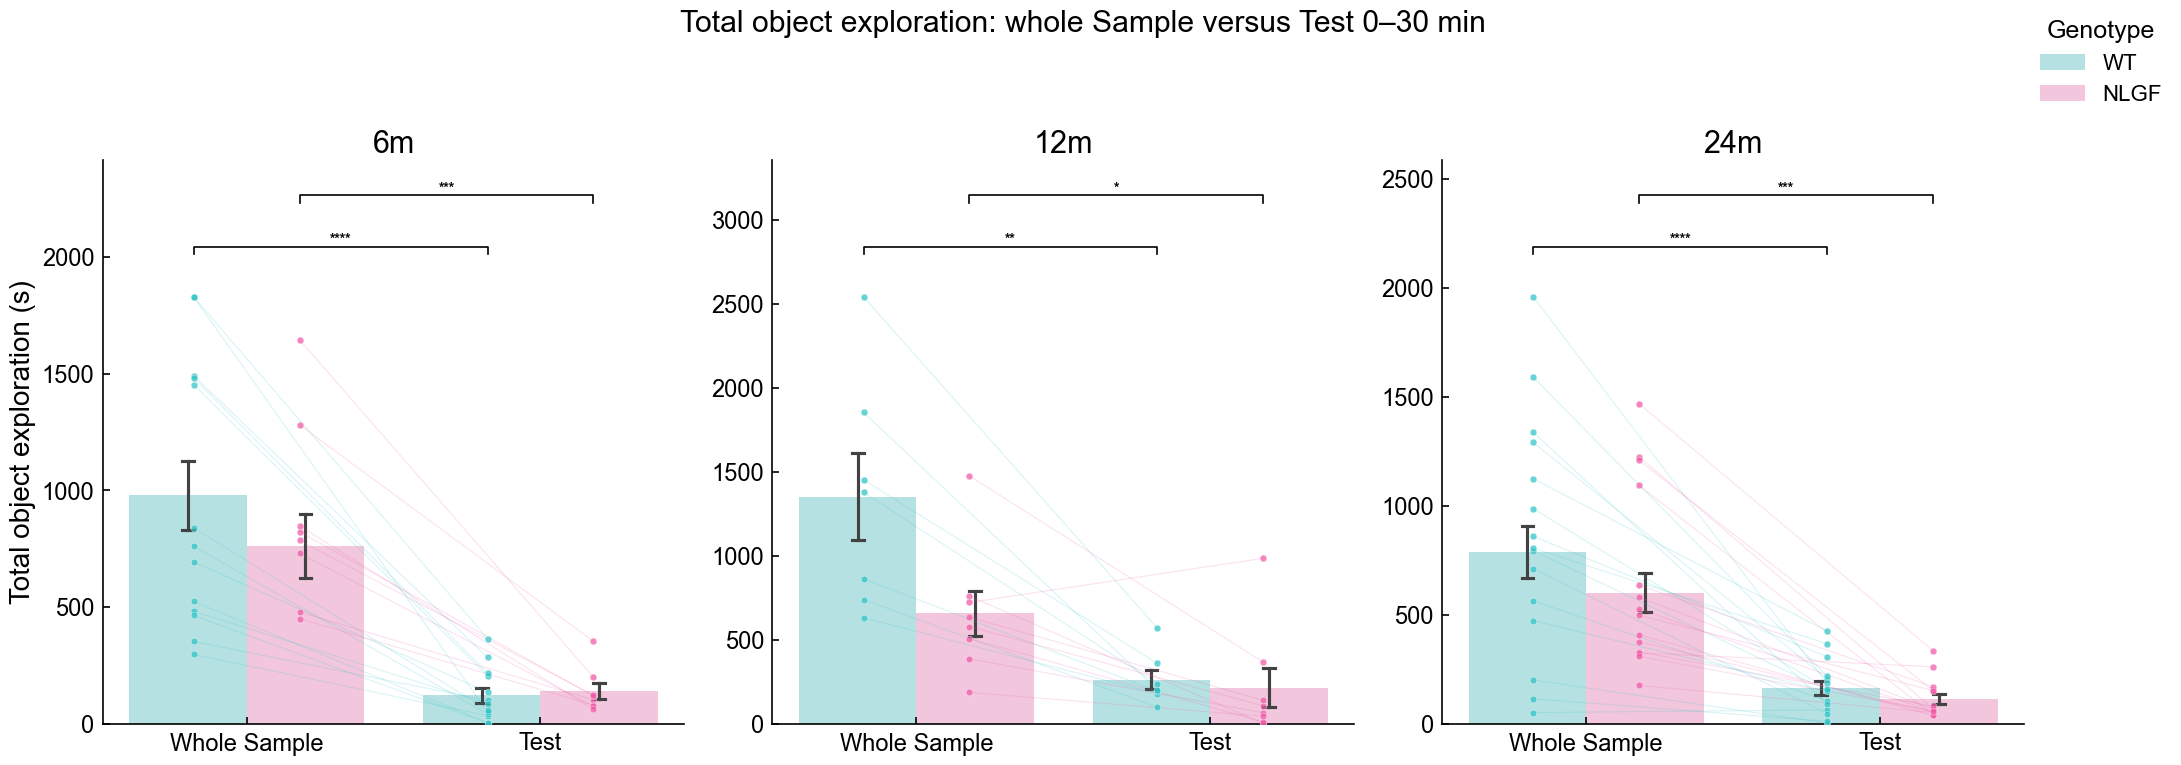

/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:

Saved PDF: 136_Total_object_exploration_whole_Sample_versus_Test_045_min.pdf


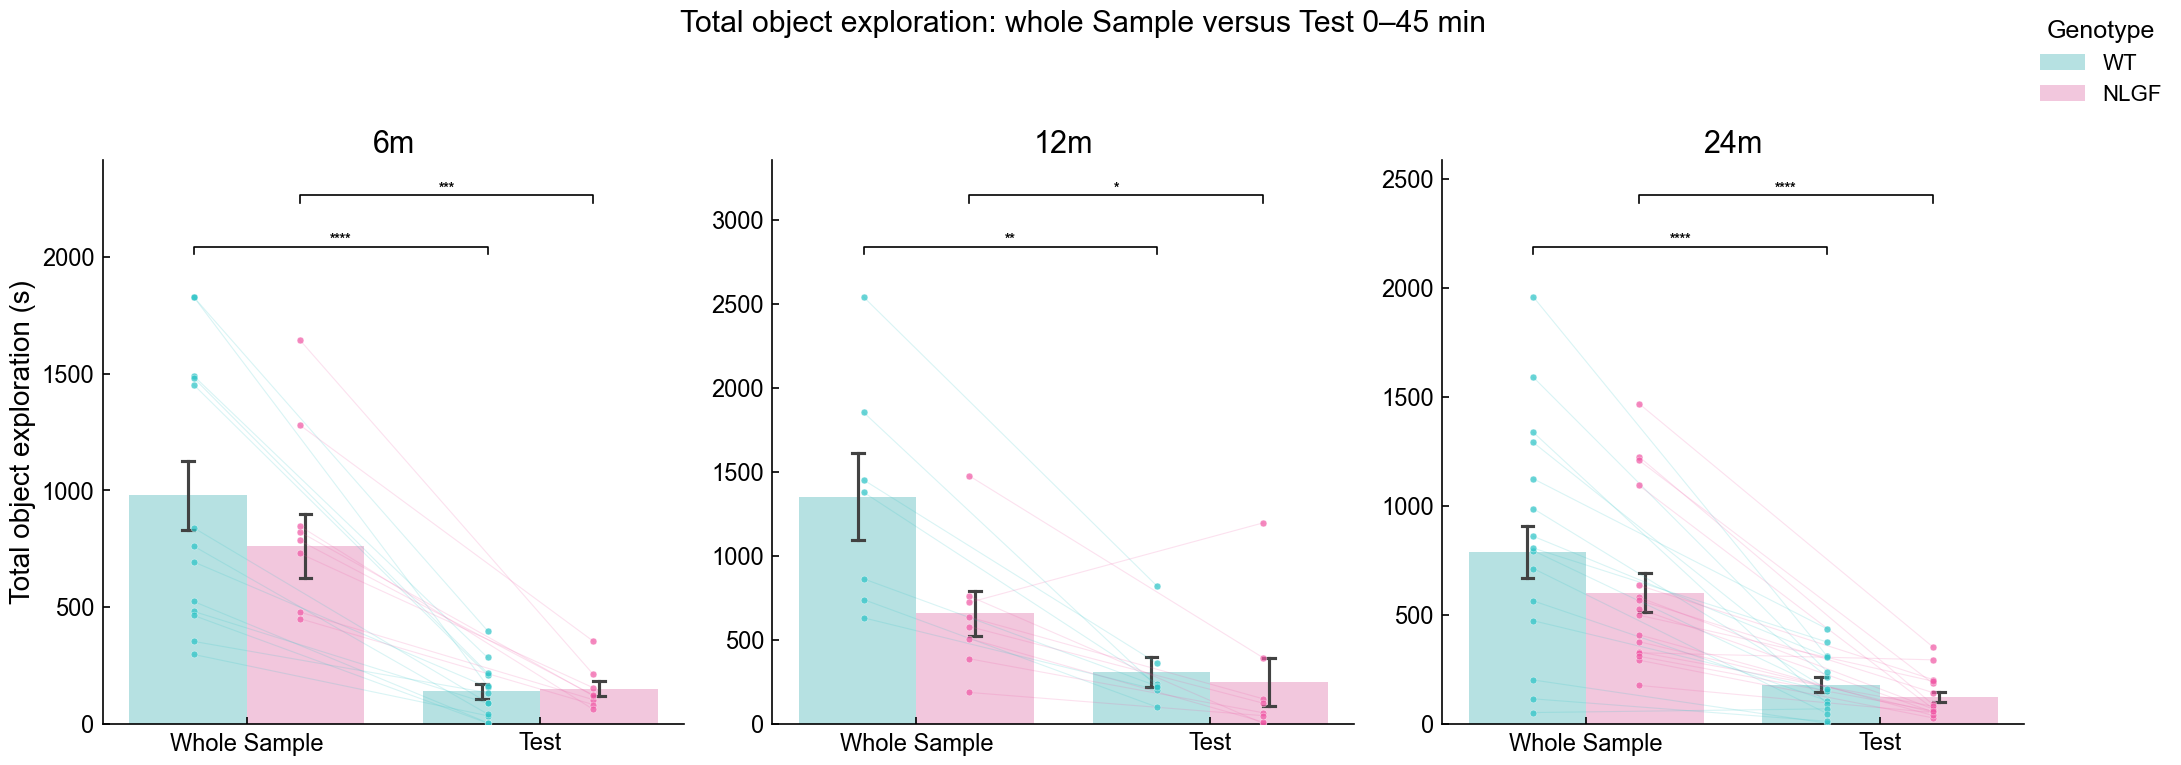

/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:

Saved PDF: 137_Total_object_exploration_whole_Sample_versus_Test_060_min.pdf


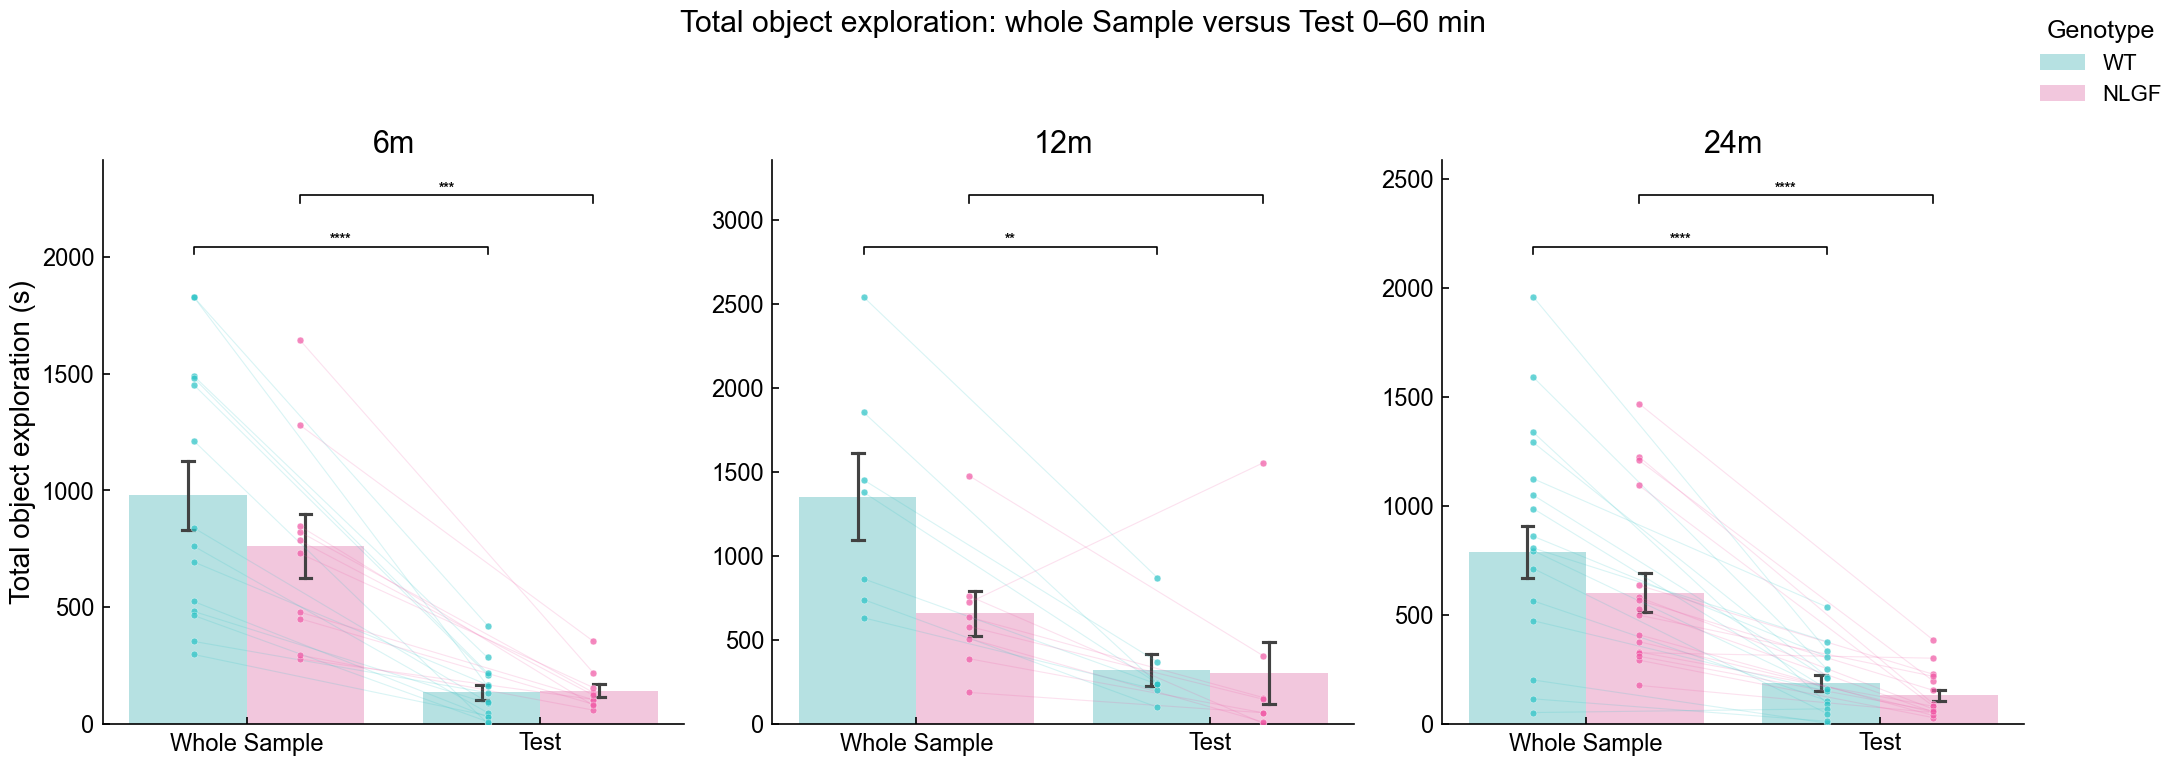

/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:

Saved PDF: 138_Discrimination_index_whole_Sample_versus_Test_030_min.pdf


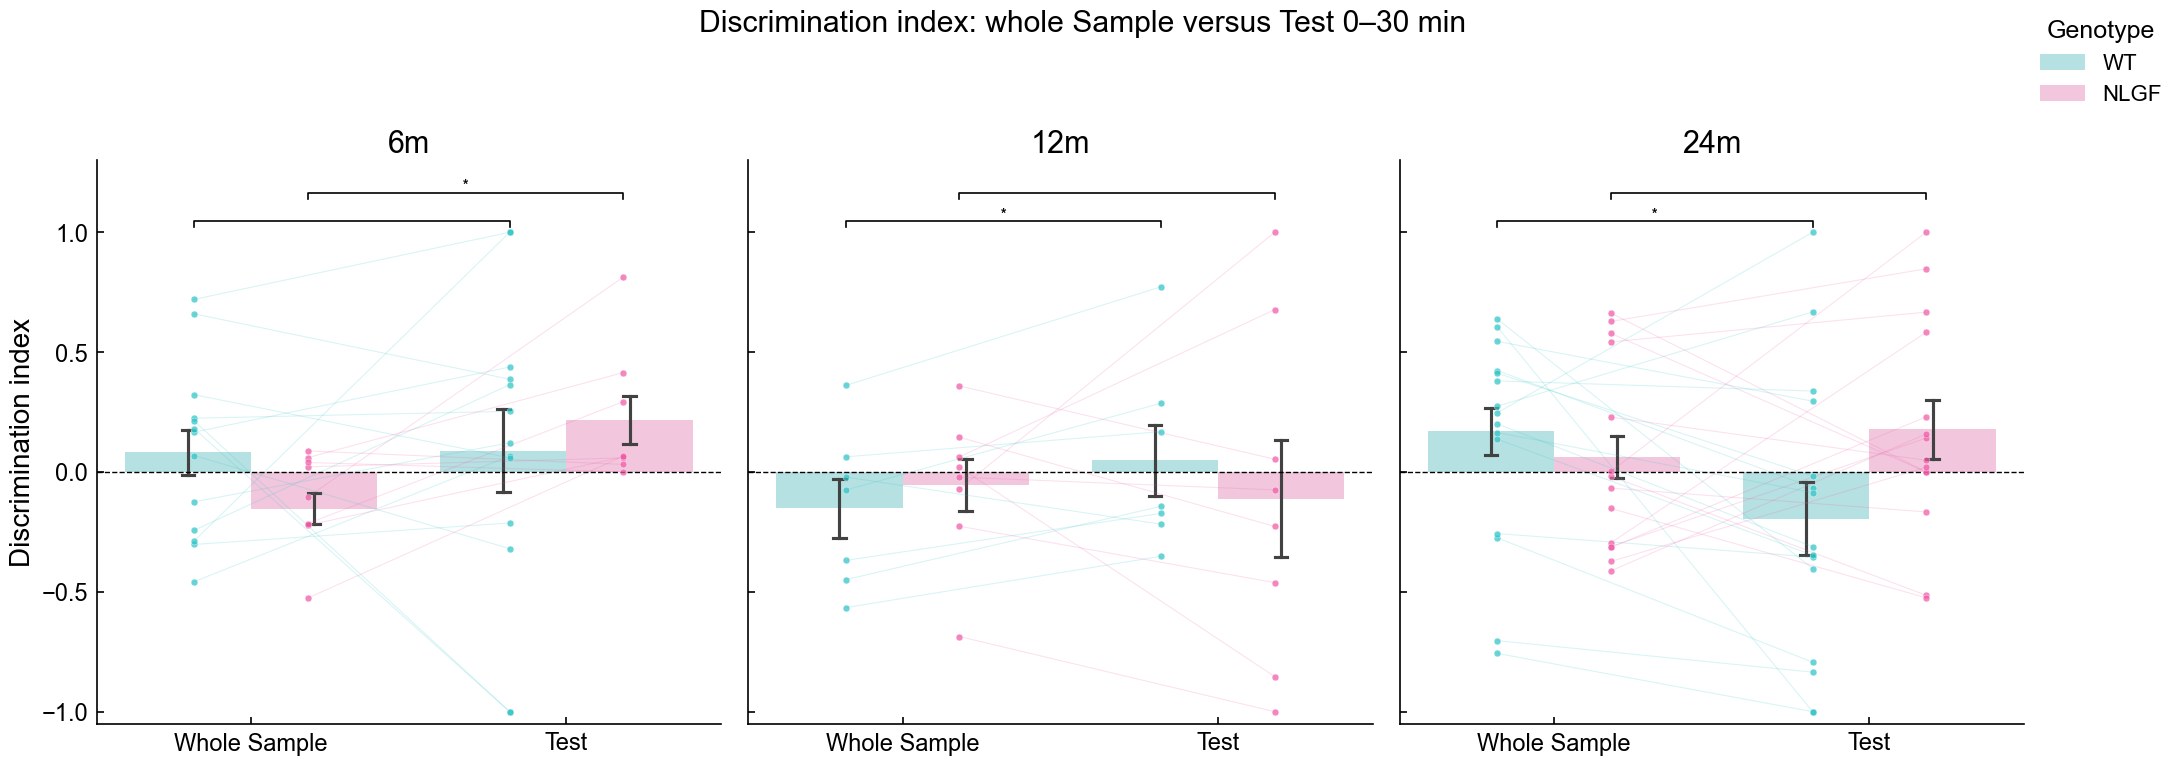

/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:

Saved PDF: 139_Discrimination_index_whole_Sample_versus_Test_045_min.pdf


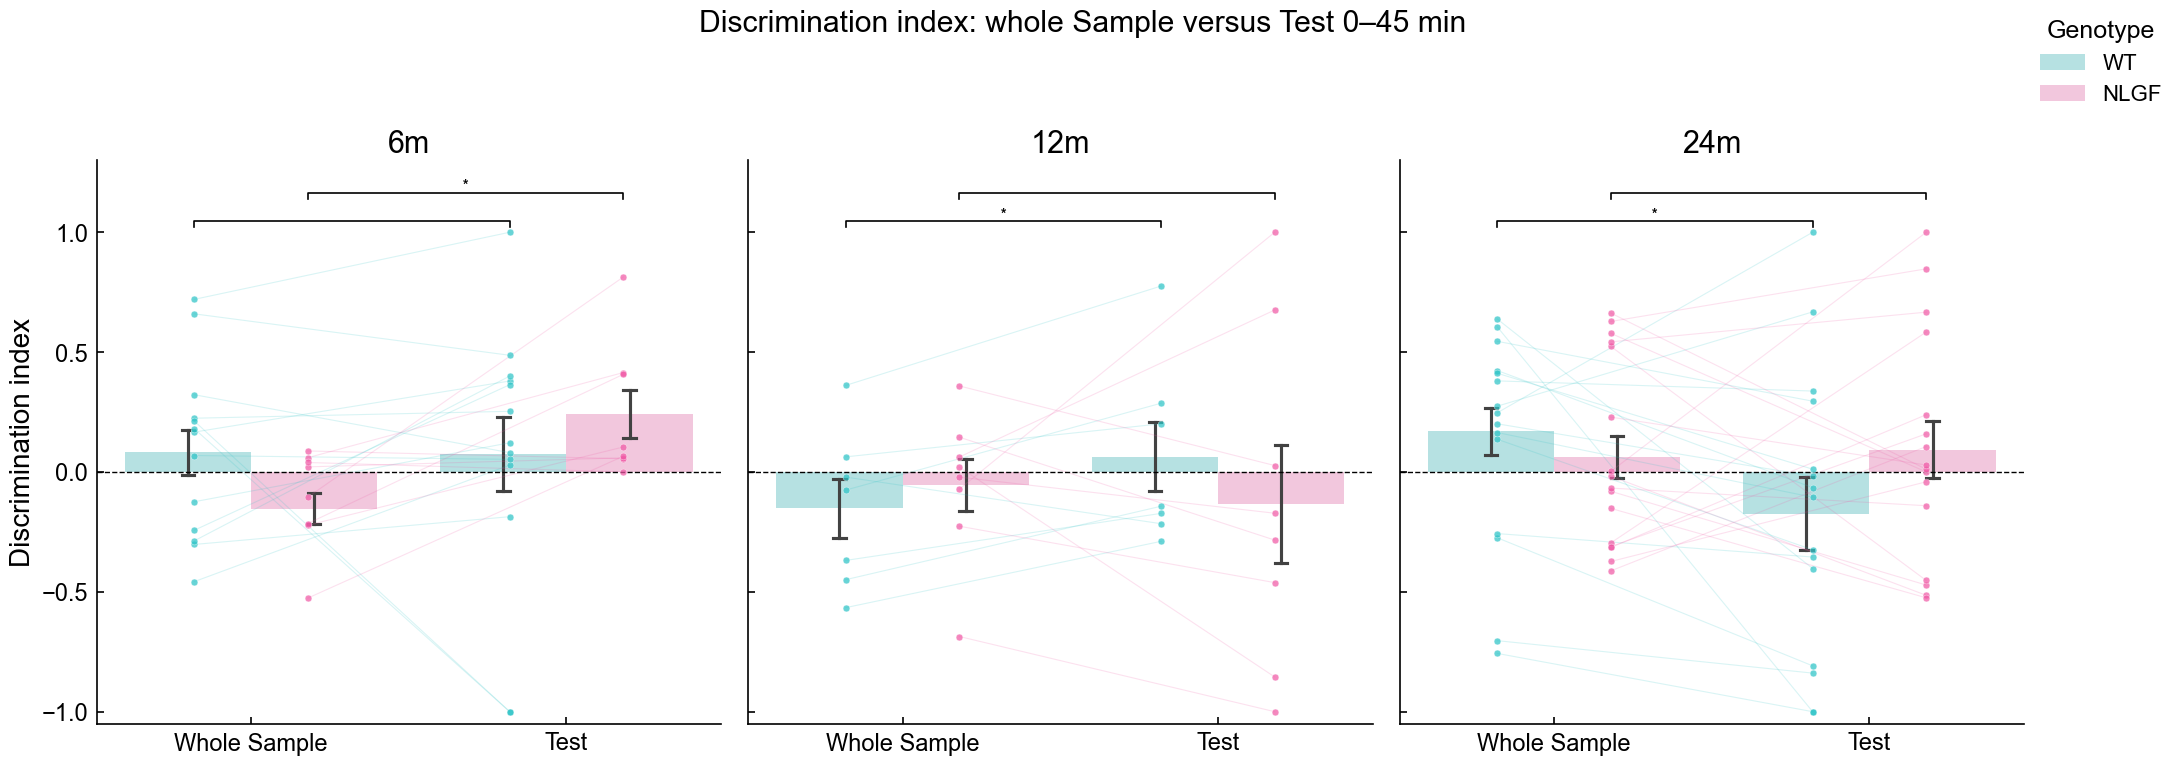

/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:81: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(
/var/folders/g8/st_0_lj16j97jxz803bqsb8c0000gn/T/ipykernel_72251/4092563772.py:

Saved PDF: 140_Discrimination_index_whole_Sample_versus_Test_060_min.pdf


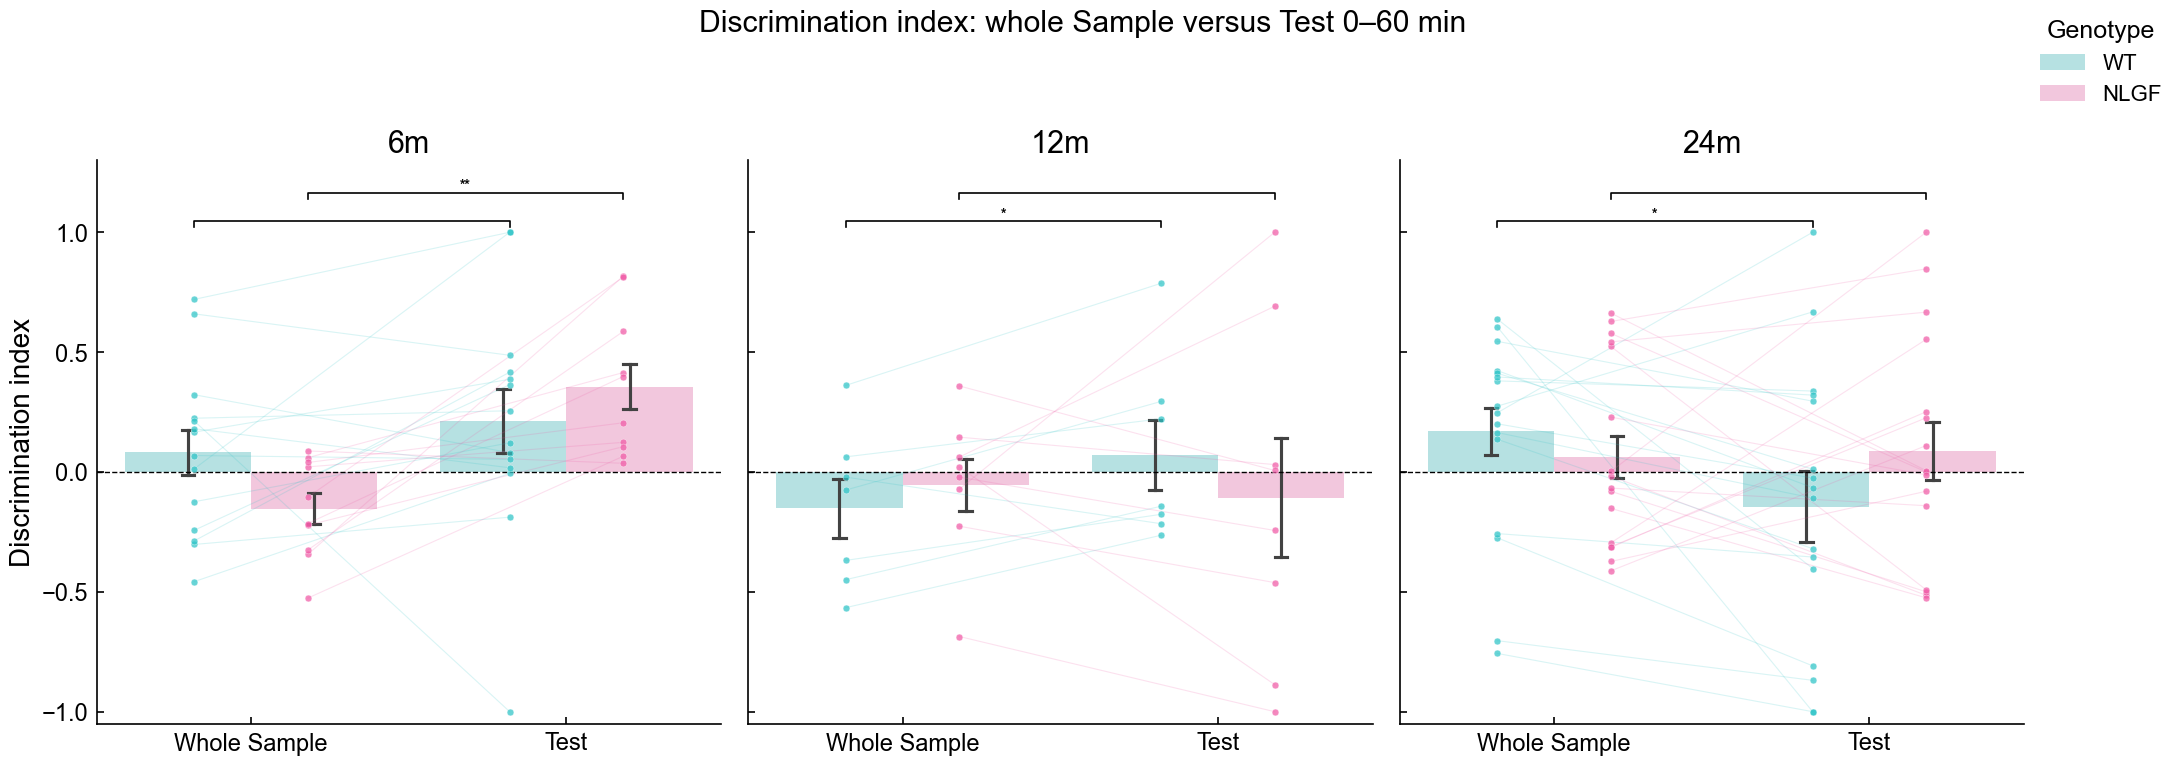

In [ ]:
# ==========================================================
# REORGANISED FIGURES BY TEST ENDPOINT
#
# One figure per endpoint:
#   Whole Sample vs 30 min Test: 6m, 12m, 24m
#   Whole Sample vs 45 min Test: 6m, 12m, 24m
#   Whole Sample vs 60 min Test: 6m, 12m, 24m
#
# Separate figure sets are produced for:
#   1. Total object exploration
#   2. Discrimination index
# ==========================================================

PHASE_X = {"sample": 0, "test": 1}
GENOTYPE_OFFSET = {"WT": -0.18, "NLGF": 0.18}


def plot_endpoint_across_ages(
    data,
    stats_df,
    value_col,
    ylabel,
    figure_title,
    output_prefix,
    di_plot=False,
):
    """
    Produce one figure for each Test endpoint.

    Each figure contains three panels:
        6m, 12m and 24m

    Within each age panel:
        whole Sample vs cumulative Test
        WT and NLGF shown separately
        paired mouse values connected
    """

    for cutoff_min in EARLY_TIMEPOINTS_MIN:

        fig, axes = plt.subplots(
            1,
            len(AGE_ORDER),
            figsize=(22, 7.5),
            sharey=di_plot,
        )
        axes = np.atleast_1d(axes)

        for ax, age in zip(axes, AGE_ORDER):

            panel_df = data[
                data["Age"].eq(age)
                & data["time_min"].eq(cutoff_min)
            ].copy()

            sns.barplot(
                data=panel_df,
                x="Phase",
                y=value_col,
                hue="Genotype",
                order=SAMPLE_TEST_PHASES,
                hue_order=EARLY_GENOTYPES,
                palette=GENO_COLORS,
                errorbar="se",
                capsize=0.08,
                alpha=0.38,
                ax=ax,
            )

            # ----------------------------------------------
            # Mouse-level paired lines and points
            # ----------------------------------------------
            for genotype in EARLY_GENOTYPES:

                genotype_df = panel_df[
                    panel_df["Genotype"].eq(genotype)
                ].copy()

                paired = (
                    genotype_df
                    .pivot_table(
                        index="MouseSessionID",
                        columns="Phase",
                        values=value_col,
                        aggfunc="first",
                    )
                    .dropna(subset=SAMPLE_TEST_PHASES)
                )

                x_sample = (
                    PHASE_X["sample"]
                    + GENOTYPE_OFFSET[genotype]
                )
                x_test = (
                    PHASE_X["test"]
                    + GENOTYPE_OFFSET[genotype]
                )

                for _, row in paired.iterrows():

                    ax.plot(
                        [x_sample, x_test],
                        [row["sample"], row["test"]],
                        color=GENO_COLORS[genotype],
                        alpha=0.18,
                        linewidth=0.8,
                        zorder=2,
                    )

                    ax.scatter(
                        [x_sample, x_test],
                        [row["sample"], row["test"]],
                        color=GENO_COLORS[genotype],
                        edgecolor="white",
                        linewidth=0.35,
                        s=24,
                        alpha=0.72,
                        zorder=3,
                    )

            # ----------------------------------------------
            # Statistical brackets
            # ----------------------------------------------
            if di_plot:
                bracket_levels = {
                    "WT": 1.02,
                    "NLGF": 1.14,
                }
                bracket_height = 0.025

            else:
                panel_max = finite_max(
                    panel_df[value_col],
                    default=1,
                )
                bracket_step = max(panel_max * 0.10, 1)

                bracket_levels = {
                    "WT": panel_max + bracket_step,
                    "NLGF": panel_max + bracket_step * 2.2,
                }
                bracket_height = bracket_step * 0.18

            for genotype in EARLY_GENOTYPES:

                stat_row = stats_df[
                    stats_df["Age"].eq(age)
                    & stats_df["Genotype"].eq(genotype)
                    & stats_df["time_min"].eq(cutoff_min)
                ]

                if stat_row.empty:
                    continue

                add_bracket(
                    ax,
                    PHASE_X["sample"]
                    + GENOTYPE_OFFSET[genotype],
                    PHASE_X["test"]
                    + GENOTYPE_OFFSET[genotype],
                    bracket_levels[genotype],
                    stat_row.iloc[0]["stars"],
                    height=bracket_height,
                    fontsize=10,
                )

            # ----------------------------------------------
            # Axis formatting
            # ----------------------------------------------
            ax.set_title(age)
            ax.set_xlabel("")
            ax.set_xticks([0, 1])
            ax.set_xticklabels(
                ["Whole Sample", "Test"]
            )

            ax.set_ylabel(
                ylabel if age == AGE_ORDER[0] else ""
            )

            if di_plot:
                ax.axhline(
                    0,
                    color="black",
                    linestyle="--",
                    linewidth=1,
                )
                ax.set_ylim(-1.05, 1.30)

            else:
                panel_max = finite_max(
                    panel_df[value_col],
                    default=1,
                )
                bracket_step = max(panel_max * 0.10, 1)

                ax.set_ylim(
                    bottom=0,
                    top=max(
                        ax.get_ylim()[1],
                        panel_max + bracket_step * 3.2,
                    ),
                )

            format_axes(ax)

            if ax.get_legend() is not None:
                ax.get_legend().remove()

        # ----------------------------------------------
        # Shared legend and title
        # ----------------------------------------------
        handles, labels = axes[-1].get_legend_handles_labels()

        fig.legend(
            handles[:2],
            labels[:2],
            title="Genotype",
            frameon=False,
            loc="upper right",
        )

        fig.suptitle(
            (
                f"{figure_title}: whole Sample versus "
                f"Test 0–{cutoff_min} min"
            ),
            y=1.03,
        )

        plt.tight_layout(
            rect=[0, 0, 0.94, 0.98]
        )

        # Save using your existing PDF helper.
        if SAVE_AIMI_OUTPUTS:
            save_figure_pdf()

            # Optional separate named PDF.
            if "LOUKIA_OUTPUT_DIR" in globals():
                fig.savefig(
                    LOUKIA_OUTPUT_DIR
                    / (
                        f"{output_prefix}_whole_sample_vs_"
                        f"test_{cutoff_min}min_across_ages.pdf"
                    ),
                    format="pdf",
                    bbox_inches="tight",
                )

        plt.show()


# ==========================================================
# 1. TOTAL OBJECT EXPLORATION
# ==========================================================

plot_endpoint_across_ages(
    data=total_exploration_30_45_60,
    stats_df=total_exploration_sample_test_stats,
    value_col="Total_exploration_sec",
    ylabel="Total object exploration (s)",
    figure_title="Total object exploration",
    output_prefix="total_object_exploration",
    di_plot=False,
)


# ==========================================================
# 2. DISCRIMINATION INDEX
# ==========================================================

plot_endpoint_across_ages(
    data=sample_test_DI_30_45_60,
    stats_df=di_sample_test_stats,
    value_col="DI",
    ylabel="Discrimination index",
    figure_title="Discrimination index",
    output_prefix="discrimination_index",
    di_plot=True,
)

In [ ]:

# ==========================================================
# FINALISE THE COMBINED MULTIPAGE PDF
# ==========================================================

if SAVE_AIMI_OUTPUTS:
    with PdfPages(ALL_FIGURES_PDF_PATH) as pdf:
        for fig in _FIGURES_BY_NAME.values():
            pdf.savefig(fig, bbox_inches="tight")

    print(f"Combined PDF saved:\n{ALL_FIGURES_PDF_PATH}")
    print(f"Total figures saved: {len(_FIGURES_BY_NAME)}")

else:
    print("Combined PDF not saved (SAVE_AIMI_OUTPUTS = False)")

Combined PDF saved successfully:
/Volumes/Aimi_SmrtKg/NOR_MASTER/SmartKage_NOR_all_figures.pdf
Total figures saved: 140


# FINAL statistical analysis 
This section supersedes earlier exploratory statistics. It performs normality checks, chooses parametric/non-parametric tests as appropriate, and reports **raw p-values only**.


In [ ]:
# ==========================================================
# STATISTICS HELPERS 
# ==========================================================
# IMPORTANT:
# - Independent WT vs NLGF comparisons: Shapiro-Wilk per group ->
#   Welch two-tailed t-test if both groups pass, otherwise Mann-Whitney U.
# - Paired comparisons: Shapiro-Wilk on paired differences ->
#   paired t-test if normal, otherwise Wilcoxon signed-rank.
# - Age x Genotype for one-value-per-mouse outcomes: ordinary two-way ANOVA
#   using a Type III ANOVA table.
# - Repeated observations within the same mouse (period/ITI/phase/side/time):
#   mixed-effects repeated-measures model with mouse as a random intercept.

import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
from scipy.stats import shapiro, ttest_ind, mannwhitneyu, ttest_rel, wilcoxon, fisher_exact
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

ALPHA_FINAL = 0.05


def _final_clean(x):
    return pd.to_numeric(pd.Series(x), errors='coerce').dropna().to_numpy(dtype=float)


def _final_shapiro(x):
    x = _final_clean(x)
    if len(x) < 3:
        return {'n': len(x), 'W': np.nan, 'p_value': np.nan, 'normal': np.nan,
                'note': 'Shapiro-Wilk requires at least 3 observations'}
    try:
        W, p = shapiro(x)
        return {'n': len(x), 'W': float(W), 'p_value': float(p),
                'normal': bool(p > ALPHA_FINAL), 'note': ''}
    except Exception as exc:
        return {'n': len(x), 'W': np.nan, 'p_value': np.nan, 'normal': np.nan,
                'note': str(exc)}


def _final_sig(p):
    if pd.isna(p): return 'NA'
    if p < 0.0001: return '****'
    if p < 0.001: return '***'
    if p < 0.01: return '**'
    if p < 0.05: return '*'
    return 'ns'


def final_independent_test(df, value_col, group_col='Genotype', g1='WT', g2='NLGF', context=None):
    context = {} if context is None else dict(context)
    x = _final_clean(df.loc[df[group_col].eq(g1), value_col])
    y = _final_clean(df.loc[df[group_col].eq(g2), value_col])
    nx = _final_shapiro(x); ny = _final_shapiro(y)
    row = {**context, 'value_col': value_col, 'group_1': g1, 'group_2': g2,
           'n_1': len(x), 'n_2': len(y),
           'mean_1': np.mean(x) if len(x) else np.nan,
           'mean_2': np.mean(y) if len(y) else np.nan,
           'median_1': np.median(x) if len(x) else np.nan,
           'median_2': np.median(y) if len(y) else np.nan,
           'shapiro_1_W': nx['W'], 'shapiro_1_p': nx['p_value'],
           'shapiro_2_W': ny['W'], 'shapiro_2_p': ny['p_value'],
           'test': 'not tested', 'statistic': np.nan, 'p_value': np.nan}
    if len(x) < 2 or len(y) < 2:
        row['note'] = 'Fewer than 2 observations in at least one group'
        row['stars'] = 'NA'; return row
    if nx['normal'] is True and ny['normal'] is True:
        stat, p = ttest_ind(x, y, equal_var=False, alternative='two-sided')
        test = 'Welch two-tailed unpaired t-test'
    else:
        stat, p = mannwhitneyu(x, y, alternative='two-sided')
        test = 'Mann-Whitney U'
    row.update(test=test, statistic=float(stat), p_value=float(p), stars=_final_sig(p), note='')
    return row


def final_paired_test(df, subject_col, condition_col, value_col, c1, c2, context=None):
    context = {} if context is None else dict(context)
    wide = (df[df[condition_col].isin([c1, c2])]
            .pivot_table(index=subject_col, columns=condition_col, values=value_col, aggfunc='mean'))
    if c1 not in wide.columns or c2 not in wide.columns:
        return {**context, 'value_col': value_col, 'condition_1': c1, 'condition_2': c2,
                'n_pairs': 0, 'test': 'not tested', 'statistic': np.nan,
                'p_value': np.nan, 'stars': 'NA', 'note': 'Required condition missing'}
    wide = wide.dropna(subset=[c1, c2])
    x = pd.to_numeric(wide[c1], errors='coerce').to_numpy(float)
    y = pd.to_numeric(wide[c2], errors='coerce').to_numpy(float)
    d = y - x
    nd = _final_shapiro(d)
    row = {**context, 'value_col': value_col, 'condition_1': c1, 'condition_2': c2,
           'n_pairs': len(wide), 'mean_1': np.mean(x) if len(x) else np.nan,
           'mean_2': np.mean(y) if len(y) else np.nan,
           'mean_change_2_minus_1': np.mean(d) if len(d) else np.nan,
           'difference_shapiro_W': nd['W'], 'difference_shapiro_p': nd['p_value'],
           'test': 'not tested', 'statistic': np.nan, 'p_value': np.nan}
    if len(wide) < 2:
        row['stars']='NA'; row['note']='Fewer than 2 complete pairs'; return row
    if nd['normal'] is True:
        stat, p = ttest_rel(y, x, alternative='two-sided')
        test = 'Paired two-tailed t-test'
    else:
        try:
            stat, p = wilcoxon(y, x, alternative='two-sided', zero_method='wilcox')
            test = 'Wilcoxon signed-rank'
        except ValueError:
            stat, p, test = np.nan, np.nan, 'Wilcoxon unavailable'
    row.update(test=test, statistic=float(stat) if np.isfinite(stat) else np.nan,
               p_value=float(p) if np.isfinite(p) else np.nan,
               stars=_final_sig(p), note='')
    return row


def final_normality_table(df, value_col, group_cols):
    rows=[]
    for keys, sub in df.groupby(group_cols, observed=True, dropna=False):
        if not isinstance(keys, tuple): keys=(keys,)
        r=_final_shapiro(sub[value_col])
        rows.append({**dict(zip(group_cols, keys)), 'value_col': value_col, **r})
    return pd.DataFrame(rows)


def final_two_way_anova(df, value_col, age_col='Age', genotype_col='Genotype', context=None):
    context = {} if context is None else dict(context)
    d=df[[value_col, age_col, genotype_col]].copy()
    d[value_col]=pd.to_numeric(d[value_col], errors='coerce')
    d=d.dropna()
    d=d[d[genotype_col].isin(['WT','NLGF'])]
    d=d[d[age_col].isin(['6m','12m','24m'])]
    if d.empty:
        return pd.DataFrame(), pd.DataFrame()
    formula = f"Q('{value_col}') ~ C(Q('{age_col}')) * C(Q('{genotype_col}'))"
    model = smf.ols(formula, data=d).fit()
    aov = anova_lm(model, typ=3).reset_index().rename(columns={'index':'Effect', 'PR(>F)':'p_value'})
    aov['stars']=aov['p_value'].apply(_final_sig)
    for k,v in context.items(): aov[k]=v
    resid = pd.DataFrame([{**context, 'value_col': value_col, 'analysis':'two-way ANOVA residuals', **_final_shapiro(model.resid)}])
    return aov, resid


def final_mixed_repeated(df, value_col, subject_col, repeated_col,
                         age_col='Age', genotype_col='Genotype', context=None):
    context = {} if context is None else dict(context)
    cols=[value_col, subject_col, repeated_col, age_col, genotype_col]
    d=df[cols].copy()
    d[value_col]=pd.to_numeric(d[value_col], errors='coerce')
    d=d.dropna()
    d=d[d[genotype_col].isin(['WT','NLGF'])]
    d=d[d[age_col].isin(['6m','12m','24m'])]
    if d.empty:
        return pd.DataFrame(), pd.DataFrame()
    formula=(f"Q('{value_col}') ~ C(Q('{age_col}')) * C(Q('{genotype_col}')) * C(Q('{repeated_col}'))")
    try:
        fit=smf.mixedlm(formula, d, groups=d[subject_col]).fit(reml=False, method='lbfgs', maxiter=1000, disp=False)
        ci=fit.conf_int()
        terms=[]
        for term,p in fit.pvalues.items():
            if term in ('Group Var','Intercept'): continue
            terms.append({**context, 'value_col':value_col, 'term':term,
                          'coefficient':fit.params.get(term,np.nan),
                          'SE':fit.bse.get(term,np.nan),
                          'CI_low':ci.loc[term,0] if term in ci.index else np.nan,
                          'CI_high':ci.loc[term,1] if term in ci.index else np.nan,
                          'p_value':p, 'stars':_final_sig(p),
                          'model':'Mixed-effects repeated-measures model (random intercept = mouse)'})
        residual=pd.DataFrame([{**context, 'value_col':value_col, 'analysis':'mixed-model residuals', **_final_shapiro(fit.resid)}])
        return pd.DataFrame(terms), residual
    except Exception as exc:
        return pd.DataFrame([{**context,'value_col':value_col,'term':'MODEL_FAILED','p_value':np.nan,'stars':'NA','note':str(exc)}]), pd.DataFrame()

# ==========================================================
# FINAL NOR STATISTICS — RAW P VALUES ONLY
# ==========================================================
FINAL_STATS_DIR = MASTER_OUTPUT / 'FINAL_unadjusted_statistics'
if SAVE_AIMI_OUTPUTS:
    FINAL_STATS_DIR.mkdir(exist_ok=True)

# 1) Total exploration: WT vs NLGF within each age and phase + repeated phase model.
normality=[]; pairwise=[]
if 'phase_total' in globals():
    d=phase_total[phase_total['Genotype'].isin(['WT','NLGF'])].copy()
    normality.append(final_normality_table(d,'total_sec',['Age','Genotype','Phase']).assign(Analysis='Total exploration'))
    for age in AGE_ORDER:
        for phase in PHASE_ORDER:
            pairwise.append(final_independent_test(d[d['Age'].eq(age)&d['Phase'].eq(phase)],'total_sec',
                context={'Analysis':'Total exploration','Age':age,'Phase':phase,'Comparison':'WT vs NLGF'}))
    total_rm,total_rm_resid=final_mixed_repeated(d,'total_sec','MouseSessionID','Phase',context={'Analysis':'Total exploration'})
else:
    total_rm,total_rm_resid=pd.DataFrame(),pd.DataFrame()

# 2) Whole-24 h sample vs test DI: paired t/Wilcoxon within genotype.
paired_rows=[]
if 'sample_test_di_24h' in globals():
    d24=sample_test_di_24h[sample_test_di_24h['Genotype'].isin(['WT','NLGF'])].copy()
    for age in AGE_ORDER:
        for genotype in ['WT','NLGF']:
            sub=d24[d24['Age'].eq(age)&d24['Genotype'].eq(genotype)]
            paired_rows.append(final_paired_test(sub,'MouseSessionID','Phase','DI','sample','test',
                context={'Analysis':'Whole 24h DI: Sample vs Test','Age':age,'Genotype':genotype}))
    di_phase_rm,di_phase_rm_resid=final_mixed_repeated(d24,'DI','MouseSessionID','Phase',context={'Analysis':'Whole 24h DI'})
else:
    di_phase_rm,di_phase_rm_resid=pd.DataFrame(),pd.DataFrame()

# 3) Whole-24 h test DI: age x genotype two-way ANOVA and age-specific WT vs NLGF.
di24_geno=[]; di24_norm=[]; di24_aov=pd.DataFrame(); di24_resid=pd.DataFrame()
if 'sample_test_di_24h' in globals():
    test24=sample_test_di_24h[(sample_test_di_24h['Phase'].eq('test')) & sample_test_di_24h['Genotype'].isin(['WT','NLGF'])].copy()
    di24_norm.append(final_normality_table(test24,'DI',['Age','Genotype']).assign(Analysis='Whole 24h test DI'))
    for age in AGE_ORDER:
        di24_geno.append(final_independent_test(test24[test24['Age'].eq(age)],'DI',
            context={'Analysis':'Whole 24h test DI','Age':age,'Comparison':'WT vs NLGF'}))
    di24_aov,di24_resid=final_two_way_anova(test24,'DI',context={'Analysis':'Whole 24h test DI'})

# 4) DI/Delta-DI over 2,4,6,8 h: repeated time model + age/time-specific WT vs NLGF.
time_pairwise=[]; time_norm=[]; time_models=[]; time_resids=[]
for analysis_name, source_name, value_col in [
    ('Test DI over time','di_timepoint_df','DI'),
    ('Delta DI over time','aimi_delta_di_over_time','Delta_DI')]:
    if source_name not in globals(): continue
    src=globals()[source_name].copy()
    tcol='timepoint_h'
    src['timepoint_numeric']=pd.to_numeric(src[tcol].astype(str),errors='coerce')
    src=src[src['timepoint_numeric'].isin([2,4,6,8]) & src['Genotype'].isin(['WT','NLGF'])]
    time_norm.append(final_normality_table(src,value_col,['Age','Genotype','timepoint_numeric']).assign(Analysis=analysis_name))
    for age in AGE_ORDER:
        for tp in [2,4,6,8]:
            time_pairwise.append(final_independent_test(src[src['Age'].eq(age)&src['timepoint_numeric'].eq(tp)],value_col,
                context={'Analysis':analysis_name,'Age':age,'timepoint_h':tp,'Comparison':'WT vs NLGF'}))
    model,resid=final_mixed_repeated(src,value_col,'MouseSessionID','timepoint_numeric',context={'Analysis':analysis_name})
    if not model.empty: time_models.append(model)
    if not resid.empty: time_resids.append(resid)

# 5) First approach: Fisher exact at each age; logistic regression for Age x Genotype.
fisher_rows=[]; logistic_df=pd.DataFrame()
if 'first_binary' in globals():
    fb=first_binary[first_binary['Genotype'].isin(['WT','NLGF'])].copy()
    fb['novel_first']=fb['FirstApproach'].eq('novel').astype(int)
    for age in AGE_ORDER:
        sub=fb[fb['Age'].eq(age)]
        tab=pd.crosstab(sub['Genotype'],sub['FirstApproach']).reindex(index=['WT','NLGF'],columns=['novel','familiar'],fill_value=0)
        if tab.sum().sum() and (tab.sum(axis=1)>0).all():
            odds,p=fisher_exact(tab.to_numpy(),alternative='two-sided')
        else: odds,p=np.nan,np.nan
        fisher_rows.append({'Analysis':'Novel first','Age':age,'test':'Fisher exact','odds_ratio':odds,'p_value':p,'stars':_final_sig(p),
                            'WT_novel':tab.loc['WT','novel'],'WT_familiar':tab.loc['WT','familiar'],
                            'NLGF_novel':tab.loc['NLGF','novel'],'NLGF_familiar':tab.loc['NLGF','familiar']})
    try:
        fit=smf.glm("novel_first ~ C(Age) * C(Genotype)",data=fb,family=sm.families.Binomial()).fit()
        ci=fit.conf_int(); logistic_df=pd.DataFrame({'term':fit.params.index,'coefficient':fit.params.values,'SE':fit.bse.values,
            'CI_low':ci[0].values,'CI_high':ci[1].values,'p_value':fit.pvalues.values})
        logistic_df['stars']=logistic_df['p_value'].apply(_final_sig)
        logistic_df['Analysis']='Novel first logistic regression: Age x Genotype'
    except Exception as exc:
        logistic_df=pd.DataFrame([{'Analysis':'Novel first logistic regression: Age x Genotype','term':'MODEL_FAILED','p_value':np.nan,'note':str(exc)}])

normality_df=pd.concat(normality+di24_norm+time_norm,ignore_index=True) if (normality or di24_norm or time_norm) else pd.DataFrame()
pairwise_df=pd.DataFrame(pairwise+di24_geno+time_pairwise)
paired_df=pd.DataFrame(paired_rows)
repeated_df=pd.concat([x for x in [total_rm,di_phase_rm]+time_models if not x.empty],ignore_index=True) if any([not x.empty for x in [total_rm,di_phase_rm]+time_models]) else pd.DataFrame()
repeated_resid_df=pd.concat([x for x in [total_rm_resid,di_phase_rm_resid]+time_resids if not x.empty],ignore_index=True) if any([not x.empty for x in [total_rm_resid,di_phase_rm_resid]+time_resids]) else pd.DataFrame()

if SAVE_AIMI_OUTPUTS:
    normality_df.to_csv(FINAL_STATS_DIR/'normality_Shapiro_Wilk.csv',index=False)
    pairwise_df.to_csv(FINAL_STATS_DIR/'WT_vs_NLGF_unadjusted.csv',index=False)
    paired_df.to_csv(FINAL_STATS_DIR/'paired_sample_vs_test_unadjusted.csv',index=False)
    di24_aov.to_csv(FINAL_STATS_DIR/'whole24h_test_DI_two_way_ANOVA_Age_x_Genotype.csv',index=False)
    di24_resid.to_csv(FINAL_STATS_DIR/'whole24h_test_DI_ANOVA_residual_normality.csv',index=False)
    repeated_df.to_csv(FINAL_STATS_DIR/'repeated_measures_mixed_models.csv',index=False)
    repeated_resid_df.to_csv(FINAL_STATS_DIR/'repeated_model_residual_normality.csv',index=False)
    pd.DataFrame(fisher_rows).to_csv(FINAL_STATS_DIR/'novel_first_Fisher_exact_unadjusted.csv',index=False)
    logistic_df.to_csv(FINAL_STATS_DIR/'novel_first_logistic_Age_x_Genotype.csv',index=False)

    print('FINAL RAW-P NOR statistics saved to:', FINAL_STATS_DIR)
display(pairwise_df.head(30)); display(paired_df); display(di24_aov); display(pd.DataFrame(fisher_rows))


/opt/anaconda3/envs/smart-kages/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/smart-kages/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


FINAL RAW-P NOR statistics saved to: /Volumes/Aimi_SmrtKg/NOR_MASTER/FINAL_unadjusted_statistics


,Analysis,Age,Phase,Comparison,value_col,group_1,group_2,n_1,n_2,mean_1,mean_2,median_1,median_2,shapiro_1_W,shapiro_1_p,shapiro_2_W,shapiro_2_p,test,statistic,p_value,stars,note,timepoint_h
0,Total exploration,6m,sample,WT vs NLGF,total_sec,WT,NLGF,14,10,978.642857,761.100000,799.750000,757.500000,0.893560,0.090984,0.906555,0.258153,Welch two-tailed unpaired t-test,1.079805,0.292067,ns,,NaN
1,Total exploration,6m,ITI_baseline,WT vs NLGF,total_sec,WT,NLGF,14,10,836.178571,442.350000,458.000000,445.500000,0.676947,0.000215,0.937609,0.526730,Mann-Whitney U,87.000000,0.333974,ns,,NaN
2,Total exploration,6m,test,WT vs NLGF,total_sec,WT,NLGF,14,10,883.607143,592.650000,588.750000,552.000000,0.741841,0.001038,0.922861,0.381436,Mann-Whitney U,80.000000,0.578031,ns,,NaN
3,Total exploration,12m,sample,WT vs NLGF,total_sec,WT,NLGF,7,8,1350.928571,656.125000,1378.000000,606.500000,0.923369,0.496014,0.873917,0.164565,Welch two-tailed unpaired t-test,2.383550,0.040705,*,,NaN
4,Total exploration,12m,ITI_baseline,WT vs NLGF,total_sec,WT,NLGF,7,8,803.428571,795.062500,789.500000,413.750000,0.958866,0.808945,0.592813,0.000131,Mann-Whitney U,41.000000,0.151981,ns,,NaN
5,Total exploration,12m,test,WT vs NLGF,total_sec,WT,NLGF,7,8,1090.071429,949.562500,772.000000,589.750000,0.720220,0.006137,0.805990,0.033168,Mann-Whitney U,35.000000,0.463403,ns,,NaN
6,Total exploration,24m,sample,WT vs NLGF,total_sec,WT,NLGF,19,18,786.842105,601.361111,794.000000,512.500000,0.963972,0.652654,0.843873,0.006790,Mann-Whitney U,202.000000,0.354031,ns,,NaN
7,Total exploration,24m,ITI_baseline,WT vs NLGF,total_sec,WT,NLGF,19,18,352.710526,231.361111,307.500000,204.750000,0.929183,0.167289,0.875324,0.021799,Mann-Whitney U,228.000000,0.086005,ns,,NaN
8,Total exploration,24m,test,WT vs NLGF,total_sec,WT,NLGF,19,18,609.000000,563.277778,719.500000,396.750000,0.841191,0.004839,0.521960,0.000001,Mann-Whitney U,201.500000,0.361948,ns,,NaN
9,Whole 24h test DI,6m,NaN,WT vs NLGF,DI,WT,NLGF,14,10,0.232082,0.257409,0.256241,0.403390,0.886517,0.072026,0.866418,0.090781,Welch two-tailed unpaired t-test,-0.160609,0.874027,ns,,NaN


,Analysis,Age,Genotype,value_col,condition_1,condition_2,n_pairs,mean_1,mean_2,mean_change_2_minus_1,difference_shapiro_W,difference_shapiro_p,test,statistic,p_value,stars,note
0,Whole 24h DI: Sample vs Test,6m,WT,DI,sample,test,14,0.082731,0.232082,0.149351,0.929409,0.299368,Paired two-tailed t-test,1.951986,0.072819,ns,
1,Whole 24h DI: Sample vs Test,6m,NLGF,DI,sample,test,10,-0.154736,0.257409,0.412144,0.942642,0.582774,Paired two-tailed t-test,3.580382,0.005927,**,
2,Whole 24h DI: Sample vs Test,12m,WT,DI,sample,test,7,-0.150705,0.172609,0.323314,0.912783,0.415481,Paired two-tailed t-test,4.816715,0.002950,**,
3,Whole 24h DI: Sample vs Test,12m,NLGF,DI,sample,test,8,-0.052126,-0.175233,-0.123107,0.968820,0.888592,Paired two-tailed t-test,-0.798200,0.450980,ns,
4,Whole 24h DI: Sample vs Test,24m,WT,DI,sample,test,19,0.169806,-0.019839,-0.189645,0.967320,0.721867,Paired two-tailed t-test,-2.718566,0.014085,*,
5,Whole 24h DI: Sample vs Test,24m,NLGF,DI,sample,test,18,0.062836,0.093018,0.030182,0.976320,0.904382,Paired two-tailed t-test,0.230122,0.820744,ns,


,Effect,sum_sq,df,F,p_value,stars,Analysis
0,Intercept,0.245652,1.0,1.464563,0.230276,ns,Whole 24h test DI
1,C(Q('Age')),0.838907,2.0,2.500758,0.089326,ns,Whole 24h test DI
2,C(Q('Genotype')),0.451711,1.0,2.693073,0.105271,ns,Whole 24h test DI
3,C(Q('Age')):C(Q('Genotype')),0.572565,2.0,1.706800,0.188909,ns,Whole 24h test DI
4,Residual,11.741143,70.0,NaN,NaN,NA,Whole 24h test DI


,Analysis,Age,test,odds_ratio,p_value,stars,WT_novel,WT_familiar,NLGF_novel,NLGF_familiar
0,Novel first,6m,Fisher exact,0.888889,1.000000,ns,8,6,6,4
1,Novel first,12m,Fisher exact,0.450000,0.619270,ns,3,4,5,3
2,Novel first,24m,Fisher exact,0.273504,0.157057,ns,4,13,9,8


## NOR RE-EXPORT
The cell below provides the requested broken-axis total-exploration figure.

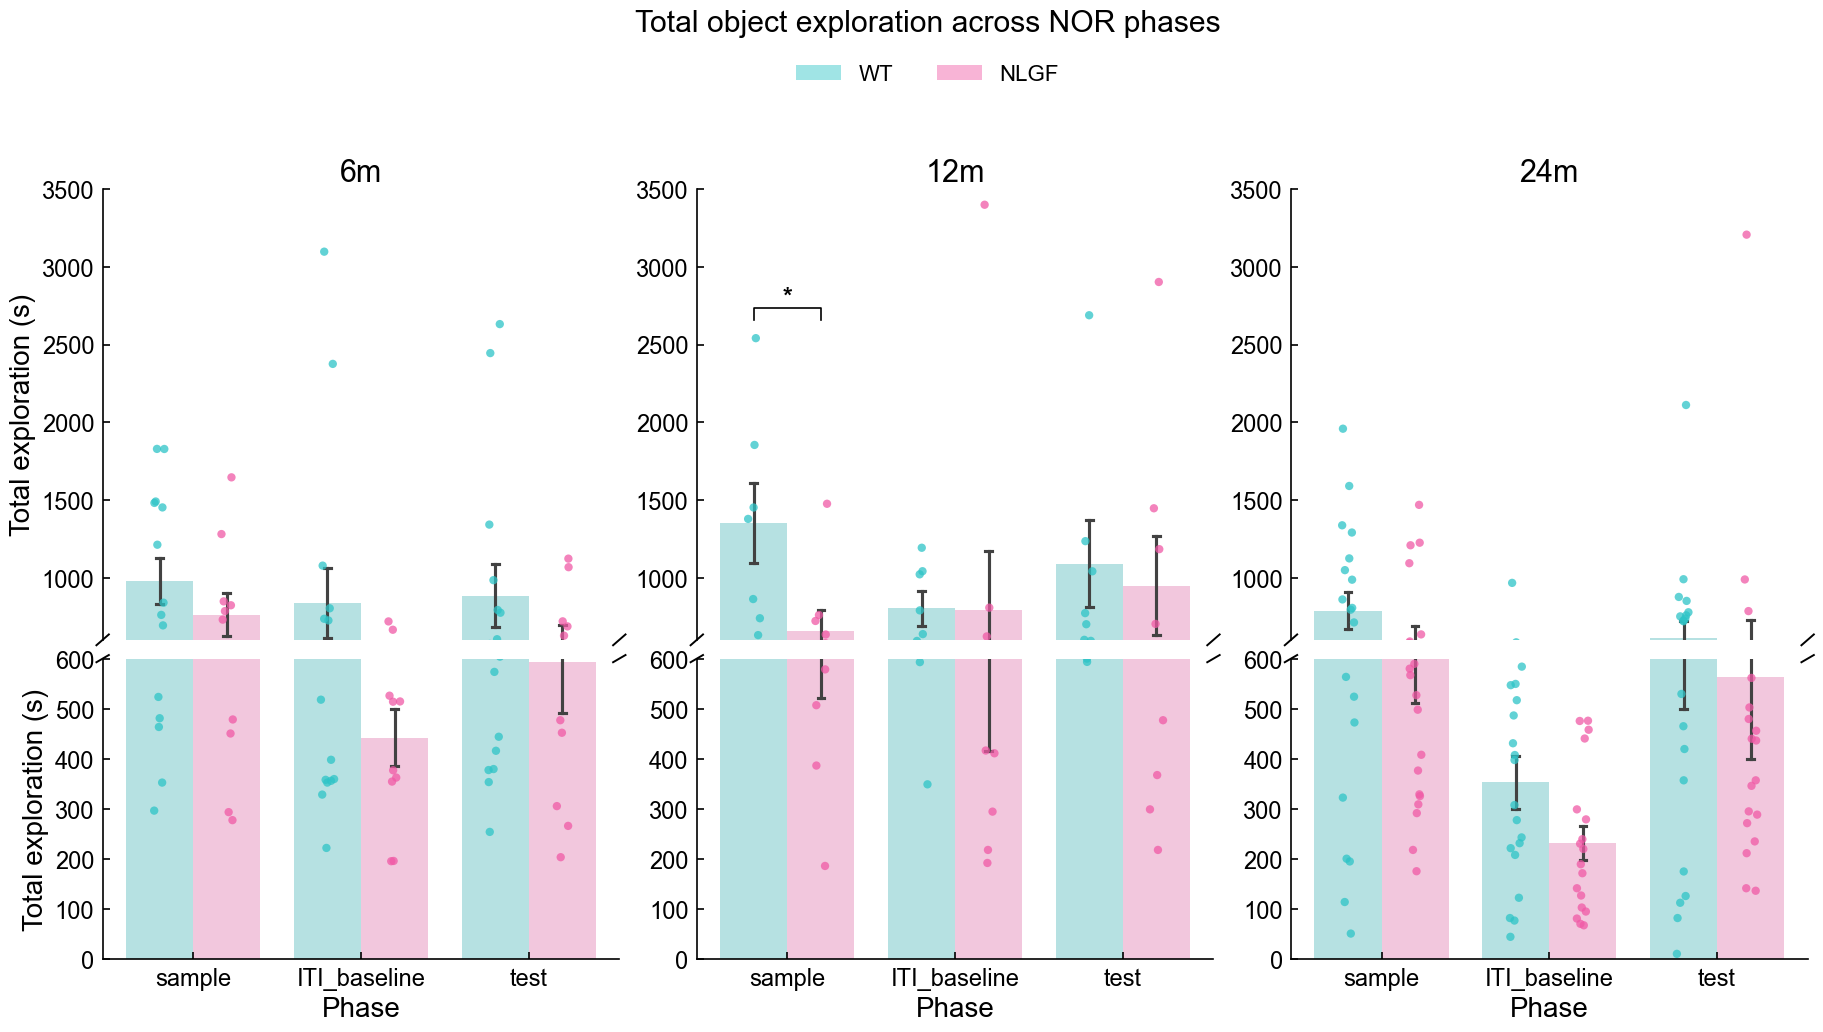

In [ ]:
def plot_total_exploration_broken_axis_thesis(phase_total, stats_df=None):
    fig=plt.figure(figsize=(22,10))
    gs=fig.add_gridspec(2,len(AGE_ORDER),height_ratios=[0.60,0.40],hspace=0.05,wspace=0.15)
    for col,age in enumerate(AGE_ORDER):
        up=fig.add_subplot(gs[0,col]); lo=fig.add_subplot(gs[1,col],sharex=up)
        sub=phase_total[(phase_total["Age"]==age)&phase_total["Genotype"].isin(["WT","NLGF"])].copy()
        for ax in [up,lo]:
            sns.barplot(data=sub,x="Phase",y="total_sec",hue="Genotype",
                        order=PHASE_ORDER,hue_order=["WT","NLGF"],palette=GENO_COLORS,
                        errorbar="se",capsize=0.08,alpha=0.38,ax=ax)
            sns.stripplot(data=sub,x="Phase",y="total_sec",hue="Genotype",
                          order=PHASE_ORDER,hue_order=["WT","NLGF"],palette=GENO_COLORS,
                          dodge=True,jitter=0.08,size=6,alpha=0.75,legend=False,ax=ax)
            if ax.get_legend() is not None: ax.get_legend().remove()
            format_axes(ax)
        lo.set_ylim(0,600); up.set_ylim(600,3500)
        up.spines["bottom"].set_visible(False); lo.spines["top"].set_visible(False)
        up.tick_params(axis="x",bottom=False,labelbottom=False)
        d=.012
        for ax,y0 in [(up,0),(lo,1)]:
            kw=dict(transform=ax.transAxes,color="black",clip_on=False,lw=1.4)
            if ax is up:
                ax.plot((-d,+d),(-d,+d),**kw); ax.plot((1-d,1+d),(-d,+d),**kw)
            else:
                ax.plot((-d,+d),(1-d,1+d),**kw); ax.plot((1-d,1+d),(1-d,1+d),**kw)
        up.set_title(age); lo.set_xlabel("Phase"); up.set_xlabel("")
        up.tick_params(axis="x", bottom=False, labelbottom=False)
        lo.set_ylabel("Total exploration (s)" if col==0 else "")
        up.set_ylabel("Total exploration (s)" if col==0 else "")
        # RAW significance stars in lower/upper segment as appropriate
        if stats_df is not None:
            offsets={"WT":-0.20,"NLGF":0.20}
            for i,phase in enumerate(PHASE_ORDER):
                row=stats_df[(stats_df["Age"]==age)&(stats_df["Phase"]==phase)]
                if row.empty: continue
                star=row.iloc[0]["stars"]
                if star in ("ns","NA",""): continue
                local=pd.to_numeric(sub.loc[sub["Phase"]==phase,"total_sec"],errors="coerce").max()
                ax=lo if local<520 else up
                y=local+35 if ax is lo else local+120
                add_bracket(ax,i+offsets["WT"],i+offsets["NLGF"],y,star,fontsize=18)
    from matplotlib.patches import Patch
    fig.legend([Patch(facecolor=GENO_COLORS[g],alpha=.45,label=g) for g in ["WT","NLGF"]],
               ["WT","NLGF"],loc="upper center",ncol=2,frameon=False, bbox_to_anchor=(0.5, 1.025))
    fig.suptitle("Total object exploration across NOR phases",y=1.06)
    if SAVE_AIMI_OUTPUTS:
        fig.savefig(MASTER_OUTPUT/"THESIS_total_exploration_broken_axis.pdf",
                    bbox_inches="tight",transparent=True)
    plt.show()

if "total_exploration_stats" in globals():
    plot_total_exploration_broken_axis_thesis(phase_total,total_exploration_stats)
